# 맥주 소비자 세그먼트 분석: 맛 프로필 군집화
UIUC STAT 437 팀 프로젝트 (2026.05.01 ~ 05.13). 팀에서 DBSCAN 분석(7장)을 맡았습니다.

**질문:** 맥주의 도수·쓴맛·맛 표현만으로 비슷한 맥주끼리 자연스럽게 묶이는 그룹(군집)이 있는가? 있다면 평점이 높은 그룹은 어떤 특징을 갖는가?
**데이터:** Kaggle *Beer Profile and Ratings*. 맥주 3,197종, 변수 25개. 이 중 도수·쓴맛 지수(IBU)·맛 표현 14개 변수로만 군집을 만들었고, 리뷰 점수는 군집을 만든 뒤 결과를 확인하는 데에만 사용했습니다.

| 부분 | 한 일 | 결과 |
|---|---|---|
| 5장 군집 가능성 확인 | t-SNE(고차원 데이터를 2차원 평면에 펼쳐 보는 시각화)를 설정 12가지로 그려 비교 | 무작위로 흩어진 형태가 아니라 큰 중심 덩어리와 작은 그룹 4~6개로 나타났고, 모양이 불규칙하며 경계가 이어져 있었습니다 |
| 7장 DBSCAN | eps(이웃으로 볼 거리) × min_samples(밀집 영역으로 인정할 최소 개수) 36개 조합 비교 | 실루엣 점수가 가장 높은 설정(0.41)은 맥주의 95.6%를 노이즈로 처리해 사용할 수 없다고 판단했습니다. 노이즈 비율과 t-SNE를 함께 보고 eps 1.8, min_samples 8을 선택했고, 군집 4개와 노이즈 513종(16%)이 나왔습니다 |
| 8장 HAC (계층적 군집) | 이상치를 포함한 경우와 DBSCAN 노이즈를 뺀 경우를 비교 | 이상치 포함 시 k=2의 실루엣이 0.73이었지만 소수의 이상치를 떼어 낸 결과였습니다. 노이즈를 빼자 실루엣은 최대 0.17로 낮아졌고, 해석 가능한 7개 군집으로 정리되었습니다 |
| 9장 K-Means | 엘보·실루엣·t-SNE로 k 선택 | k=6을 선택했고, HAC와 큰 그룹이 비슷하게 나와 결과가 안정적인 것으로 확인되었습니다 |
| 10~11장 비교·결론 | 세 방법 비교, 리뷰 점수로 사후 확인 | 평점이 높은 그룹은 쓴맛이 가장 강한 쪽이 아니라 쓴맛과 다른 풍미가 균형을 이루는 쪽이었습니다. 노이즈 맥주의 평균 평점도 3.88로 낮지 않았습니다 |

### 참고 사항
- **실루엣 점수**는 같은 군집끼리는 가깝고 다른 군집과는 먼 정도를 -1~1로 나타낸 값입니다. 이 프로젝트에서 얻은 가장 큰 교훈은 "지표가 높다고 쓸 수 있는 결과는 아니다"였습니다. 실루엣이 가장 높은 DBSCAN 설정은 대부분을 노이즈로 버린 결과였고, HAC의 0.73도 이상치에 끌려간 값이었습니다.
- **노이즈(이상치)**는 오류가 아니라 개성이 강한 틈새 맥주(예: 아메리칸 발리와인)로 보았고, 지우지 않고 별도 그룹(-1)으로 남겼습니다.
- 기법별 최종 설정, 실루엣, 군집 크기, 군집별 평점은 **10.1의 "기법별 수치 정리" 표**에 모아 두었습니다.
- 리뷰 점수와 군집의 관계는 관찰된 연관이며 인과관계는 아닙니다.

## 1. 서론

### 1.1. 동기
비지도학습은 정답(라벨)이 없는 데이터에서 숨은 패턴과 관계를 찾는 머신러닝 방법으로(IBM, n.d.), 고객의 선호와 행동을 파악하는 비즈니스 도구로 많이 쓰입니다.

이 프로젝트에서는 비지도학습으로 제품의 고객 세그먼트를 이해하는 데 초점을 두었고, 전 세계 주류 중 가장 많이 소비되는 맥주를 대상으로 삼았습니다(Brewers Association, 2026). "Beer Profile and Ratings" 데이터에 내재된 군집 구조가 있는지, 예를 들어 IBU 수준에 따라 묶이는지, 그리고 리뷰로 본 선호가 맥주 유형에 따라 어떻게 다른지 확인하고자 했습니다.

연구 목표는 다음과 같이 정했습니다.
- 데이터에 자연스럽게 존재하는 주요 군집 찾기
- 주요 군집 안의 하위 군집 구조 찾기
- 이상치·노이즈 찾기
- 변수로 각 군집의 특징을 설명하고, 평점이 높은 맥주의 특성 분석
- 군집 간 유사성·차이와 그 이유 파악
- 맥주 특성 변수 간 관계를 찾아, 비슷한 맥주를 추천하는 시스템의 근거 마련

### 1.2. 활용
결과는 양조장 영업 담당자나 맥주 회사 경영진처럼 제품 결정에 관여하는 사람에게 쓸모가 있을 것으로 보았습니다. 군집마다 선호가 다른 소비자 프로필이 드러나기 때문입니다(Ivanova et al., 2023). 예를 들어 "단맛 + 과일 향" 맥주가 많이 모인 군집의 평균 평점이 높다면, 그 세그먼트를 겨냥한 제품을 만들거나 경쟁 제품을 개발할 수 있습니다.

단기적으로는 고객 기대에 맞는 제품을 꾸준히 제공해 재구매율을 높이고, 장기적으로는 고객 만족과 브랜드 충성도를 높여 경쟁이 치열한 시장에서 입지를 다지는 데 활용할 수 있다고 판단했습니다.

### 1.3. 주의할 점
군집 알고리즘 선택과 군집 품질도 함께 따져야 한다고 보았습니다.

내재된 군집을 다 찾지 못하면 맥주 특성 간의 의미 있는 차이를 놓치고, 제품 결정에 중요한 특징이 가려집니다(NIST, 2017).

하위 군집이 많은 데이터에서는 군집을 잘못 나눌 위험도 큽니다. 너무 잘게 나누면(과분할) 관측치 1~2개짜리 군집이 많아져 정보는 적고 차이만 과장되고, 너무 크게 묶으면(과소분할) 서로 다른 두 군집이 하나로 합쳐져 특징 해석이 틀어집니다(Sánchez Vinces et al., 2025). 두 경우 모두 각 군집의 특징을 설명하려는 목표에 맞지 않았습니다.

### 1.4. 목표로 한 군집화 결과
맥주 3,197종 중에는 맛·향·질감 하나로 분류하기 어려운 맥주가 있을 것으로 예상했습니다. 그래서 이런 맥주의 개성은 살리면서, 잘 분류되는 맥주끼리는 뚜렷하게 구분되는 결과를 목표로 했습니다. 즉 각 맥주를 한 군집에 확실히 배정하되(hard assignment), 노이즈를 따로 떼어 낸 결과와 떼어 내지 않은 결과를 비교하기로 했습니다.

### 1.5. 진행 순서
1. Kaggle 원문 설명으로 변수 수, 변수 유형, 수집·구성 방식을 확인했습니다.
2. 데이터를 불러와 결측치, 산점도와 이상치, 노이즈, 수치형 요약, 범주형 빈도를 살펴보고 표준화 여부를 결정했습니다.
3. t-SNE를 perplexity 6가지 × 랜덤 시드 2가지로 그려 기본 군집 구조를 보고, 평균 실루엣 점수 같은 보조 지표로 t-SNE 결과를 점검했습니다.
4. 데이터 특성에 맞는 군집 알고리즘을 골랐습니다.
5. t-SNE와의 일치, 분리도·응집도, 연구 목표와의 부합으로 알고리즘을 비교했습니다.
6. 최종 알고리즘과 결과로 요약, 제언, 후속 과제를 정리했습니다.

## 2. 데이터 소개

### 2.1. 라이브러리 불러오기

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.metrics.pairwise import pairwise_distances
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns
import gower
%matplotlib inline
from scipy.spatial.distance import pdist, squareform
from sklearn.manifold import TSNE
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
import numpy as np
from sklearn.metrics import adjusted_rand_score, silhouette_samples, silhouette_score

### 2.2. 데이터 미리 보기

"Beer Profile and Ratings" 데이터의 처음 5행입니다. Kaggle 설명에 따르면 맥주 3,197종, 변수 25개로 구성되어 있었습니다.

In [3]:
df = pd.read_csv("~/Desktop/STAT 437/Project/beer_profile_and_ratings.csv")
df.head(5)

,Name,Style,Brewery,Beer Name (Full),Description,ABV,Min IBU,Max IBU,Astringency,Body,...,Fruits,Hoppy,Spices,Malty,review_aroma,review_appearance,review_palate,review_taste,review_overall,number_of_reviews
0,Amber,Altbier,Alaskan Brewing Co.,Alaskan Brewing Co. Alaskan Amber,"Notes:Richly malty and long on the palate, wit...",5.3,25,50,13,32,...,33,57,8,111,3.498994,3.636821,3.556338,3.643863,3.847082,497
1,Double Bag,Altbier,Long Trail Brewing Co.,Long Trail Brewing Co. Double Bag,"Notes:This malty, full-bodied double alt is al...",7.2,25,50,12,57,...,24,35,12,84,3.798337,3.846154,3.904366,4.024948,4.034304,481
2,Long Trail Ale,Altbier,Long Trail Brewing Co.,Long Trail Brewing Co. Long Trail Ale,Notes:Long Trail Ale is a full-bodied amber al...,5.0,25,50,14,37,...,10,54,4,62,3.409814,3.667109,3.600796,3.631300,3.830239,377
3,Doppelsticke,Altbier,Uerige Obergärige Hausbrauerei GmbH / Zum Uerige,Uerige Obergärige Hausbrauerei GmbH / Zum Ueri...,Notes:,8.5,25,50,13,55,...,49,40,16,119,4.148098,4.033967,4.150815,4.205163,4.005435,368
4,Sleigh'r Dark Doüble Alt Ale,Altbier,Ninkasi Brewing Company,Ninkasi Brewing Company Sleigh'r Dark Doüble A...,Notes:Called 'Dark Double Alt' on the label.Se...,7.2,25,50,25,51,...,11,51,20,95,3.625000,3.973958,3.734375,3.765625,3.817708,96


In [6]:
df.shape

(3197, 25)

### 2.3. 데이터 출처
Kaggle에 공개된 데이터를 사용했습니다: https://www.kaggle.com/datasets/ruthgn/beer-profile-and-ratings-data-set (Ruthgn, n.d.)

ruthgn이 Kaggle의 두 데이터("Beer Tasting Profiles Dataset" by sp1222, "1.5 Million Beer Reviews" by Tanya Cashorali·Datadoume)를 합쳐 만든 데이터입니다. 마지막 업데이트는 약 4년 전이었고, 프로젝트를 위해 4월 22일에 내려받았습니다.

양조장 934곳의 맥주 3,197종에 대한 맛 프로필과 소비자 리뷰가 들어 있으며, 한 행이 맥주 한 종입니다.

다만 세상의 모든 맥주를 대표하지는 않는다고 보았습니다. 두 데이터를 합칠 때 FuzzyWuzzy(문자열 유사도 매칭)로 이름이 맞춰지지 않은 맥주는 빠졌기 때문에, 덜 알려졌거나 이름 표기가 일관되지 않은 맥주가 누락되었을 수 있습니다. 그래도 맥주 특성과 소비자 선호의 전반적인 패턴을 분석하기에는 충분한 표본으로 판단했습니다.

### 2.4. 사용한 변수

맥주 특성과 평점의 관계를 최대한 살펴보기 위해, 군집을 해석하고 알고리즘을 고르는 데 도움이 되는 설명 변수를 모두 사용했습니다.

다만 범주가 지나치게 잘게 나뉘는 변수는 제외했습니다: Description(자유 서술), Brewery(934곳이 각각 하나의 범주), Style(111종), 맥주 이름(3,197개가 각각 하나의 범주). 최종 사용 변수는 다음과 같습니다.

- 사양: ABV(알코올 도수), Min IBU, Max IBU
- 질감: Astringency(떫은맛), Body(바디감), Alcohol(알코올감)
- 맛: Bitter, Sweet, Sour, Salty
- 풍미·향: Fruits, Hoppy, Spices, Malty
- 리뷰: review_aroma, review_appearance, review_palate, review_taste, review_overall, number_of_reviews

모두 수치형이라 범주형과의 가중치를 고민할 필요는 없었습니다. 맥주의 어떤 특성이 평점·선호와 연결되는지 보는 것이 목적이어서 모든 변수를 같은 중요도로 다뤘습니다. 변수마다 표준편차가 다르면 한 변수가 군집 모양을 좌우할 수 있어 표준화를 검토했고, 거리는 유클리드 거리를 사용했습니다.

자세한 변수 설명과 표준화 과정은 3~4장에 정리했습니다.

## 3. 데이터 정제와 탐색

### 3.1. 기본 정보
양조장 934곳의 맥주 3,197종에 대한 맛 프로필과 소비자 리뷰 데이터입니다. 출처: https://www.kaggle.com/datasets/ruthgn/beer-profile-and-ratings-data-set?resource=download

In [4]:
df_beer = pd.read_csv('~/Desktop/STAT 437/Project/beer_profile_and_ratings.csv')
df_beer.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3197 entries, 0 to 3196
Data columns (total 25 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Name               3197 non-null   object 
 1   Style              3197 non-null   object 
 2   Brewery            3197 non-null   object 
 3   Beer Name (Full)   3197 non-null   object 
 4   Description        3197 non-null   object 
 5   ABV                3197 non-null   float64
 6   Min IBU            3197 non-null   int64  
 7   Max IBU            3197 non-null   int64  
 8   Astringency        3197 non-null   int64  
 9   Body               3197 non-null   int64  
 10  Alcohol            3197 non-null   int64  
 11  Bitter             3197 non-null   int64  
 12  Sweet              3197 non-null   int64  
 13  Sour               3197 non-null   int64  
 14  Salty              3197 non-null   int64  
 15  Fruits             3197 non-null   int64  
 16  Hoppy              3197 

In [5]:
df_beer.columns

Index(['Name', 'Style', 'Brewery', 'Beer Name (Full)', 'Description', 'ABV',
       'Min IBU', 'Max IBU', 'Astringency', 'Body', 'Alcohol', 'Bitter',
       'Sweet', 'Sour', 'Salty', 'Fruits', 'Hoppy', 'Spices', 'Malty',
       'review_aroma', 'review_appearance', 'review_palate', 'review_taste',
       'review_overall', 'number_of_reviews'],
      dtype='object')

### 3.2. 데이터 구성

맥주 기본 정보, 리뷰 글에서 뽑은 맛 프로필 변수, 사용자 평점 집계로 구성되어 있었습니다. 파일은 `beer_profile_and_ratings.csv`(`df_beer`), 변수 25개이며 세 그룹으로 나뉩니다.

#### 3.2.1. 기본 정보
| 번호 | 변수 | 설명 |
| :--- | :--- | :--- |
| 1 | **Name** | 맥주 이름 |
| 2 | **Style** | 맥주 스타일 |
| 3 | **Brewery** | 양조장 이름 |
| 4 | **Beer Name (Full)** | 전체 이름(양조장 + 맥주 이름), **고유 식별자** |
| 5 | **Description** | 맥주 설명(있는 경우) |
| 6 | **ABV** | 알코올 도수(%) |
| 7 | **Min IBU** | 해당 스타일의 최소 IBU(쓴맛 지수) |
| 8 | **Max IBU** | 해당 스타일의 최대 IBU |

#### 3.2.2. 맛 프로필 변수
*맥주당 최대 25개 리뷰에서 특정 표현이 몇 번 언급되었는지 센 값입니다.*

* **질감(Mouthfeel):** `Astringency`, `Body`, `Alcohol`
* **맛(Taste):** `Bitter`, `Sweet`, `Sour`, `Salty`
* **풍미·향(Flavor and Aroma):** `Fruits`, `Hoppy`, `Spices`, `Malty`

#### 3.2.3. 리뷰·평점 (값이 높을수록 긍정적)
| 번호 | 변수 | 설명 |
| :--- | :--- | :--- |
| 20 | **review_aroma** | 향 평균 점수 |
| 21 | **review_appearance** | 외관 평균 점수 |
| 22 | **review_palate** | 입안 느낌 평균 점수 |
| 23 | **review_taste** | 맛 평균 점수 |
| 24 | **review_overall** | 종합 평균 점수 |
| 25 | **number_of_reviews** | 리뷰 수 |

In [6]:
df_beer.head()

,Name,Style,Brewery,Beer Name (Full),Description,ABV,Min IBU,Max IBU,Astringency,Body,...,Fruits,Hoppy,Spices,Malty,review_aroma,review_appearance,review_palate,review_taste,review_overall,number_of_reviews
0,Amber,Altbier,Alaskan Brewing Co.,Alaskan Brewing Co. Alaskan Amber,"Notes:Richly malty and long on the palate, wit...",5.3,25,50,13,32,...,33,57,8,111,3.498994,3.636821,3.556338,3.643863,3.847082,497
1,Double Bag,Altbier,Long Trail Brewing Co.,Long Trail Brewing Co. Double Bag,"Notes:This malty, full-bodied double alt is al...",7.2,25,50,12,57,...,24,35,12,84,3.798337,3.846154,3.904366,4.024948,4.034304,481
2,Long Trail Ale,Altbier,Long Trail Brewing Co.,Long Trail Brewing Co. Long Trail Ale,Notes:Long Trail Ale is a full-bodied amber al...,5.0,25,50,14,37,...,10,54,4,62,3.409814,3.667109,3.600796,3.631300,3.830239,377
3,Doppelsticke,Altbier,Uerige Obergärige Hausbrauerei GmbH / Zum Uerige,Uerige Obergärige Hausbrauerei GmbH / Zum Ueri...,Notes:,8.5,25,50,13,55,...,49,40,16,119,4.148098,4.033967,4.150815,4.205163,4.005435,368
4,Sleigh'r Dark Doüble Alt Ale,Altbier,Ninkasi Brewing Company,Ninkasi Brewing Company Sleigh'r Dark Doüble A...,Notes:Called 'Dark Double Alt' on the label.Se...,7.2,25,50,25,51,...,11,51,20,95,3.625000,3.973958,3.734375,3.765625,3.817708,96


### 3.3. 통계 요약

3,197행 × 25열이었고, 이름·스타일·양조장·설명만 범주형이고 나머지는 수치형이었습니다.

#### 3.3.1. 범주형 변수
* **식별자:** `Name`, `Beer Name (Full)`, `Brewery`
* **설명:** `Style`, `Description`

#### 3.3.2. 수치형 변수
| 구분 | 변수 |
| :--- | :--- |
| **사양** | `ABV`, `Min IBU`, `Max IBU` |
| **맛 프로필 강도** | `Astringency`, `Body`, `Alcohol`(질감); `Bitter`, `Sweet`, `Sour`, `Salty`(맛); `Fruits`, `Hoppy`, `Spices`, `Malty`(풍미) |
| **사용자 평점** | `review_aroma`, `review_appearance`, `review_palate`, `review_taste`, `review_overall` |
| **리뷰 수** | `number_of_reviews` |

**참고:** 평점은 모두 1~5점(높을수록 좋음)입니다. 필요하면 `number_of_reviews`로 가중 평균을 낼 수 있습니다.

#### 3.3.3. 수치형 변수 상세

In [7]:
specific_cols = ['ABV', 'Min IBU', 'Max IBU']
df_beer[specific_cols].describe().round(2)

,ABV,Min IBU,Max IBU
count,3197.00,3197.00,3197.00
mean,6.53,21.18,38.99
std,2.55,13.24,21.36
min,0.00,0.00,0.00
25%,5.00,15.00,25.00
50%,6.00,20.00,35.00
75%,7.60,25.00,45.00
max,57.50,65.00,100.00


In [8]:
profile_features = [
    'Astringency', 'Body', 'Alcohol',           # 질감
    'Bitter', 'Sweet', 'Sour', 'Salty',         # 맛
    'Fruits', 'Hoppy', 'Spices', 'Malty'        # 풍미·향
]

df_beer[profile_features].describe().round(2)

,Astringency,Body,Alcohol,Bitter,Sweet,Sour,Salty,Fruits,Hoppy,Spices,Malty
count,3197.00,3197.00,3197.00,3197.00,3197.00,3197.00,3197.00,3197.00,3197.00,3197.00,3197.00
mean,16.52,46.13,17.06,36.36,58.27,33.15,1.02,38.53,40.92,18.35,75.33
std,10.41,25.95,17.33,25.79,34.28,35.78,2.13,32.30,30.40,23.76,39.91
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,9.00,29.00,6.00,17.00,33.00,11.00,0.00,12.00,18.00,4.00,45.00
50%,14.00,40.00,11.00,31.00,54.00,22.00,0.00,29.00,33.00,10.00,73.00
75%,21.00,58.00,22.00,52.00,77.00,42.00,1.00,60.00,56.00,23.00,103.00
max,81.00,175.00,139.00,150.00,263.00,284.00,48.00,175.00,172.00,184.00,239.00


In [11]:
rating_features = [
    'review_aroma', 'review_appearance', 'review_palate', 
    'review_taste', 'review_overall'
]
df_beer[rating_features].describe().round(2)

,review_aroma,review_appearance,review_palate,review_taste,review_overall
count,3197.00,3197.00,3197.00,3197.00,3197.00
mean,3.64,3.75,3.66,3.70,3.75
std,0.50,0.40,0.45,0.51,0.44
min,1.51,1.57,1.29,1.21,1.14
25%,3.42,3.60,3.47,3.50,3.57
50%,3.72,3.83,3.74,3.79,3.83
75%,3.98,4.00,3.97,4.03,4.03
max,5.00,4.67,5.00,5.00,5.00


In [12]:
volume_features = ['number_of_reviews']
df_beer[volume_features].describe().round(2)

,number_of_reviews
count,3197.00
mean,233.28
std,361.81
min,1.00
25%,23.00
50%,93.00
75%,284.00
max,3290.00


### 3.4. 데이터 활용 목표

사양과 맛 프로필 변수로 맥주의 잠재 군집을 찾는 것을 목표로 했습니다. 여러 군집 알고리즘으로 군집을 찾고, 군집과 평점의 관계를 분석해 평점이 높은 군집이 무엇이고 왜 선호되는지 설명하고자 했습니다.

## 4. 기초 기술통계와 표준화 결정

### 4.1. 결측치 확인

In [18]:
df.isnull().values.any()

np.False_

In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3197 entries, 0 to 3196
Data columns (total 25 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Name               3197 non-null   object 
 1   Style              3197 non-null   object 
 2   Brewery            3197 non-null   object 
 3   Beer Name (Full)   3197 non-null   object 
 4   Description        3197 non-null   object 
 5   ABV                3197 non-null   float64
 6   Min IBU            3197 non-null   float64
 7   Max IBU            3197 non-null   float64
 8   Astringency        3197 non-null   float64
 9   Body               3197 non-null   float64
 10  Alcohol            3197 non-null   float64
 11  Bitter             3197 non-null   float64
 12  Sweet              3197 non-null   float64
 13  Sour               3197 non-null   float64
 14  Salty              3197 non-null   float64
 15  Fruits             3197 non-null   float64
 16  Hoppy              3197 

결측치는 없었고 모든 열에 3,197개 값이 있는 것으로 확인되었습니다. 다음으로 변수의 척도를 확인했습니다.

### 4.2. 표준화

In [267]:
# 군집화에 쓸 14개 변수(사양 3개 + 맛 프로필 11개). 여기서는 원본(표준화 전) 데이터 기준
cluster_features = specific_cols + profile_features
df[cluster_features].shape

(3197, 14)

모든 변수가 수치형이라 인코딩은 필요하지 않았습니다. 변수를 다음처럼 나눠 살펴보았습니다.

| 구분 | 변수 |
| :--- | :--- |
| **사양** | `ABV`, `Min IBU`, `Max IBU` |
| **맛 프로필 강도** | `Astringency`, `Body`, `Alcohol`(질감); `Bitter`, `Sweet`, `Sour`, `Salty`(맛); `Fruits`, `Hoppy`, `Spices`, `Malty`(풍미) |
| **사용자 평점** | `review_aroma`, `review_appearance`, `review_palate`, `review_taste`, `review_overall` |
| **리뷰 수** | `number_of_reviews` |

#### 4.2.1. 사양 변수

In [22]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

In [20]:
specific_cols = ['ABV', 'Min IBU', 'Max IBU']
df_spec = df[specific_cols]
df_spec.describe().round(2)

,ABV,Min IBU,Max IBU
count,3197.00,3197.00,3197.00
mean,6.53,21.18,38.99
std,2.55,13.24,21.36
min,0.00,0.00,0.00
25%,5.00,15.00,25.00
50%,6.00,20.00,35.00
75%,7.60,25.00,45.00
max,57.50,65.00,100.00


In [23]:
scaled_num = scaler.fit_transform(df_spec)
df_spec_scaled = pd.DataFrame(scaled_num, columns=specific_cols)
df_spec_scaled.head()

,ABV,Min IBU,Max IBU
0,-0.481696,0.28848,0.515791
1,0.264397,0.28848,0.515791
2,-0.599501,0.28848,0.515791
3,0.774882,0.28848,0.515791
4,0.264397,0.28848,0.515791


- **ABV:** 알코올 도수(%)
- **Min IBU:** 해당 스타일의 최소 IBU
- **Max IBU:** 해당 스타일의 최대 IBU

세 변수의 범위는 0~100 정도였는데, ABV는 표준편차가 작고 IBU 두 변수는 컸습니다. 그래서 표준화가 필요하다고 판단했습니다.

#### 4.2.2. 맛 프로필 변수

In [24]:
profile_features = [
    'Astringency', 'Body', 'Alcohol',           # 질감
    'Bitter', 'Sweet', 'Sour', 'Salty',         # 맛
    'Fruits', 'Hoppy', 'Spices', 'Malty'        # 풍미·향
]

df_profile = df[profile_features]
df_profile.describe().round(2)

,Astringency,Body,Alcohol,Bitter,Sweet,Sour,Salty,Fruits,Hoppy,Spices,Malty
count,3197.00,3197.00,3197.00,3197.00,3197.00,3197.00,3197.00,3197.00,3197.00,3197.00,3197.00
mean,16.52,46.13,17.06,36.36,58.27,33.15,1.02,38.53,40.92,18.35,75.33
std,10.41,25.95,17.33,25.79,34.28,35.78,2.13,32.30,30.40,23.76,39.91
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,9.00,29.00,6.00,17.00,33.00,11.00,0.00,12.00,18.00,4.00,45.00
50%,14.00,40.00,11.00,31.00,54.00,22.00,0.00,29.00,33.00,10.00,73.00
75%,21.00,58.00,22.00,52.00,77.00,42.00,1.00,60.00,56.00,23.00,103.00
max,81.00,175.00,139.00,150.00,263.00,284.00,48.00,175.00,172.00,184.00,239.00


맛 프로필 변수도 값의 범위가 제각각이었습니다. 일부 변수가 결과를 좌우하지 않도록 비슷한 범위로 표준화했습니다.

In [25]:
scaled_num = scaler.fit_transform(df_profile)
df_profile_scaled = pd.DataFrame(scaled_num, columns=profile_features)
df_profile_scaled.head()

,Astringency,Body,Alcohol,Bitter,Sweet,Sour,Salty,Fruits,Hoppy,Spices,Malty
0,-0.337764,-0.544620,-0.464895,0.412438,0.458897,-0.004066,-0.477041,-0.171238,0.528815,-0.435553,0.893892
1,-0.433834,0.419002,0.054477,-0.130468,-0.095428,-0.479264,-0.477041,-0.449949,-0.194896,-0.267152,0.217253
2,-0.241694,-0.351895,-0.638019,0.218543,-0.445528,-0.619028,-0.477041,-0.883498,0.430127,-0.603954,-0.334083
3,-0.337764,0.341912,0.804681,0.412438,1.246621,-0.423358,-0.008068,0.324247,-0.030416,-0.098752,1.094378
4,0.815081,0.187733,0.516141,0.296101,-0.387178,-0.674933,-0.008068,-0.852530,0.331439,0.069649,0.492921


짝지은 산점도(pairplot)로 맛 변수 사이의 관계를 살펴보았습니다.

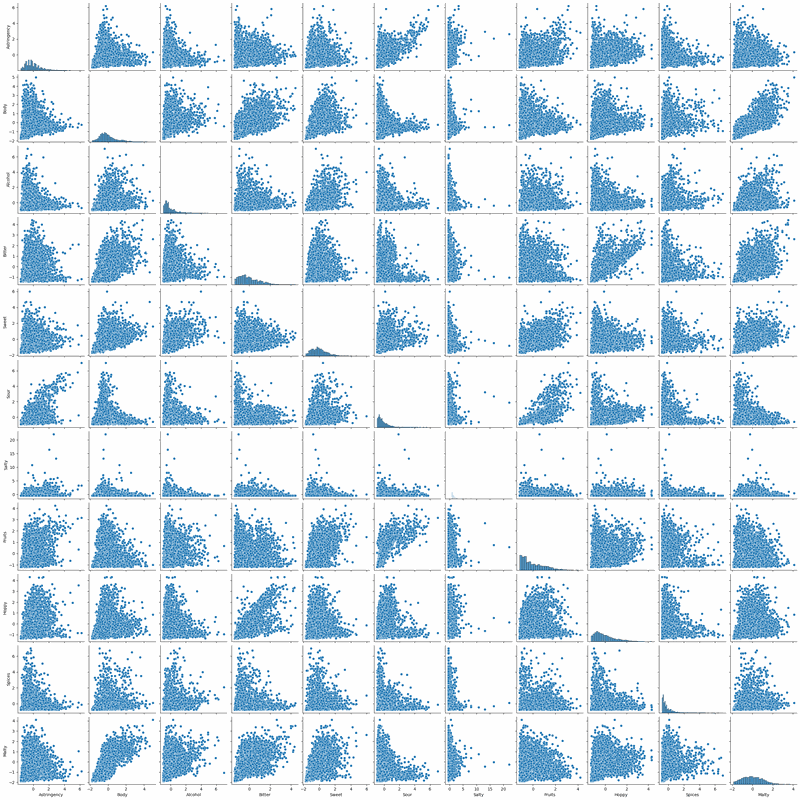

In [26]:
sns.pairplot(df_profile_scaled)
plt.show()

#### 4.2.3. 평점
마지막은 사용자 평점과 리뷰 수입니다. 리뷰 수는 군집화에 쓰지 않을 예정이어서 표준화하지 않았습니다.

In [27]:
rating_features = [
    'review_aroma', 'review_appearance', 'review_palate', 
    'review_taste', 'review_overall'
]
df_rating = df[rating_features]
df_rating.describe().round(2)

,review_aroma,review_appearance,review_palate,review_taste,review_overall
count,3197.00,3197.00,3197.00,3197.00,3197.00
mean,3.64,3.75,3.66,3.70,3.75
std,0.50,0.40,0.45,0.51,0.44
min,1.51,1.57,1.29,1.21,1.14
25%,3.42,3.60,3.47,3.50,3.57
50%,3.72,3.83,3.74,3.79,3.83
75%,3.98,4.00,3.97,4.03,4.03
max,5.00,4.67,5.00,5.00,5.00


평점은 모두 1~5점 범위여서, 평점으로 군집을 만들더라도 표준화는 필요하지 않다고 보았습니다.

### 4.3. 결론

표준화한 사양 변수와 맛 프로필 변수로 군집화를 진행하기로 했습니다. 아래 코드는 표준화 결과를 `cleaned_Beer_data.csv`로 저장하며, 5장부터는 이 파일을 불러옵니다. 리뷰 변수는 표준화하지 않고 원래 점수(1~5점)를 그대로 두었습니다.

In [ ]:
# 표준화한 사양·맛 프로필 변수로 정제 데이터 만들기 (리뷰 변수는 원래 점수 유지)
df_clean = df.copy()
df_clean[specific_cols] = df_spec_scaled.values
df_clean[profile_features] = df_profile_scaled.values
df_clean.to_csv("~/Desktop/STAT 437/Project/cleaned_Beer_data.csv", index=False)
df_clean.shape

(3197, 25)

## 5. t-SNE로 군집 가능성 확인

### 5.1. 분석 변수 정하기

In [13]:
df = pd.read_csv("~/Desktop/STAT 437/Project/cleaned_Beer_data.csv")
df.head()

specific_cols = ['ABV', 'Min IBU', 'Max IBU']

profile_features = [
    'Astringency', 'Body', 'Alcohol',
    'Bitter', 'Sweet', 'Sour', 'Salty',
    'Fruits', 'Hoppy', 'Spices', 'Malty'
]

# 군집 가능성 확인에 쓸 주요 변수
cluster_features = specific_cols + profile_features

X = df[cluster_features].copy()

X = X.select_dtypes(include=[np.number])

# cleaned_Beer_data.csv는 4장에서 표준화해 저장한 데이터라 그대로 사용
X_scaled = X.copy()
X.head()

,ABV,Min IBU,Max IBU,Astringency,Body,Alcohol,Bitter,Sweet,Sour,Salty,Fruits,Hoppy,Spices,Malty
0,-0.481696,0.28848,0.515791,-0.337764,-0.544620,-0.464895,0.412438,0.458897,-0.004066,-0.477041,-0.171238,0.528815,-0.435553,0.893892
1,0.264397,0.28848,0.515791,-0.433834,0.419002,0.054477,-0.130468,-0.095428,-0.479264,-0.477041,-0.449949,-0.194896,-0.267152,0.217253
2,-0.599501,0.28848,0.515791,-0.241694,-0.351895,-0.638019,0.218543,-0.445528,-0.619028,-0.477041,-0.883498,0.430127,-0.603954,-0.334083
3,0.774882,0.28848,0.515791,-0.337764,0.341912,0.804681,0.412438,1.246621,-0.423358,-0.008068,0.324247,-0.030416,-0.098752,1.094378
4,0.264397,0.28848,0.515791,0.815081,0.187733,0.516141,0.296101,-0.387178,-0.674933,-0.008068,-0.852530,0.331439,0.069649,0.492921


In [14]:
X.describe().round(3)

,ABV,Min IBU,Max IBU,Astringency,Body,Alcohol,Bitter,Sweet,Sour,Salty,Fruits,Hoppy,Spices,Malty
count,3197.000,3197.000,3197.000,3197.000,3197.000,3197.000,3197.000,3197.000,3197.000,3197.000,3197.000,3197.000,3197.000,3197.000
mean,0.000,0.000,0.000,0.000,-0.000,-0.000,-0.000,0.000,-0.000,-0.000,-0.000,-0.000,-0.000,-0.000
std,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
min,-2.563,-1.600,-1.826,-1.587,-1.778,-0.984,-1.410,-1.700,-0.927,-0.477,-1.193,-1.346,-0.772,-1.888
25%,-0.600,-0.467,-0.655,-0.722,-0.660,-0.638,-0.751,-0.737,-0.619,-0.477,-0.822,-0.754,-0.604,-0.760
50%,-0.207,-0.089,-0.187,-0.242,-0.236,-0.349,-0.208,-0.125,-0.312,-0.477,-0.295,-0.261,-0.351,-0.058
75%,0.421,0.288,0.282,0.431,0.458,0.285,0.606,0.546,0.248,-0.008,0.665,0.496,0.196,0.693
max,20.016,3.310,2.857,6.195,4.967,7.037,4.407,5.973,7.012,22.034,4.226,4.312,6.974,4.102


### 5.2. t-SNE 그래프

In [157]:
perplexity_values = [5, 10, 20, 30, 40, 50]
random_states = [33, 437]

tsne_results = {}

for perp in perplexity_values:
    for rs in random_states:
        tsne = TSNE(
            n_components=2,
            perplexity=perp,
            random_state=rs,
            init="random",
            learning_rate="auto",
            max_iter=1000
        )
        
        tsne_embedding = tsne.fit_transform(X_scaled)
        
        temp_df = df.copy()
        temp_df["tsne_x"] = tsne_embedding[:, 0]
        temp_df["tsne_y"] = tsne_embedding[:, 1]
        
        tsne_results[(perp, rs)] = temp_df

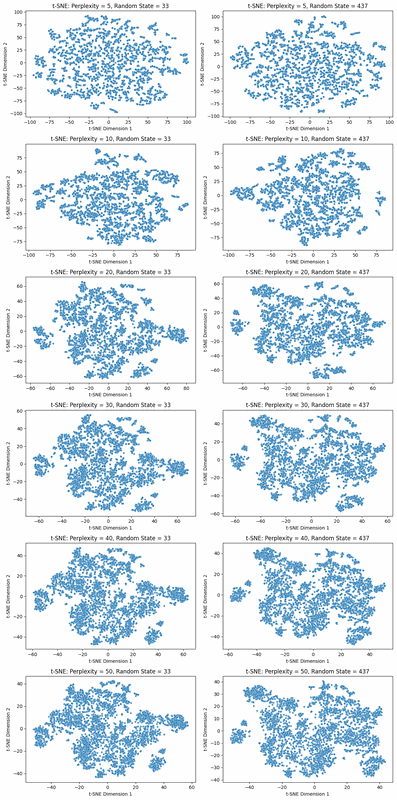

In [158]:
fig, axes = plt.subplots(len(perplexity_values), len(random_states), figsize=(12, 24))

for i, perp in enumerate(perplexity_values):
    for j, rs in enumerate(random_states):
        ax = axes[i, j]
        temp_df = tsne_results[(perp, rs)]
        
        sns.scatterplot(
            data=temp_df,
            x="tsne_x",
            y="tsne_y",
            s=18,
            alpha=0.75,
            ax=ax
        )
        
        ax.set_title(f"t-SNE: Perplexity = {perp}, Random State = {rs}")
        ax.set_xlabel("t-SNE Dimension 1")
        ax.set_ylabel("t-SNE Dimension 2")

plt.tight_layout()
plt.show()

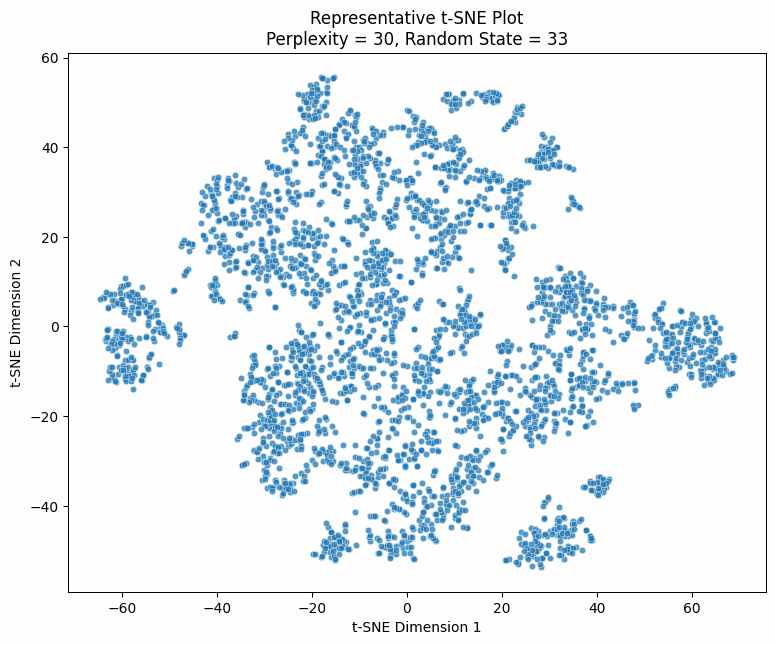

In [159]:
representative_perplexity = 30
representative_random_state = 33
df_tsne = tsne_results[(representative_perplexity, representative_random_state)].copy()
plt.figure(figsize=(9, 7))
sns.scatterplot(
    data=df_tsne,
    x="tsne_x",
    y="tsne_y",
    s=22,
    alpha=0.75
)

plt.title(
    f"Representative t-SNE Plot\n"
    f"Perplexity = {representative_perplexity}, Random State = {representative_random_state}"
)
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.show()

perplexity 6가지(t-SNE가 이웃을 몇 개 정도로 볼지 정하는 값) × 랜덤 시드 2가지로 그린 결과, 이 데이터는 군집화할 만한 구조가 있다고 판단했습니다. 대부분의 그래프에서 점들이 무작위로 흩어져 있지 않았고, 밀집된 영역, 떨어진 작은 그룹, 그룹 사이의 빈 공간이 보였습니다. 설정을 바꿔도 같은 패턴이 반복되어 특정 설정 하나 때문에 생긴 구조는 아니라고 보았습니다.

- **대표 그래프:** perplexity 30~40에서 구조가 가장 잘 보였습니다. perplexity 5처럼 낮으면 아주 가까운 이웃만 강조되어 그래프가 잘게 쪼개졌고, 높아질수록 큰 구조가 드러났습니다. 그래서 큰 그룹과 작은 하위 그룹이 함께 보이는 perplexity 30을 대표로 사용했습니다.
- **군집 수:** 군집을 얼마나 넓게 정의하느냐에 따라 대략 4~6개의 주요 군집이 있는 것으로 보았습니다. 큰 중심 덩어리 하나가 있었지만 그 안에도 더 밀집된 부분이 여러 개 있었고, 바깥쪽(왼쪽, 오른쪽, 왼쪽 위, 오른쪽 아래)에 더 떨어진 작은 그룹이 있었습니다.
- **모양:** 군집이 둥글지 않고 휘거나 길쭉하거나 서로 일부 이어져 있었습니다. 둥글고 크기가 비슷한 군집에 잘 맞는 K-Means 같은 중심 기반 방법의 가정과는 맞지 않을 수 있어, 밀도 기반 방법이 더 적합할 수 있다고 판단했습니다.
- **크기:** 군집 크기가 고르지 않았습니다. 흔한 맥주 프로필이 큰 덩어리를 이루고, 특수한 프로필이 작은 그룹을 이루는 것으로 보았습니다.
- **분리:** 바깥 그룹은 중심과 떨어져 있었지만, 중심부에서는 한 영역이 다른 영역으로 점차 이어졌습니다. 쓴맛·단맛·몰트·과일 향·도수가 칸으로 딱 나뉘기보다 연속적으로 변하는 맥주가 많다는 뜻으로 해석했습니다.
- **중첩 구조:** 큰 영역 안에 작은 밀집 영역이 있었고, perplexity에 따라 큰 영역이 하위 그룹으로 나뉘었습니다. 큰 맥주 유형 안에 세부 유형이 있을 수 있다고 보았습니다.

### 5.3. 군집 구조와 변수의 관계

**대표 t-SNE 그래프를 변수별로 색칠하기**

In [271]:
def plot_tsne_by_numeric_attribute(data, attribute):
    plt.figure(figsize=(9, 7))
    
    scatter = plt.scatter(
        data["tsne_x"],
        data["tsne_y"],
        c=data[attribute],
        s=22,
        alpha=0.75
    )
    
    plt.colorbar(scatter, label=attribute)
    plt.title(f"Representative t-SNE Plot Colored by {attribute}")
    plt.xlabel("t-SNE Dimension 1")
    plt.ylabel("t-SNE Dimension 2")
    plt.show()

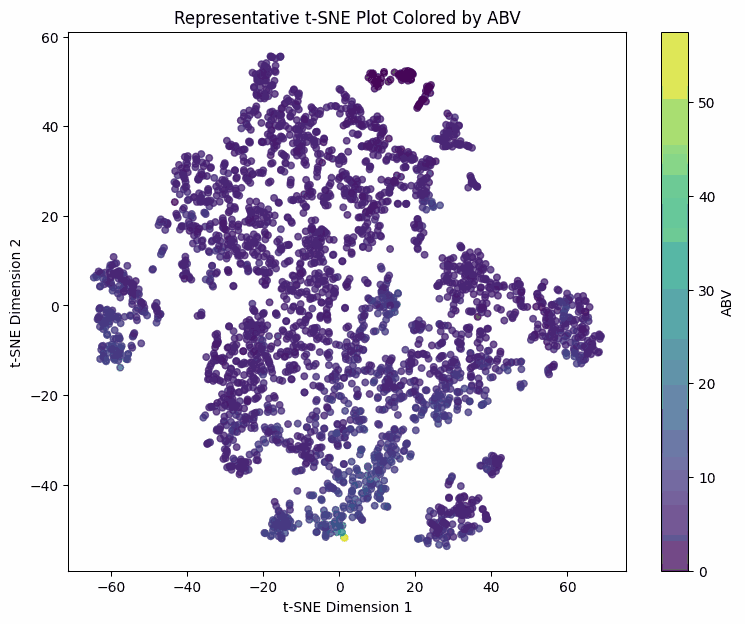

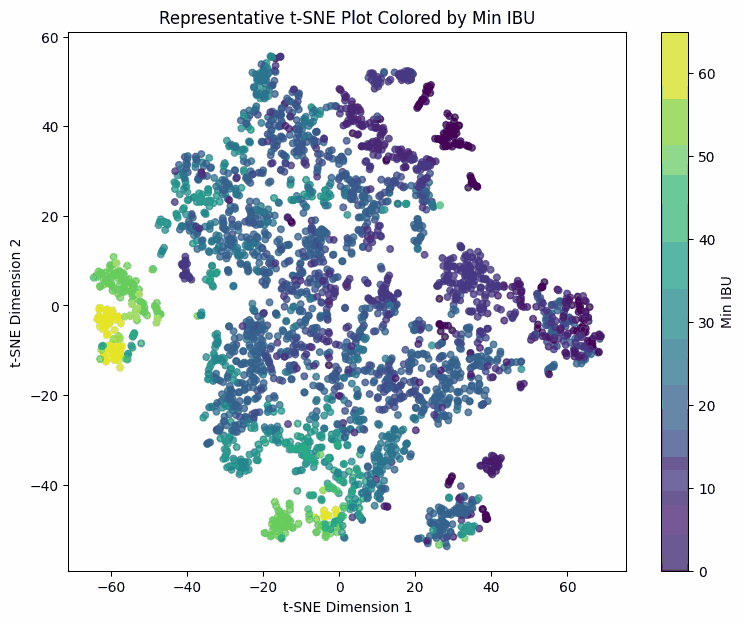

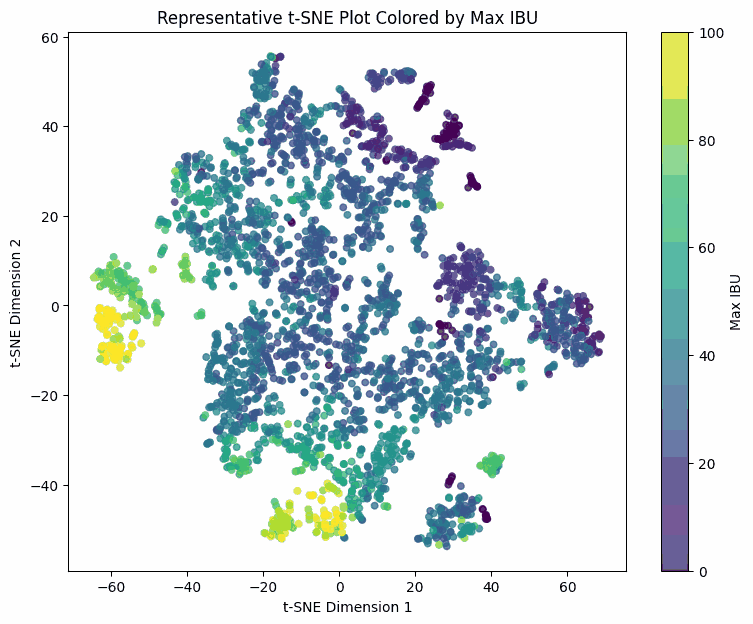

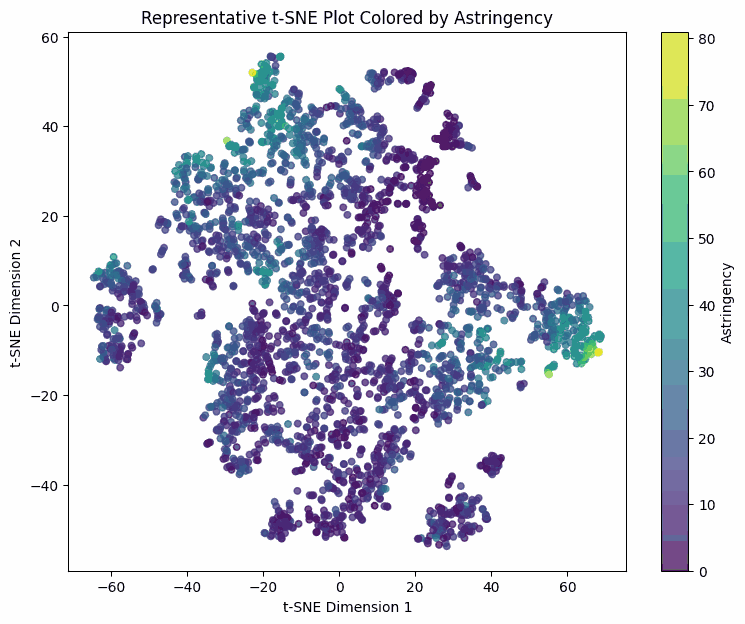

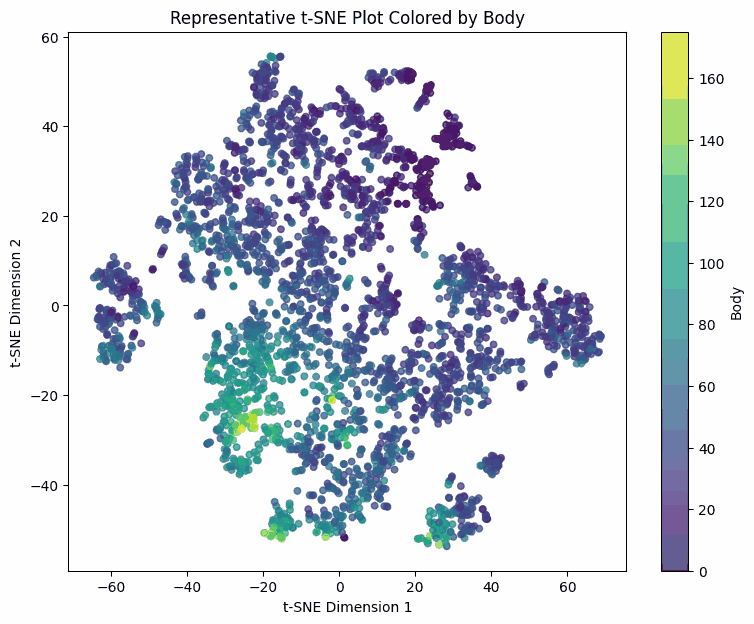

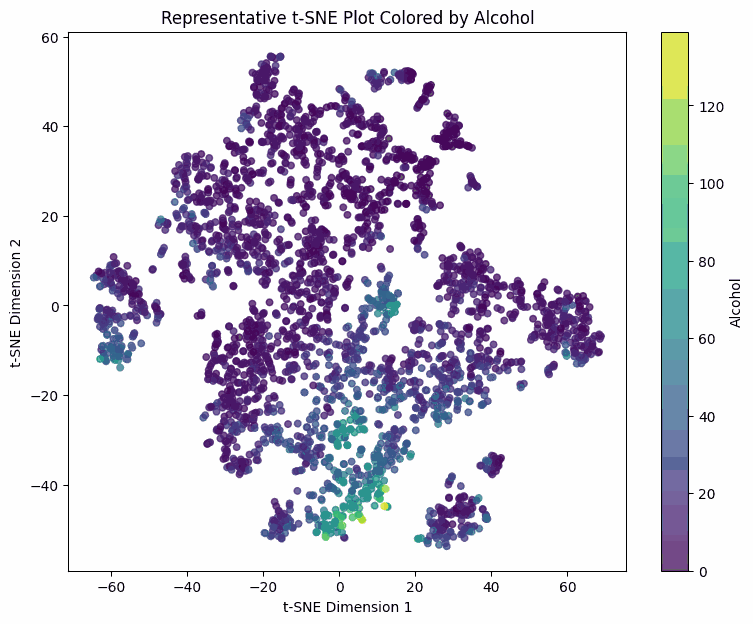

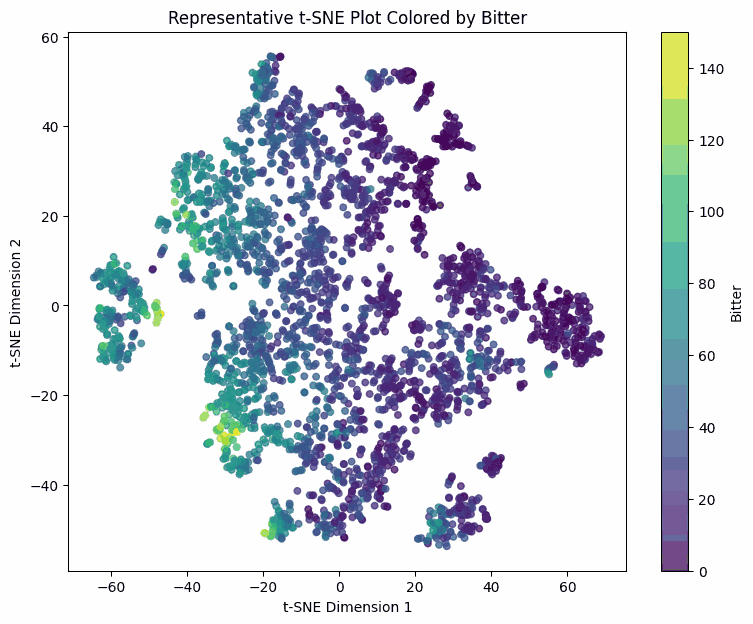

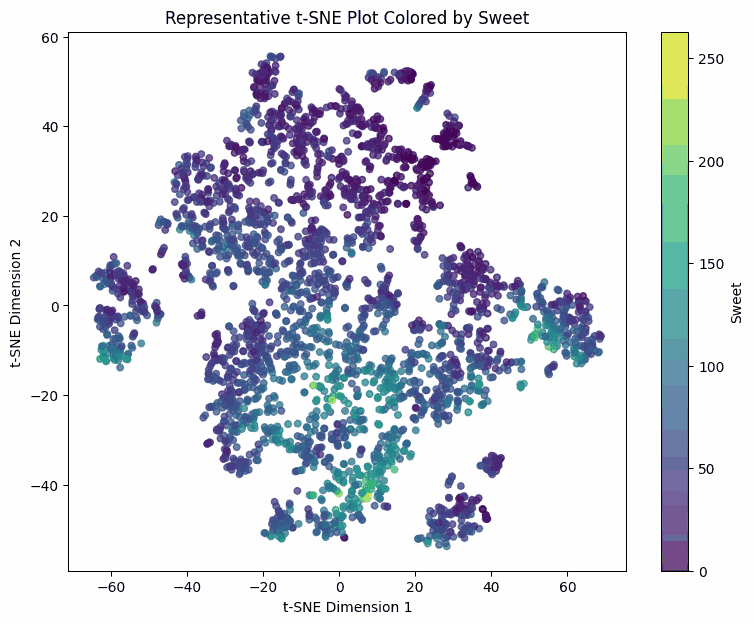

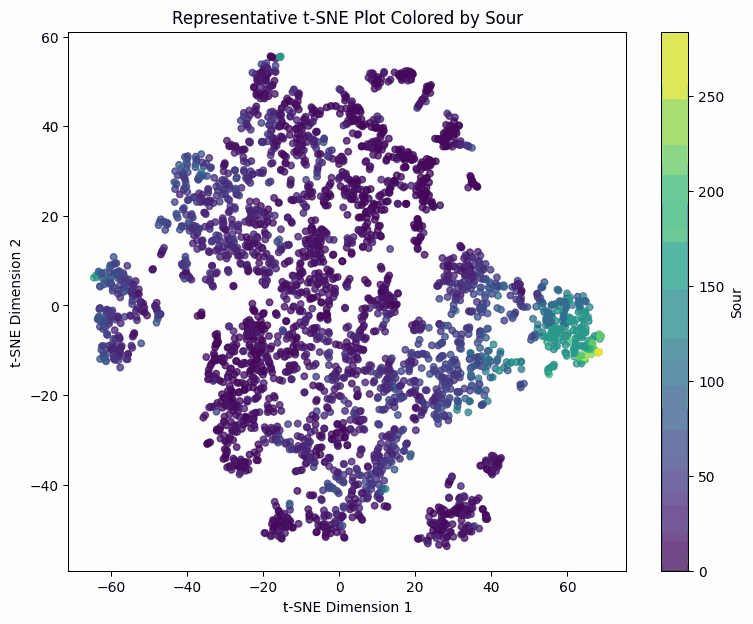

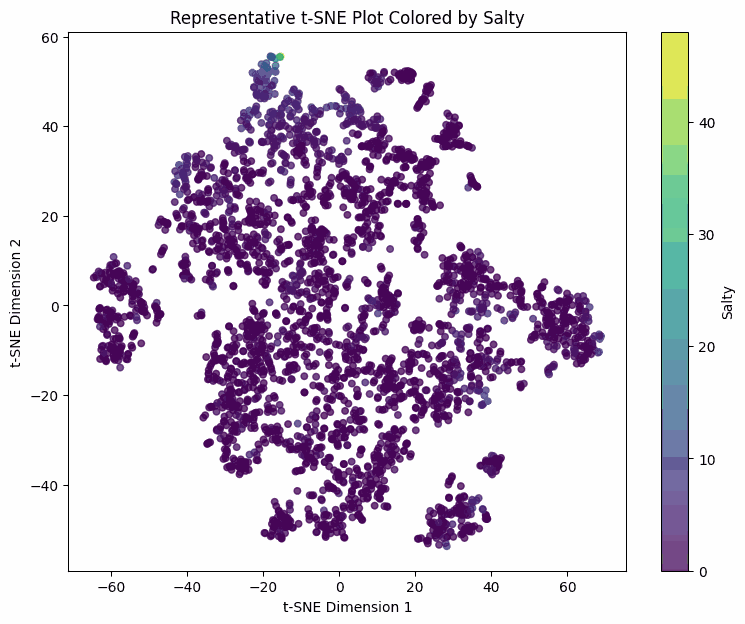

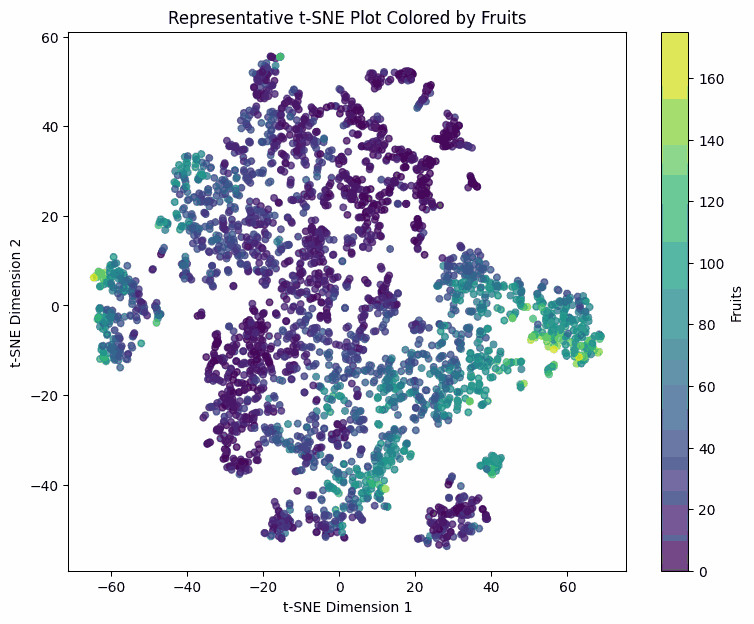

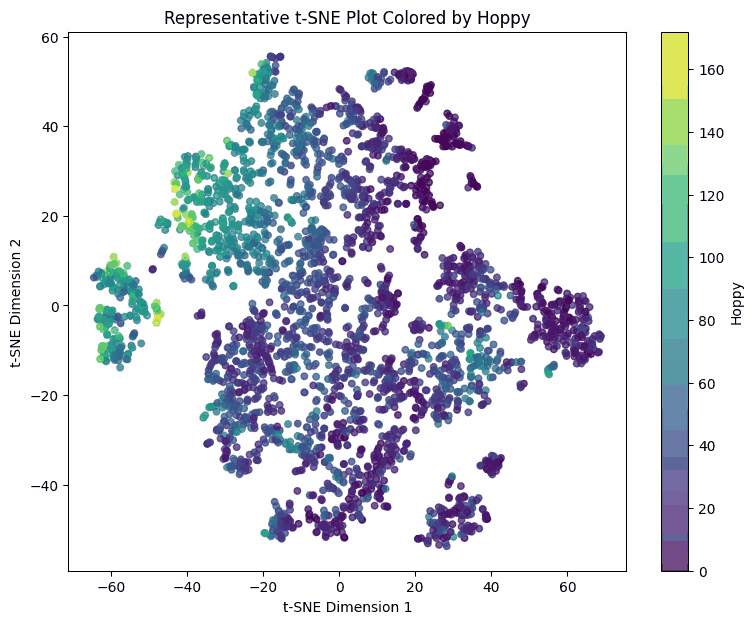

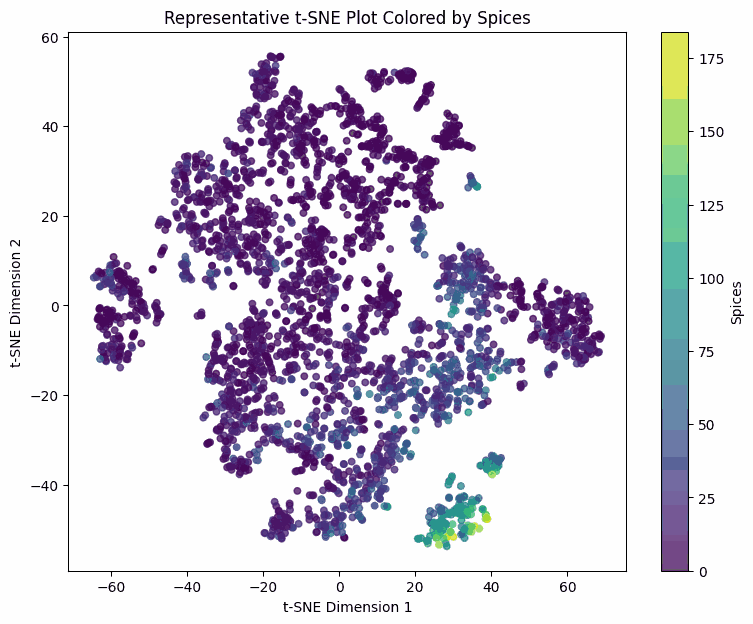

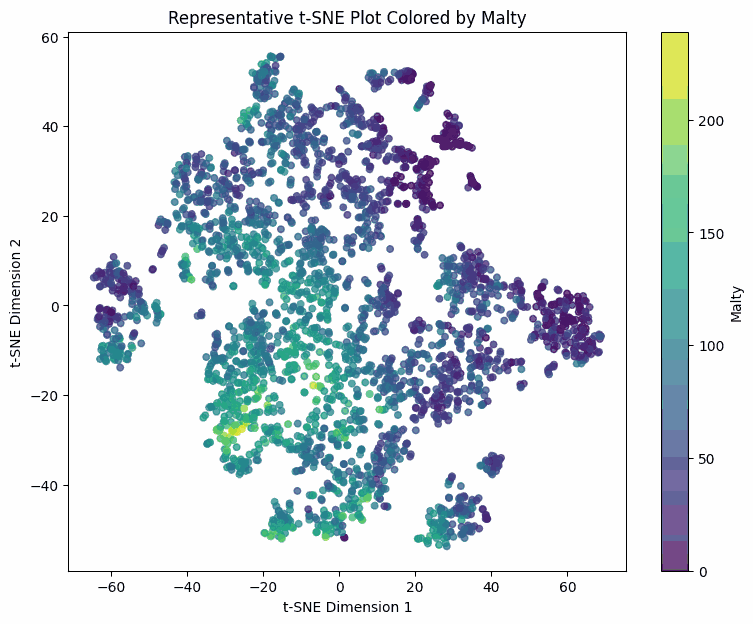

In [272]:
for col in cluster_features:
    plot_tsne_by_numeric_attribute(df_tsne, col)

**평점 변수 확인**

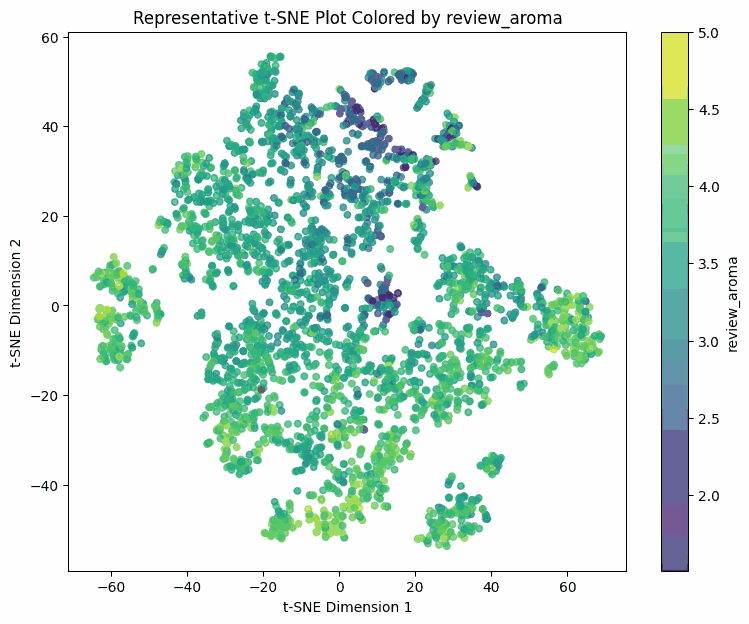

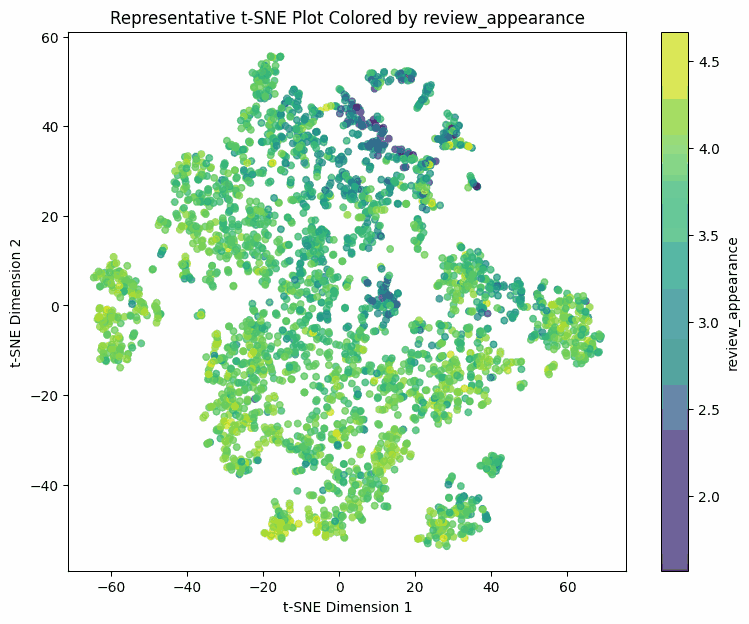

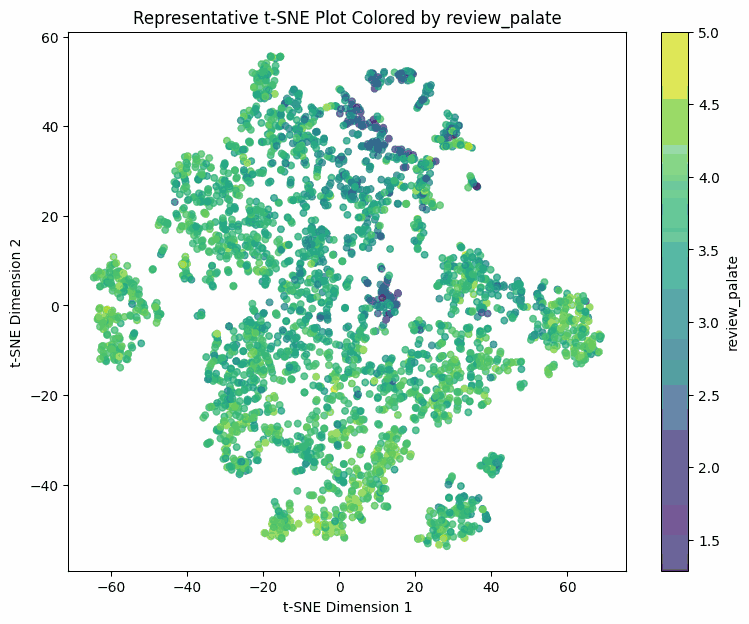

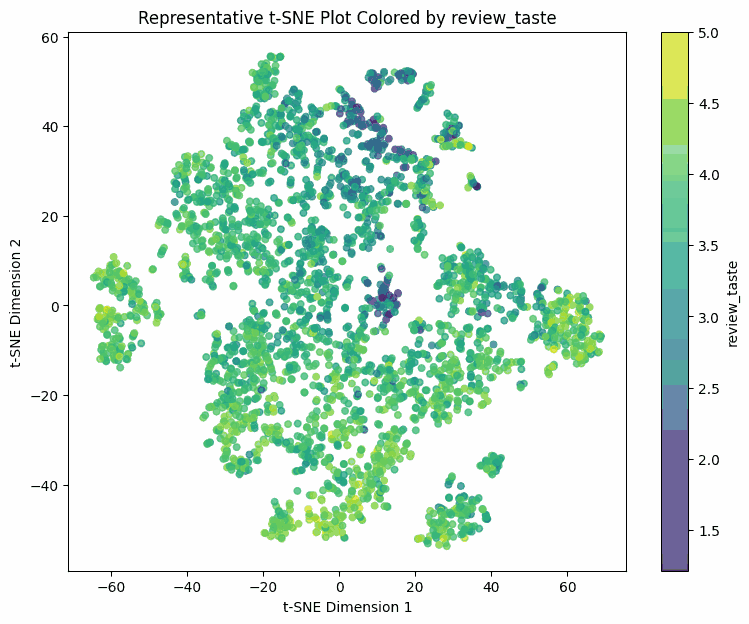

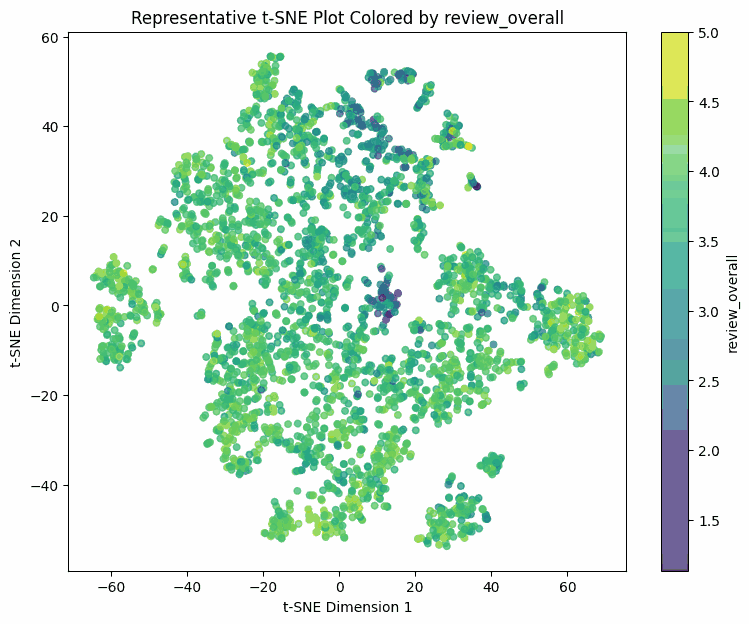

In [273]:
rating_features = [
    'review_aroma', 'review_appearance', 'review_palate',
    'review_taste', 'review_overall'
]

for col in rating_features:
    if col in df_tsne.columns:
        plot_tsne_by_numeric_attribute(df_tsne, col)

**리뷰 수**

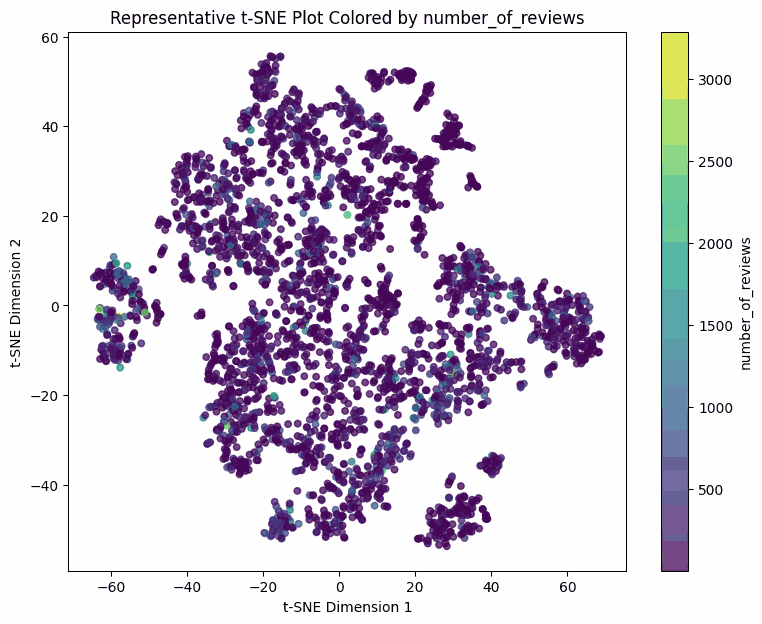

In [274]:
if "number_of_reviews" in df_tsne.columns:
    plot_tsne_by_numeric_attribute(df_tsne, "number_of_reviews")

무엇이 t-SNE 구조를 만드는지 보기 위해, 대표 그래프를 사양·맛 변수별로 색칠했습니다. 같은 그래프를 변수마다 다르게 색칠해, 그 변수가 시각적 구조와 연결되는지 확인하는 방법입니다.

전반적으로 Min IBU, Max IBU, Bitter, Hoppy, Sour, Fruits, Spices, Malty, Body, Sweet, Alcohol, ABV가 구조와 강하게 연결된 것으로 나타났습니다. 다만 연결 강도는 변수마다 달랐습니다.

**IBU·쓴맛 관련 구조**

가장 뚜렷한 변수는 Min IBU, Max IBU, Bitter, Hoppy였습니다. 네 변수 모두 값이 높은 맥주는 주로 왼쪽과 왼쪽 아래에, 낮은 맥주는 오른쪽(특히 맨 오른쪽 군집)에 모였습니다. 쓴맛·홉 향이 강한 맥주와 약한 맥주의 차이가 군집 구조의 큰 축이라고 판단했습니다.

특히 IBU는 맨 왼쪽 그룹에서 매우 높았고, 가운데 아래·왼쪽 아래도 비교적 높았습니다. Bitter와 Hoppy가 높은 영역도 IBU가 높은 영역과 겹쳐, 쓴맛이 강하고 홉이 두드러진 맥주가 하나의 의미 있는 영역을 이룬다고 보았습니다.

**신맛·과일 향 관련 구조**

Sour와 Fruits도 뚜렷했습니다. 맨 오른쪽 군집은 신맛과 과일 향이 중심·위쪽 영역보다 눈에 띄게 높아, 신맛이나 과일 향이 강한 맥주 그룹으로 보았습니다. 과일 향은 오른쪽 군집과 가운데 아래 일부에서 높았고, 신맛은 특히 맨 오른쪽에 몰려 있었습니다. 신맛은 오른쪽 군집을 나머지와 가르는 가장 강한 변수 중 하나로 판단했습니다.

**몰트·바디감·단맛 관련 구조**

Malty, Body, Sweet도 영역별 차이가 보였습니다. Malty와 Body는 주로 왼쪽 아래·가운데 아래에서 높았고, Sweet도 가운데 아래에서 높았지만 조금 더 퍼져 있었습니다.

바디감이 묵직하고 달며 몰트가 두드러진 맥주가 또 하나의 영역을 이룬다고 보았습니다. 다른 그룹과 완전히 떨어져 있지는 않았지만 전체 구조에 기여하고 있었습니다.

**알코올감·도수 관련 구조**

Alcohol과 ABV는 관련은 있었지만 더 국소적이었습니다. 둘 다 가운데 아래 영역에서 높았지만, IBU·쓴맛·홉·신맛·과일 향만큼 그래프 전체에 걸쳐 나타나지는 않았습니다. 도수는 모든 그룹을 가르는 주요 요인이라기보다, 도수가 높은 작은 영역을 구분하는 데 중요한 변수로 판단했습니다.

**떫은맛·향신료·짠맛 관련 구조**

Astringency(떫은맛)는 맨 오른쪽에서 강하게 나타났고, 신맛·과일 향 영역과 일부 겹쳤습니다. Spices(향신료)는 오른쪽 아래 그룹에 뚜렷하게 몰려 있어, 이 그룹을 향신료가 두드러진 하위 그룹으로 보았습니다.

반면 Salty(짠맛)는 전체 구조와 거의 관련이 없었습니다. 대부분 값이 낮고 소수의 맥주만 높아, 군집을 만드는 주요 요인이 아니라고 판단했습니다.

## 6. 군집 알고리즘 선택 기준

5장 t-SNE에서 확인한 데이터 특성을 바탕으로, 원리가 서로 다른 알고리즘 세 가지를 골라 비교했습니다.

| 데이터 특성 (5장) | 고른 알고리즘 | 이유 |
|---|---|---|
| 모양이 불규칙하고 이상치·틈새 맥주가 있음 | **DBSCAN** (밀도 기반) | 군집 수와 모양을 미리 정하지 않고, 밀집 영역에 속하지 않는 점을 노이즈로 따로 떼어 낼 수 있음 |
| 큰 그룹 안에 하위 그룹이 있는 중첩 구조 | **HAC complete linkage** (계층적) | 덴드로그램(군집이 합쳐지는 과정을 나무 모양으로 그린 그림)으로 큰 그룹과 하위 그룹을 함께 볼 수 있음 |
| 시장 세분화처럼 모든 맥주를 그룹에 배정해야 하는 활용 | **K-Means** (중심 기반) | 해석이 쉽고, 다른 방법의 결과가 안정적인지 교차 확인하는 기준이 됨 |

## 7. 군집 알고리즘 1: DBSCAN

### 7.1. k-거리 그래프

In [275]:
from sklearn.neighbors import NearestNeighbors
import numpy as np
import matplotlib.pyplot as plt

dbscan_cols = ['ABV', 'Min IBU', 'Max IBU',
    'Astringency', 'Body', 'Alcohol', 'Bitter', 'Sweet',
    'Sour', 'Salty', 'Fruits', 'Hoppy', 'Spices', 'Malty']

X = df[dbscan_cols]

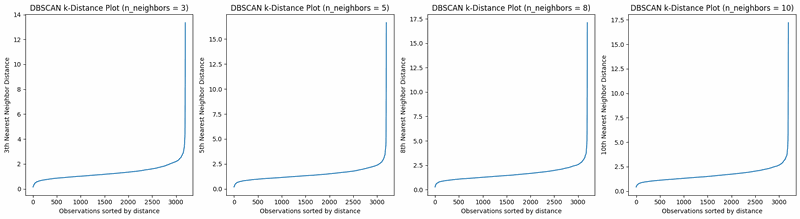

In [276]:
n_neighbors_list = [3,5,8,10]
fig, axes = plt.subplots(1,4, figsize = (18,5))

for i,n in enumerate(n_neighbors_list):
    neighbors = NearestNeighbors(n_neighbors = n)
    neighbors_fit = neighbors.fit(X)

    distances, indicies = neighbors_fit.kneighbors(X)
    kth_distances = np.sort(distances[:, n-1])
    axes[i].plot(kth_distances)
    axes[i].set_xlabel("Observations sorted by distance")
    axes[i].set_ylabel(f"{n}th Nearest Neighbor Distance")
    axes[i].set_title(f"DBSCAN k-Distance Plot (n_neighbors = {n})")

plt.tight_layout()
plt.show()

### 7.2. DBSCAN 평균 실루엣 점수

In [277]:
eps_values = [0.8, 1.0, 1.2, 1.4, 1.6, 1.8, 2.0, 2.2, 2.4]
min_samples_values = [3, 5, 8, 10]

dbscan_results = []
for eps in eps_values:
    for min_samples in min_samples_values:
        dbscan = DBSCAN(eps=eps, min_samples = min_samples)
        labels = dbscan.fit_predict(X)

        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = list(labels).count(-1)
        noise_percent = n_noise /len(labels)

        if n_clusters >= 2:
            non_noise = labels != -1
            score = silhouette_score(X[non_noise], labels[non_noise])
        else:
            score = None
        
        dbscan_results.append({
            "eps": eps,
            "min_samples": min_samples,
            "n_clusters": n_clusters,
            "n_noise": n_noise,
            "noise_percent": noise_percent,
            "silhouette_score": score
        })

dbscan_results_df = pd.DataFrame(dbscan_results)

dbscan_results_df

,eps,min_samples,n_clusters,n_noise,noise_percent,silhouette_score
0,0.8,3,50,2709,0.847357,-0.030017
1,0.8,5,13,2886,0.902721,0.012185
2,0.8,8,6,3015,0.943072,0.238171
3,0.8,10,3,3055,0.955583,0.412475
4,1.0,3,63,2021,0.632155,-0.177453
5,1.0,5,14,2341,0.732249,-0.173547
6,1.0,8,6,2538,0.793869,-0.020101
7,1.0,10,6,2653,0.829840,0.048880
8,1.2,3,57,1352,0.422896,-0.152886
9,1.2,5,22,1650,0.516109,-0.130519


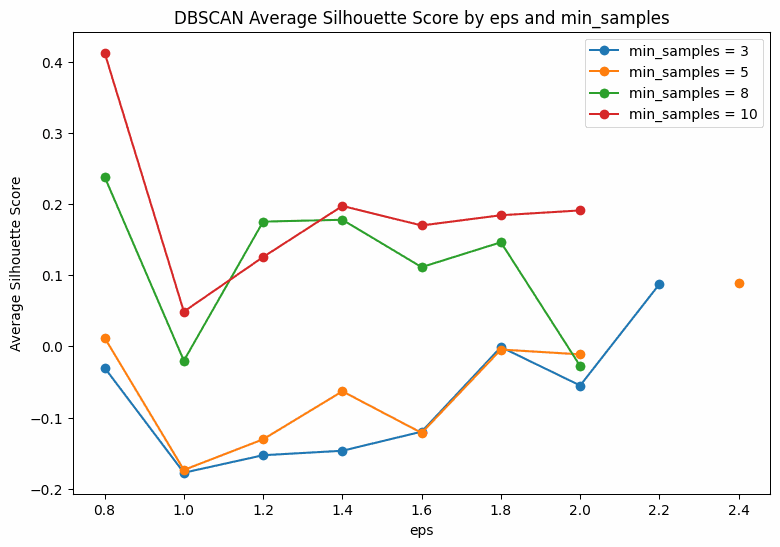

In [278]:
plt.figure(figsize=(9, 6))

for min_samples in min_samples_values:
    temp = dbscan_results_df[
        dbscan_results_df["min_samples"] == min_samples
    ]
    
    plt.plot(
        temp["eps"],
        temp["silhouette_score"],
        marker="o",
        label=f"min_samples = {min_samples}"
    )

plt.xlabel("eps")
plt.ylabel("Average Silhouette Score")
plt.title("DBSCAN Average Silhouette Score by eps and min_samples")
plt.legend()
plt.show()

### 7.3. 파라미터 탐색 결과

DBSCAN에서 `eps`는 "이 거리 안에 있으면 이웃"으로 보는 반지름이고, `min_samples`는 "이웃이 이만큼 있어야 밀집 영역"으로 인정하는 최소 개수입니다. 어느 밀집 영역에도 속하지 못한 점은 노이즈(-1)가 됩니다.

- **k-거리 그래프:** 이웃 수 3, 5, 8, 10으로 각 점에서 k번째로 가까운 이웃까지의 거리를 정렬해 그렸습니다. 대부분 평평하다가 끝에서 급격히 올라가, 적당한 eps는 약 1.8~2.6으로 보았습니다. min_samples가 클수록 적절한 eps도 커졌는데, 이웃을 더 많이 요구하면 반지름도 넓어져야 하므로 예상한 결과였습니다.
- **트레이드오프:** eps가 작으면 군집은 많아지지만 노이즈도 많아졌고, eps가 크면 노이즈는 줄지만 한두 개의 큰 군집으로 합쳐졌습니다.
- **실루엣 최고 설정은 사용하지 않음:** 36개 조합 중 실루엣이 가장 높은 설정(eps 0.8, min_samples 10, 실루엣 0.41)은 맥주의 95.6%(3,055종)를 노이즈로 처리했습니다. 수치는 높지만 대부분을 버린 결과여서 사용할 수 없다고 판단했습니다.
- **균형 잡힌 설정:** eps 1.8~2.0, min_samples 8~10 부근이 군집 수, 노이즈 비율, 양의 실루엣 점수를 모두 적당하게 만족했습니다.

DBSCAN은 밀집 그룹과 이상치를 찾는 데 유용했지만, 큰 구조를 K-Means만큼 뚜렷하게 나누지는 못했습니다. 맥주 맛이 끊어진 밀집 덩어리보다 연속적으로 변하는 경우가 많기 때문으로 보았습니다.

### 7.4. t-SNE로 DBSCAN 결과 확인

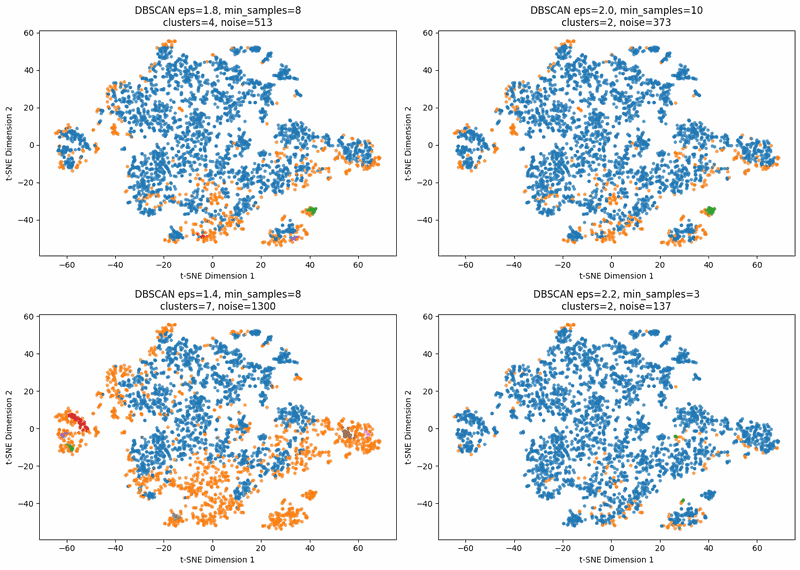

In [279]:
df_tsne  = tsne_results[(30,33)].copy()
param_list = [(1.8, 8),
    (2.0, 10),
    (1.4, 8),
    (2.2, 3)]

fig , axes = plt.subplots(2,2, figsize = (14,10))
for ax, (eps_val, min_val) in zip(axes.flatten(), param_list):
    db = DBSCAN(eps = eps_val, min_samples = min_val)
    labels = db.fit_predict(X)

    plot_df = df_tsne.copy()
    plot_df["cluster"] = labels.astype(str)

    sns.scatterplot(data=plot_df,
        x="tsne_x",
        y="tsne_y",
        hue="cluster",
        palette="tab10",
        s=18,
        alpha=0.75,
        linewidth=0,
        ax=ax,
        legend=False)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = sum(labels == -1)

    ax.set_title(
        f"DBSCAN eps={eps_val}, min_samples={min_val}\n"
        f"clusters={n_clusters}, noise={n_noise}"
    )
    ax.set_xlabel("t-SNE Dimension 1")
    ax.set_ylabel("t-SNE Dimension 2")

plt.tight_layout()
plt.show()


### 7.5. t-SNE 비교 해석

후보 설정 네 가지의 군집 결과를 t-SNE 그래프에 색칠해 비교했습니다.

| 설정 | 군집 수 | 노이즈 | 해석 |
|---|---|---|---|
| eps 1.8, min_samples 8 | 4 | 513 (16.0%) | 큰 주 군집 하나와 작은 밀집 영역 몇 개. 국소 구조는 잡았지만 전체 분리는 약했음 |
| eps 2.0, min_samples 10 | 2 | 373 (11.7%) | 한 군집이 대부분을 차지해, 서로 다른 맥주를 과하게 합친 것으로 보았음 |
| eps 1.4, min_samples 8 | 7 | 1,300 (40.7%) | 작은 밀집 영역은 더 잡았지만 지나치게 쪼개졌고 노이즈가 너무 많았음 |
| eps 2.2, min_samples 3 | 2 | 137 (4.3%) | 대부분이 한 군집에 속해 분리가 거의 없었음 |

전반적으로 DBSCAN 결과는 K-Means만큼 t-SNE 구조와 뚜렷하게 맞지 않았습니다. t-SNE 그래프 자체가 끊긴 섬이 아니라 이어진 영역과 점진적인 변화로 이루어져 있었기 때문입니다.

그중 **eps 1.8, min_samples 8**이 노이즈를 과하게 만들지 않으면서 여러 군집을 찾아 가장 균형 잡힌 결과로 판단했습니다.

### 7.6. 군집 순으로 정렬한 유사도 행렬

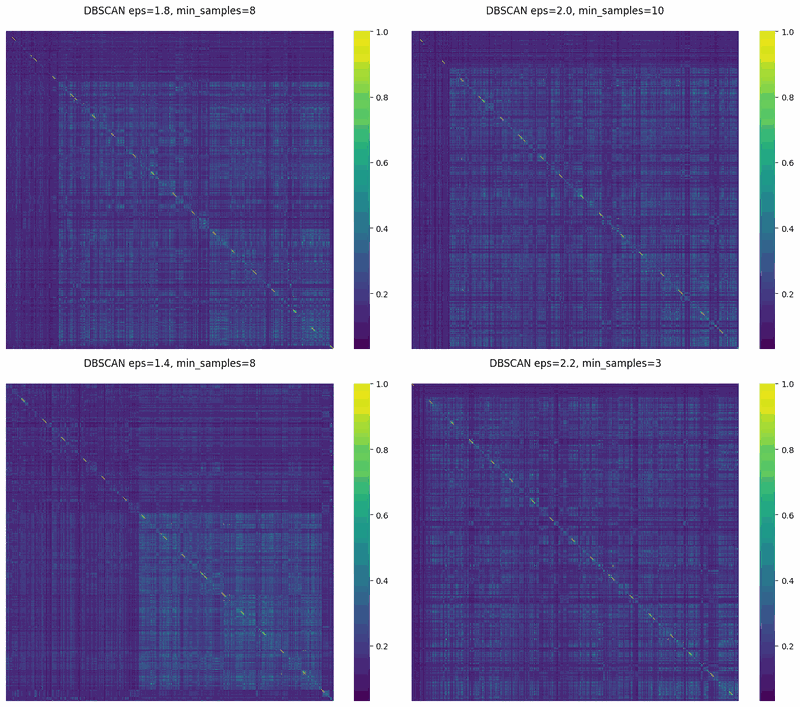

In [280]:
from sklearn.metrics.pairwise import euclidean_distances

dist_mat = euclidean_distances(X)
sim_mat = 1 / (1 + dist_mat)

param_list = [
    (1.8, 8),
    (2.0, 10),
    (1.4, 8),
    (2.2, 3)
]

fig, axes = plt.subplots(2, 2, figsize=(14, 12))

for ax, (eps_val, min_val) in zip(axes.flatten(), param_list):

    db = DBSCAN(eps=eps_val, min_samples=min_val)
    labels = db.fit_predict(X)

    
    sort_index = np.argsort(labels)

    sim_sorted = sim_mat[sort_index, :][:, sort_index]

    sns.heatmap(
        sim_sorted,
        cmap="viridis",
        xticklabels=False,
        yticklabels=False,
        cbar=True,
        ax=ax
    )

    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = sum(labels == -1)

    ax.set_title(
        f"DBSCAN eps={eps_val}, min_samples={min_val}\n")
    
plt.tight_layout()
plt.show() 


군집 정렬 유사도 행렬은 맥주를 군집 순서로 정렬해 맥주 쌍의 유사도를 색으로 칠한 그림입니다. 군집이 잘 나뉘었다면 대각선 위에 밝은 사각형 블록이 뚜렷하게 나타납니다.

- DBSCAN의 행렬은 K-Means보다 블록이 덜 뚜렷해, 전체적인 군집 분리가 약한 것으로 나타났습니다. DBSCAN은 모든 점을 나누기보다 국소 밀도에 집중하므로 예상한 결과였습니다.
- **eps 1.8, min_samples 8**이 가장 균형 잡혀 있었습니다. 중간 크기의 대각 블록이 여러 개 보여, 과하게 합치지 않으면서 응집된 밀집 그룹을 찾은 것으로 보았습니다.
- eps 2.0/min_samples 10은 과하게 합쳐져 블록이 약했고, eps 1.4/min_samples 8은 더 쪼개지고 노이즈가 많았으며, eps 2.2/min_samples 3은 구조가 거의 보이지 않았습니다.
- 정리하면 DBSCAN은 국소적인 밀집 그룹은 잡았지만, 이 데이터에 밀도로 뚜렷하게 나뉘는 군집은 없다고 판단했습니다.

### 7.7. 이상치·노이즈 처리

In [281]:
dbscan_best = DBSCAN(eps = 1.8, min_samples = 8)
dbscan_labels = dbscan_best.fit_predict(X)
df["dbscan_label"] = dbscan_labels

df["dbscan_label"].value_counts().sort_index()
#df.head()
n_noise = (df["dbscan_label"] == -1).sum()
noise_percent = n_noise / len(df)

print("Number of noise points:", n_noise)
print("Noise percentage:", noise_percent)

noise_beers = df[df["dbscan_label"] == -1]

noise_beers.head()


Number of noise points: 513
Noise percentage: 0.16046293400062558


,Name,Style,Brewery,Beer Name (Full),Description,ABV,Min IBU,Max IBU,Astringency,Body,...,Hoppy,Spices,Malty,review_aroma,review_appearance,review_palate,review_taste,review_overall,number_of_reviews,dbscan_label
33,Über Alt,Altbier,Rush River Brewing Company,Rush River Brewing Company Über Alt,Notes:Our Alt is a much stronger version of th...,0.774882,0.28848,0.515791,1.487574,0.688816,...,0.463023,-0.140852,2.673203,3.933333,3.866667,4.266667,4.266667,4.166667,15,-1
39,Olde School Barleywine,Barleywine - American,Dogfish Head Brewery,Dogfish Head Brewery Olde School Barleywine,"Notes:Bold, yet smooth! Fermented with dates a...",3.327306,2.93195,2.857498,0.334729,0.341912,...,0.068272,-0.225052,-0.334083,3.902411,3.932262,3.901837,3.931688,3.704363,871,-1
40,Brewer's Reserve Bourbon Barrel Barleywine,Barleywine - American,Central Waters Brewing Company,Central Waters Brewing Company Bourbon Barrel ...,Notes:Aged for 1 year in used bourbon barrels.\t,3.052429,2.93195,2.857498,-0.529905,0.727361,...,-0.589647,0.364350,1.445228,4.369205,4.072848,4.193709,4.307947,4.091060,302,-1
43,Behemoth,Barleywine - American,Three Floyds Brewing Co. & Brewpub,Three Floyds Brewing Co. & Brewpub Behemoth Bl...,"Notes:A huge, sweet barleywine with complex ca...",1.560243,2.93195,2.857498,0.142588,0.958631,...,2.107820,0.238050,0.743528,4.207373,4.123272,4.187788,4.264977,4.059908,434,-1
49,Helldorado,Barleywine - American,Firestone Walker Brewing Co.,Firestone Walker Brewing Co. Helldorado,Notes:Part of the adventure of aging beer in r...,2.463408,2.93195,2.857498,-1.010257,-0.274806,...,0.232751,0.111749,1.470289,4.500000,4.000000,4.000000,4.500000,4.500000,1,-1


In [282]:
noise_beers[
    ["Beer Name (Full)", "Style", "Brewery", "ABV", "Min IBU", "Max IBU",
     "Astringency", "Body", "Alcohol", "Bitter", "Sweet", "Sour",
     "Salty", "Fruits", "Hoppy", "Spices", "Malty"]
].head()

,Beer Name (Full),Style,Brewery,ABV,Min IBU,Max IBU,Astringency,Body,Alcohol,Bitter,Sweet,Sour,Salty,Fruits,Hoppy,Spices,Malty
33,Rush River Brewing Company Über Alt,Altbier,Rush River Brewing Company,0.774882,0.28848,0.515791,1.487574,0.688816,0.631557,0.412438,2.238570,0.443179,0.460905,0.819732,0.463023,-0.140852,2.673203
39,Dogfish Head Brewery Olde School Barleywine,Barleywine - American,Dogfish Head Brewery,3.327306,2.93195,2.857498,0.334729,0.341912,3.747788,0.761450,3.259695,-0.087924,-0.477041,2.120380,0.068272,-0.225052,-0.334083
40,Central Waters Brewing Company Bourbon Barrel ...,Barleywine - American,Central Waters Brewing Company,3.052429,2.93195,2.857498,-0.529905,0.727361,4.440284,0.140985,2.442795,-0.227688,-0.477041,0.757796,-0.589647,0.364350,1.445228
43,Three Floyds Brewing Co. & Brewpub Behemoth Bl...,Barleywine - American,Three Floyds Brewing Co. & Brewpub,1.560243,2.93195,2.857498,0.142588,0.958631,2.016549,2.079938,1.946821,1.086094,-0.477041,1.934573,2.107820,0.238050,0.743528
49,Firestone Walker Brewing Co. Helldorado,Barleywine - American,Firestone Walker Brewing Co.,2.463408,2.93195,2.857498,-1.010257,-0.274806,2.247380,-0.440701,1.246621,-0.283594,1.867825,0.200375,0.232751,0.111749,1.470289


- eps 1.8, min_samples 8에서 맥주 513종(16%)이 노이즈로 분류되었습니다. 맛 프로필 공간에서 충분히 밀집된 영역에 속하지 않는 맥주들이었습니다.
- 노이즈를 곧바로 오류로 보지는 않았습니다. 도수·쓴맛·단맛·바디감 등의 조합이 독특한 틈새 스타일일 가능성이 크다고 보았고, 실제로 아메리칸 발리와인처럼 강하고 복합적인 스타일이 노이즈에 많이 포함되어 있었습니다.
- 주요 제품 세그먼트에 잘 맞지 않는 맥주를 따로 찾을 수 있다는 점은 연구 목표에 맞았습니다. 다만 노이즈는 지워야 할 관측치가 아니라 의미 있는 틈새 제품일 수 있어 신중하게 해석했습니다.

### 7.8. 최적 군집 평가

- 파라미터 탐색 결과, **DBSCAN eps 1.8, min_samples 8**을 최종 설정으로 판단했습니다.
- **내재 군집 포착:** t-SNE 비교에서 의미 있는 밀집 그룹 여러 개를 찾으면서, 어느 주요 군집에도 속하지 않는 맥주는 따로 떼어 냈습니다. 모든 맥주를 억지로 그룹에 넣지 않고 밀도로 드러나는 구조를 찾았다고 보았습니다.
- **정보량:** 해석 가능한 군집을 여러 개 만들면서도 군집 수가 다루기 쉬운 수준이었습니다.
- **연구 목표와의 부합:** 이상치와 틈새 제품을 적절히 다뤘습니다. 노이즈 16%는 희귀 스타일이 섞인 맥주 데이터로서 합리적인 수준으로 판단했고, DBSCAN은 이들을 억지로 군집에 넣지 않고 따로 처리했습니다.
- **K-Means와 비교:** K-Means는 더 깔끔하게 나누지만 독특한 맥주까지 모두 어떤 군집에 배정합니다. 시장 세분화에는 K-Means가 쓸모 있지만, 내재 군집을 찾으면서 이상치도 다룬다는 목표에는 DBSCAN이 더 맞는다고 판단했습니다.

### 7.9. 방법의 한계

#### k-거리 그래프
k-거리 그래프만으로 원하는 군집을 정확히 잡는 eps 하나를 고를 수는 없었습니다. 곡선이 서서히 올라가고 뚜렷하게 꺾이는 점이 하나로 나타나지 않았습니다. 군집마다 밀도가 다르다는 뜻으로 보았고, 어떤 스타일은 빽빽하게, 어떤 스타일은 넓게 퍼져 있어 eps 하나로 모든 군집을 찾기는 어려웠습니다.

#### 평균 실루엣 점수
실루엣이 가장 높은 설정이 모든 내재 군집을 찾는 설정은 아니었습니다. 소수의 밀집 군집만 찾고 대부분을 노이즈로 처리하면 수치상 분리는 좋아지지만, 작아도 의미 있는 스타일 그룹을 놓치게 됩니다. 실루엣이 조금 낮더라도 전체 구조를 더 온전히 보여 주는 설정이 낫다고 판단했습니다.

#### 군집 정렬 유사도 행렬
내재 군집을 잘 찾았더라도 완벽한 대각 블록이 나오지 않을 수 있었습니다. 이 데이터에는 여러 특성이 섞인 맥주, 하이브리드 스타일, 점진적으로 변하는 맛 프로필이 있어 여러 그룹과 동시에 비슷한 맥주가 있었습니다. 그래서 경계가 흐릿하게 보인 것을 군집화 실패로 보지 않고, 데이터의 실제 구조가 반영된 결과로 해석했습니다.

### 7.10. 최종 DBSCAN 결과

In [283]:
dbscan_final = DBSCAN(eps=1.8, min_samples=8)
dbscan_final_labels = dbscan_final.fit_predict(X)
df["dbscan_final"] = dbscan_final_labels

df["dbscan_final"].value_counts().sort_index()
n_clusters = len(set(dbscan_final_labels)) - (1 if -1 in dbscan_final_labels else 0)
n_noise = sum(dbscan_final_labels == -1)
noise_percent = n_noise / len(dbscan_final_labels)

print("Number of clusters:", n_clusters)
print("Number of noise points:", n_noise)
print("Noise percentage:", noise_percent)

Number of clusters: 4
Number of noise points: 513
Noise percentage: 0.16046293400062558


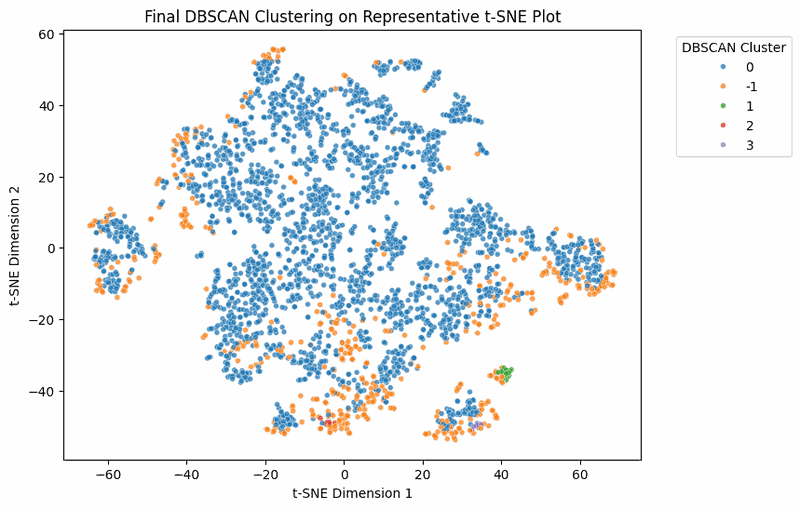

In [284]:
df_tsne_dbscan_final = tsne_results[(30, 33)].copy()
df_tsne_dbscan_final["dbscan_final"] = dbscan_final_labels.astype(str)

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df_tsne_dbscan_final,
    x="tsne_x",
    y="tsne_y",
    hue="dbscan_final",
    palette="tab10",
    s=18,
    alpha=0.75
)

plt.title("Final DBSCAN Clustering on Representative t-SNE Plot")
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.legend(title="DBSCAN Cluster", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.show()

- 최종 DBSCAN은 군집 4개와 노이즈 513종(16.0%)을 만들었습니다.
- 대부분의 맥주가 큰 주 군집 하나에 속했습니다. 많은 맥주가 뚜렷하게 나뉘기보다 맛이 이어지며 서서히 변한다는 뜻으로 해석했습니다.
- 그 밖에 작은 밀집 군집이 몇 개 있었고, 프로필이 매우 뚜렷한 틈새 스타일로 보았습니다.
- 노이즈는 주로 군집 경계나 고립된 영역에 있어, 어느 밀집 그룹에도 강하게 속하지 않는 맥주였습니다.
- K-Means와 비교하면, DBSCAN 결과는 맥주 시장이 완전히 분리된 여러 범주라기보다 하나로 이어진 넓은 제품 공간과 몇 개의 특화 그룹으로 이루어져 있음을 보여 주었습니다.

### 7.11. 군집별 리뷰 점수 확인

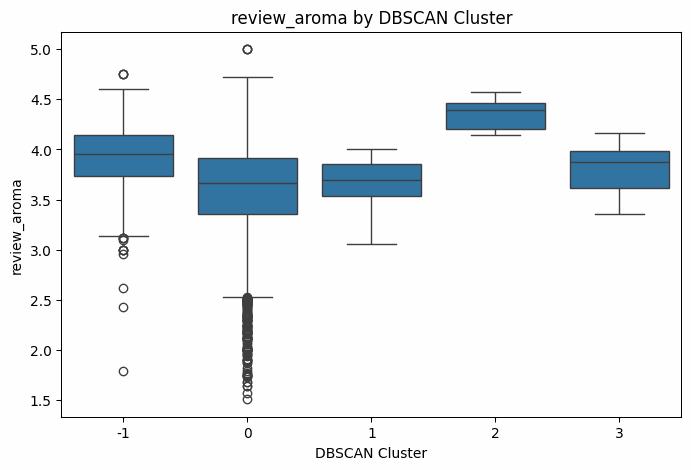

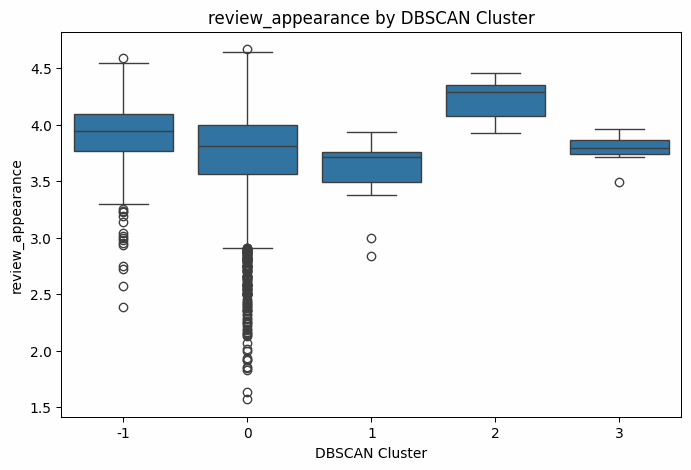

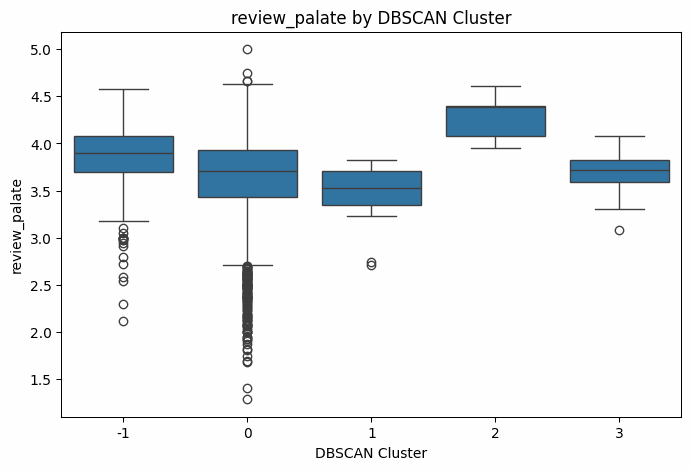

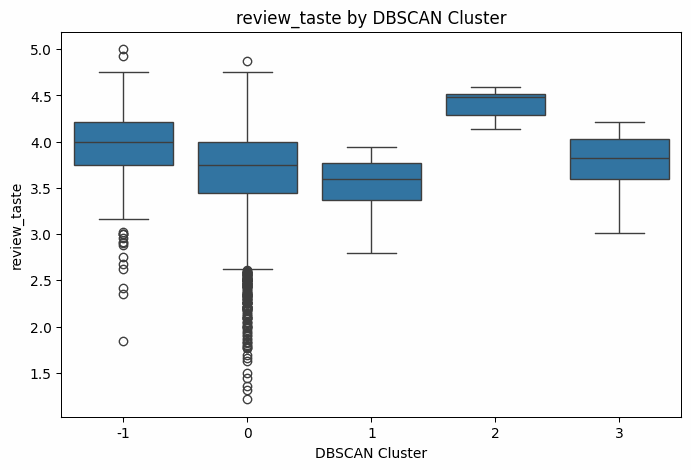

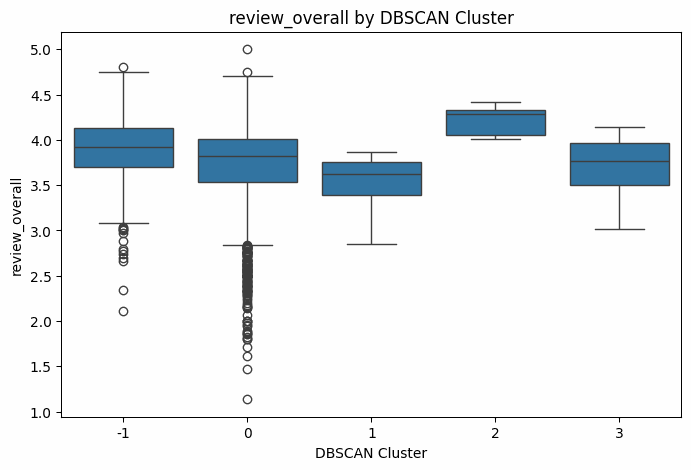

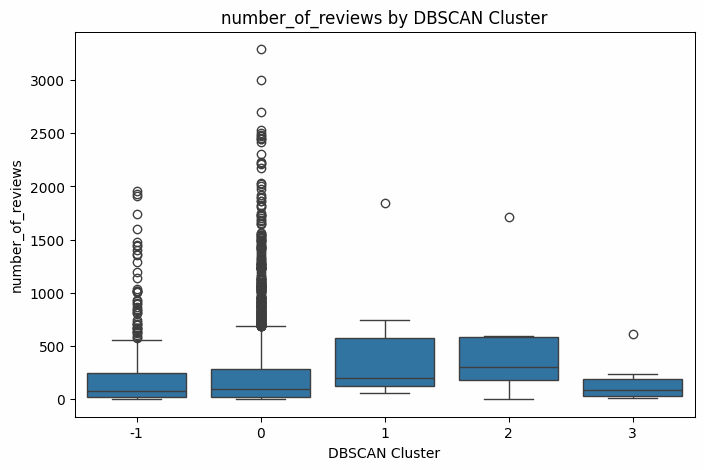

In [285]:
review_cols = [
    "review_aroma",
    "review_appearance",
    "review_palate",
    "review_taste",
    "review_overall",
    "number_of_reviews"
]

for col in review_cols:
    
    plt.figure(figsize=(8,5))
    
    sns.boxplot(
        data=df,
        x="dbscan_final",
        y=col
    )
    
    plt.title(f"{col} by DBSCAN Cluster")
    plt.xlabel("DBSCAN Cluster")
    plt.ylabel(col)
    
    plt.show()

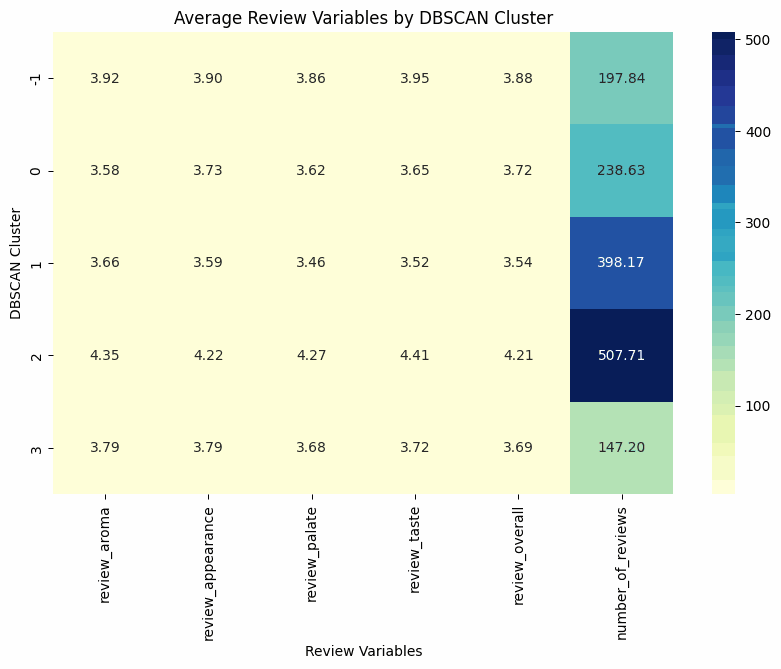

In [286]:
review_cols = [
    "review_aroma",
    "review_appearance",
    "review_palate",
    "review_taste",
    "review_overall",
    "number_of_reviews"
]

cluster_review_means = df.groupby("dbscan_final")[review_cols].mean()

plt.figure(figsize=(10,6))

sns.heatmap(
    cluster_review_means,
    annot=True,
    cmap="YlGnBu",
    fmt=".2f"
)

plt.title("Average Review Variables by DBSCAN Cluster")
plt.xlabel("Review Variables")
plt.ylabel("DBSCAN Cluster")

plt.show()

리뷰 점수는 군집을 만들 때 쓰지 않았기 때문에, 군집별 리뷰 차이를 결과가 소비자 관점에서도 의미 있는지 확인하는 사후 점검으로 활용했습니다(아래 숫자는 위 히트맵의 군집별 평균).

| DBSCAN 군집 | 맥주 수 | 종합 평점 평균 | 평균 리뷰 수 | 해석 |
|---|---|---|---|---|
| 2 | 7 | 4.21 (가장 높음) | 508 (가장 많음) | 향·입안 느낌·맛·종합 점수가 모두 가장 높은 인기·프리미엄 그룹 |
| 0 | 2,649 | 3.72 | 239 | 전체의 83%가 속한 주 군집으로, 평균적인 맥주가 넓게 섞여 있었음 |
| 3 | 10 | 3.69 | 147 | 중간 점수지만 리뷰가 적은 작은 틈새 그룹 |
| 1 | 18 | 3.54 (가장 낮음) | 398 | 대부분 항목에서 점수가 가장 낮은 그룹 |
| -1 (노이즈) | 513 | 3.88 | 198 | 점수가 낮지 않았음 |

**주의:** 주 군집(0)을 뺀 나머지 군집은 7~18종으로 매우 작았습니다. 그래서 군집 간 평점 차이(3.54~4.21)는 소수의 맥주에 크게 좌우되며 일반화하기 어렵다고 판단했고, 군집별 평점 비교는 군집 크기가 고른 HAC(8.13)를 기준으로 보았습니다.

- 노이즈 맥주도 종합 평점 평균 3.88로 비교적 높았습니다. DBSCAN이 노이즈로 분류한 맥주는 품질이 낮은 제품이 아니라, 주류 그룹에 들어가지 않는 개성 있는 맥주로 해석했습니다.
- 정리하면 DBSCAN 군집은 고객 만족도가 서로 다른 제품 그룹을 구분해 냈지만, 군집 크기 차이가 커서 평점 비교의 근거로는 제한적이었습니다.

## 8. 군집 알고리즘 2: HAC complete linkage (계층적 군집)

HAC(계층적 병합 군집)는 각 맥주를 하나의 군집으로 시작해 가장 가까운 군집끼리 차례로 합쳐 가는 방법이고, complete linkage는 두 군집 사이 거리를 "가장 먼 두 점 사이의 거리"로 정의합니다.

맛 프로필이 평점을 얼마나 설명하는지 보기 위해, 맛 프로필 변수로만 HAC를 수행한 뒤 군집 결과를 t-SNE 그래프에 표시했고, 최종 군집 수를 정한 다음 상자그림으로 군집별 리뷰 점수를 비교했습니다.

### 맛 프로필 군집

맛 프로필 데이터로 시작했습니다.

### 8.1. 거리 척도

정제된 데이터가 모두 수치형이었고, 중첩된 군집 구조를 보되 관측치 하나짜리 군집이 생기지 않도록 하는 것이 목적이어서 유클리드 거리를 사용했습니다.

### 8.2. 덴드로그램

각 관측치 사이의 거리와 내재 군집 구조를 파악하기 위해 덴드로그램을 그려, 이 알고리즘이 연구 목표에 맞는지 확인했습니다.

In [33]:
dm_complete = pdist(X_scaled, metric='euclidean')
dm_complete

array([1.91824703, 1.83774671, 2.3884883 , ..., 5.49101449, 2.81340756,
       6.96883353])

In [56]:
Z_complete = linkage(dm_complete, method='complete')
Z_complete

array([[6.65000000e+02, 7.73000000e+02, 0.00000000e+00, 2.00000000e+00],
       [1.32300000e+03, 1.32600000e+03, 1.96340323e-02, 2.00000000e+00],
       [6.62000000e+02, 7.74000000e+02, 3.92680646e-02, 2.00000000e+00],
       ...,
       [6.38800000e+03, 6.38900000e+03, 1.62818890e+01, 3.19200000e+03],
       [6.38300000e+03, 6.39000000e+03, 2.42482960e+01, 3.19400000e+03],
       [6.38000000e+03, 6.39100000e+03, 3.10628215e+01, 3.19700000e+03]])

관측치가 너무 많아 모든 잎을 그릴 수 없어, `truncate_mode='lastp'`, `p=200`으로 군집 200개에서 1개로 합쳐지는 윗부분만 표시했습니다. 세로축은 합쳐지는 맥주 그룹, 가로축은 합쳐질 때의 거리(비유사도)입니다.

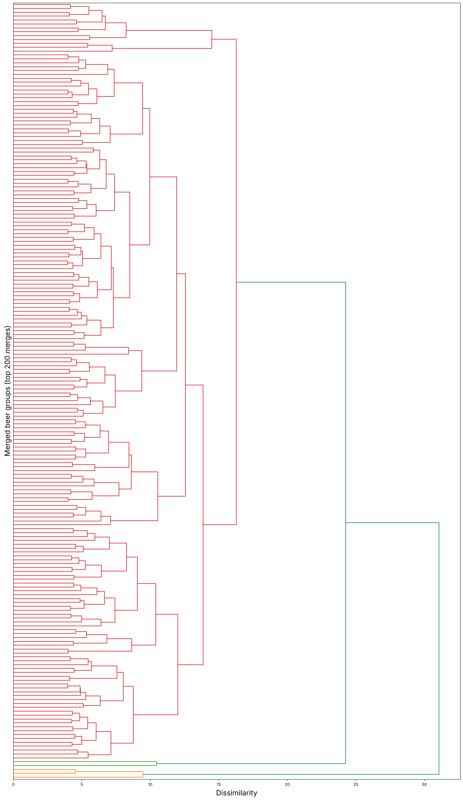

In [209]:
fig, ax = plt.subplots(figsize=(20, 35))
d = dendrogram(Z_complete, orientation='right', truncate_mode='lastp', p=200, no_labels=True, ax=ax)
ax.set_xlabel('Dissimilarity', fontsize=18)
ax.set_ylabel('Merged beer groups (top 200 merges)', fontsize=18)
plt.yticks(fontsize=12)
plt.show()

덴드로그램에서는 데이터가 크게 세 군집으로 나뉘는 것으로 나타났습니다. 대부분을 차지하는 큰 군집 하나와, 관측치 한 개 또는 아주 작은 그룹으로 이루어진 군집 두 개였습니다. 큰 군집 안에서도 크기가 다른 하위 군집 두 개로 나뉠 가능성이 보였지만, 두 하위 군집이 합쳐지는 높이가 다른 병합보다 크게 높지 않아 의미 있는 분할인지는 불확실하다고 보았습니다.

이상치의 영향을 줄이려고 complete linkage를 골랐지만, 큰 거리에서야 나머지와 합쳐지는 관측치나 작은 그룹이 여전히 보였습니다. 이들은 주요 구조에서 멀리 떨어진 잠재적 이상치로 판단했고, t-SNE에서 중심과 떨어져 보이는 점들과도 일치했습니다.

내재 군집 수를 더 살펴보기 위해 군집을 만들고 t-SNE에 색칠해 보았습니다.

### 8.3. t-SNE로 확인

k=2부터 10까지 군집을 만들고, 하위 군집과 관측치 한 개짜리 군집 가능성을 고려하며 t-SNE 그래프에 군집별로 색칠했습니다.

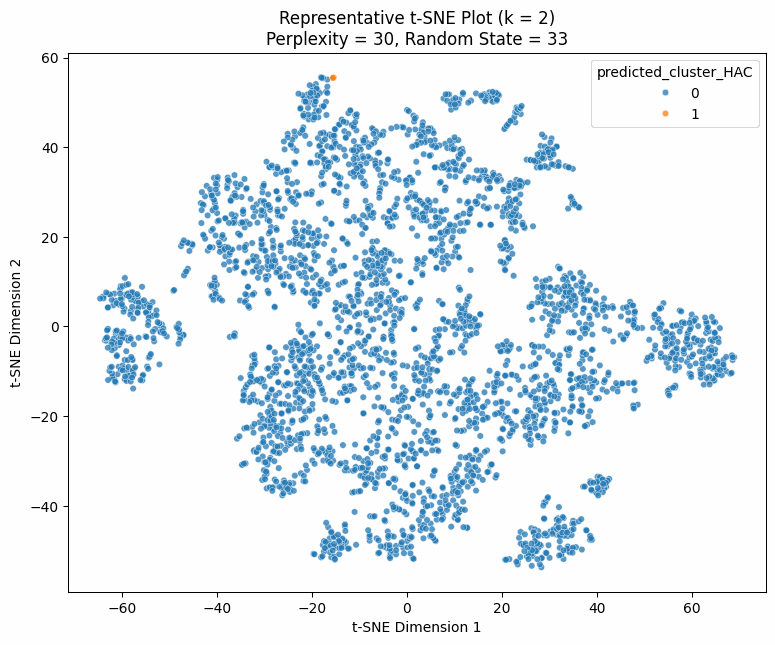

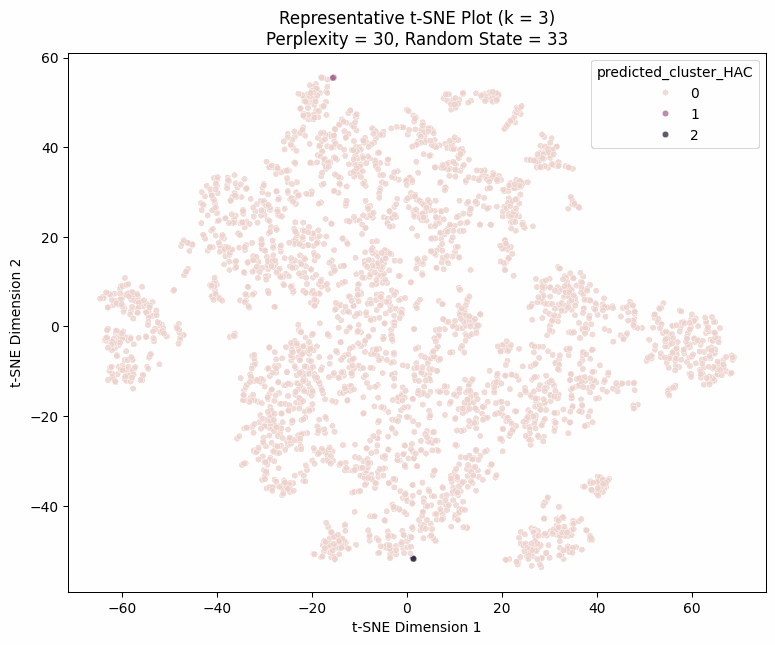

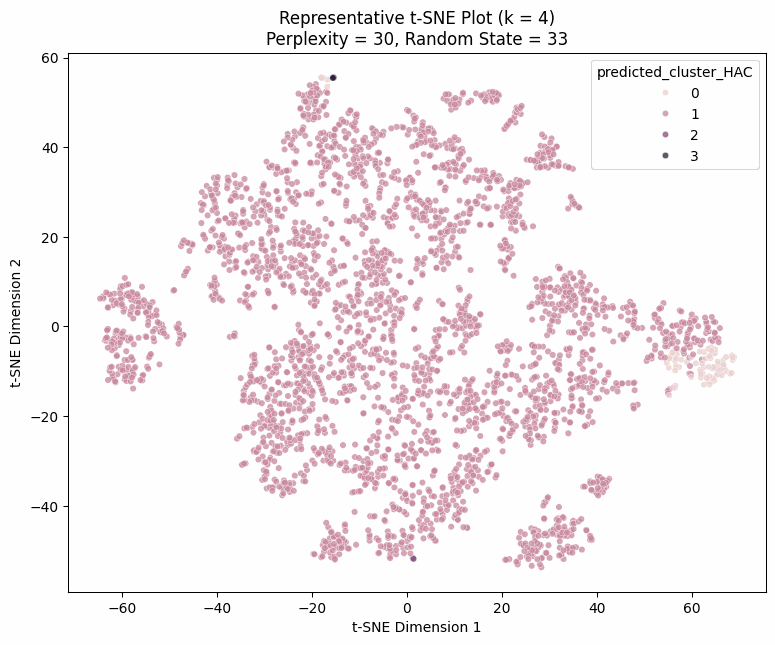

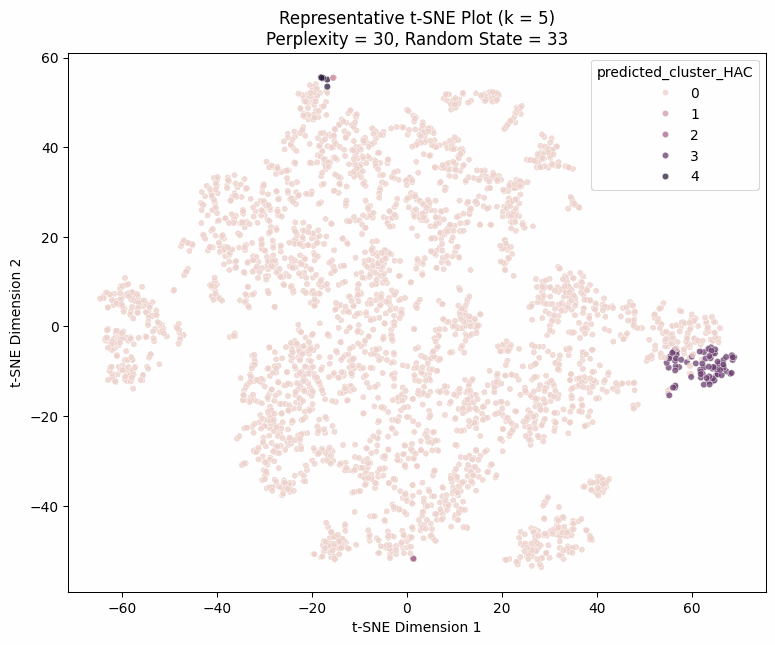

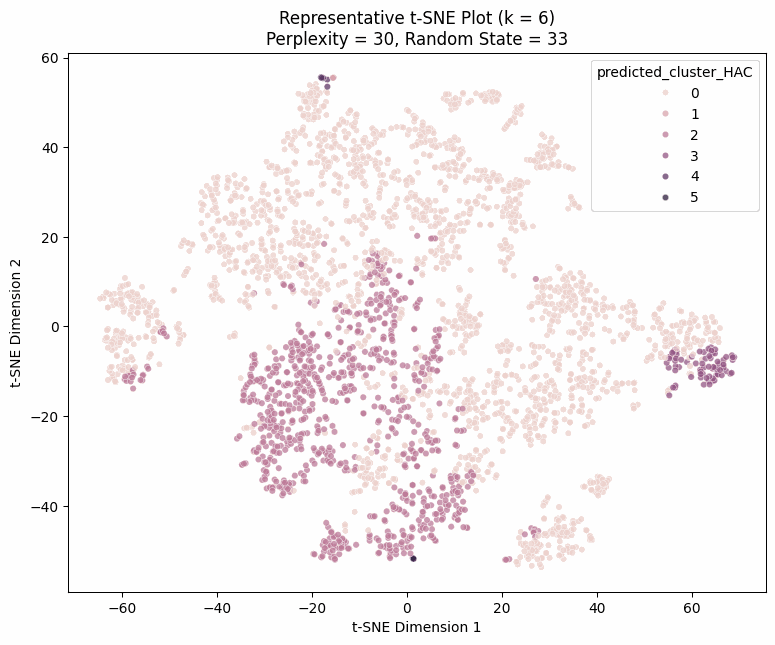

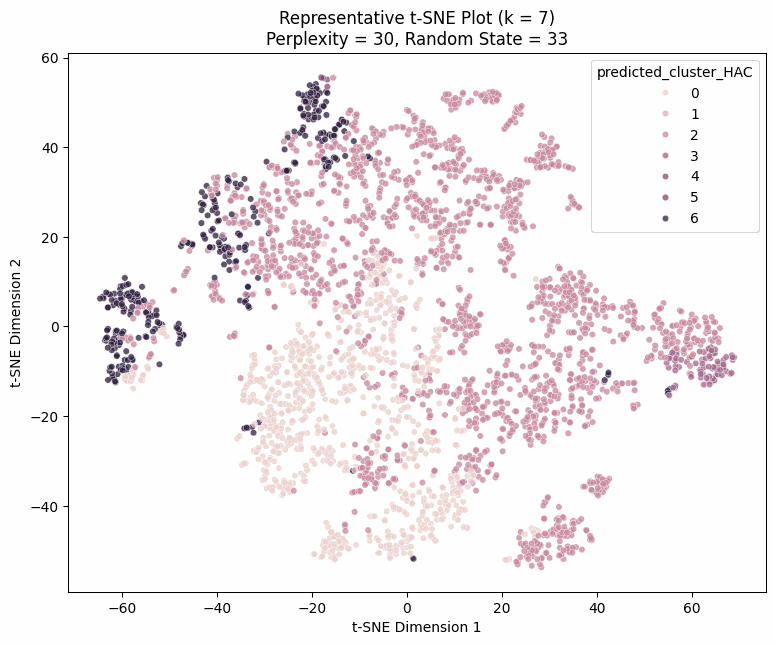

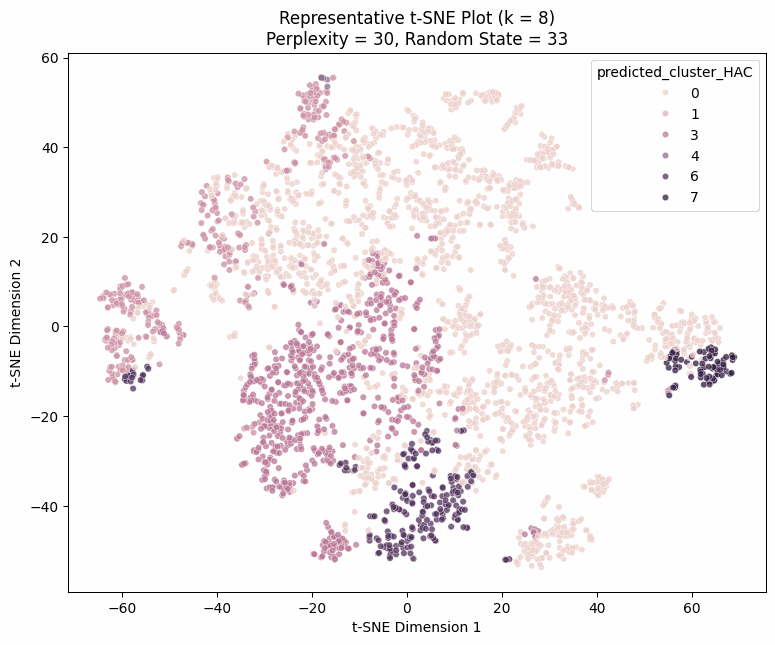

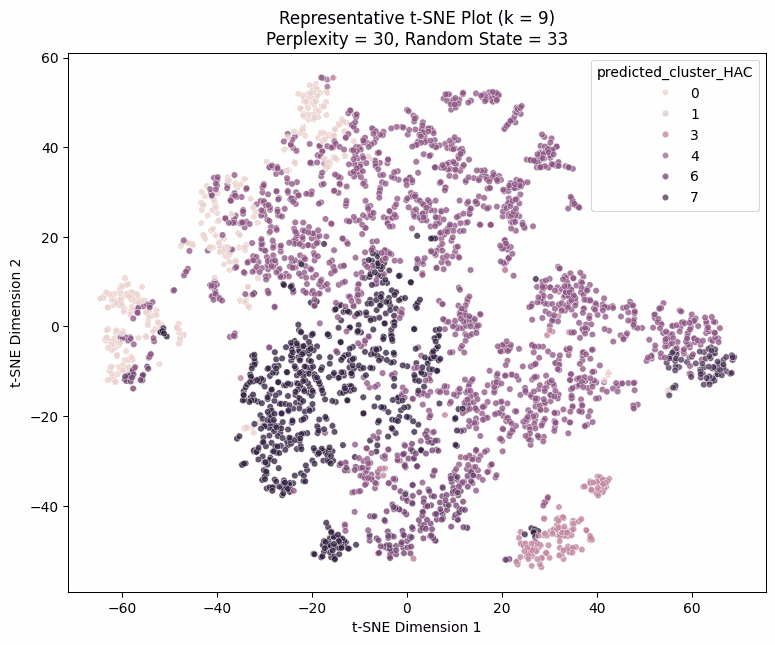

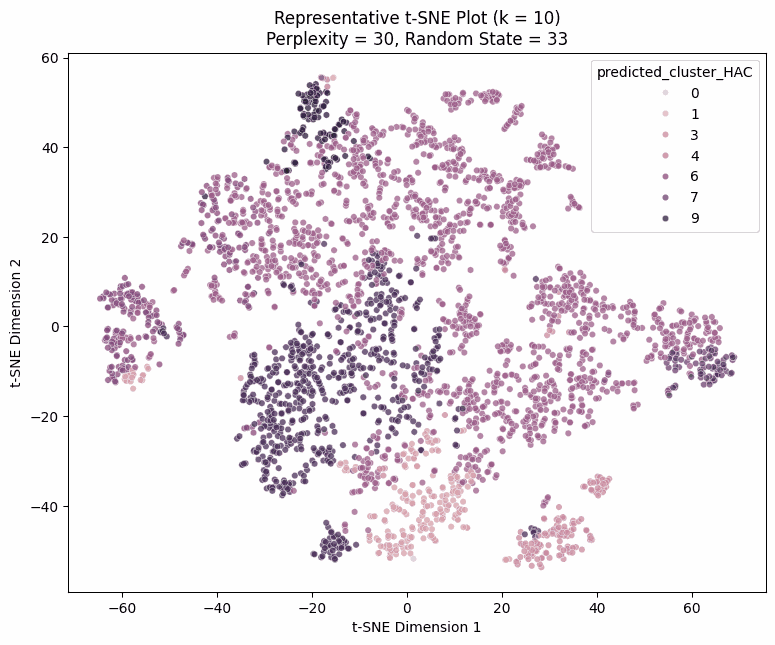

In [160]:
representative_perplexity = 30
representative_random_state = 33

for k in range(2,11):
        hac = AgglomerativeClustering(n_clusters=k, metric='euclidean', linkage="complete")
        df_tsne['predicted_cluster_HAC'] = hac.fit_predict(X_scaled)

        plt.figure(figsize=(9, 7))
        sns.scatterplot(
        data=df_tsne,
        x="tsne_x",
        y="tsne_y",
        s=22,
        alpha=0.75,
        hue='predicted_cluster_HAC'
        )

        plt.title(
        f"Representative t-SNE Plot (k = {k})\n"
        f"Perplexity = {representative_perplexity}, Random State = {representative_random_state}"
        )
        plt.xlabel("t-SNE Dimension 1")
        plt.ylabel("t-SNE Dimension 2")
        plt.show()

- **이상치에 끌려감:** k=2, 3처럼 낮은 단계에서는 이웃과 멀리 떨어진 소수의 점을 단독 군집으로 떼어 냈습니다. k가 커지면서 큰 구조를 점차 잡았지만, 처음에 잘못 떼어 낸 것은 되돌릴 수 없어(계층적 방법의 특성) 군집 구조가 어긋났습니다.
- **경계가 겹침:** 색이 영역마다 상당히 겹쳐 경계가 뚜렷하지 않았습니다. 이상치가 있다는 신호이자, 실제 관측치끼리의 거리가 t-SNE만 보고 예상한 것보다 가깝다는 뜻으로 보았습니다.
- **합쳐짐의 의미:** t-SNE는 리뷰 변수를 빼고 맥주 자체의 프로필로만 그렸으므로, 군집도 평점이 아닌 제품 특성의 구조를 반영한다고 보았습니다. 일부가 합쳐지는 것은 나쁜 결과라기보다, 큰 맥주 그룹 안에 세부 특성이 조금씩 다른 하위 군집이 있다는 뜻으로 해석했습니다.

덴드로그램, t-SNE 색칠, 앞의 산점도 모두 이상치의 존재를 보여 주었고, 이 상태의 결과는 몇 번의 잘못된 병합 때문에 내재 구조를 제대로 잡지 못한다고 판단했습니다. 그래서 잠재적 노이즈를 빼고 HAC를 다시 적용해 더 해석하기 쉬운 구조가 나오는지 확인하기로 했습니다.

다만 노이즈 맥주를 오류로 보지는 않았습니다. 새 모델을 학습한 뒤 노이즈 맥주를 다시 더해 t-SNE와 상자그림에 함께 표시해, 독특한 맥주를 보존하면서 구조를 해석했습니다.

먼저 k=2~10의 평균 실루엣 점수를 그려 응집도와 분리도의 균형이 가장 좋은 군집 수를 확인했습니다.

### 8.4. 평균 실루엣 점수 그래프

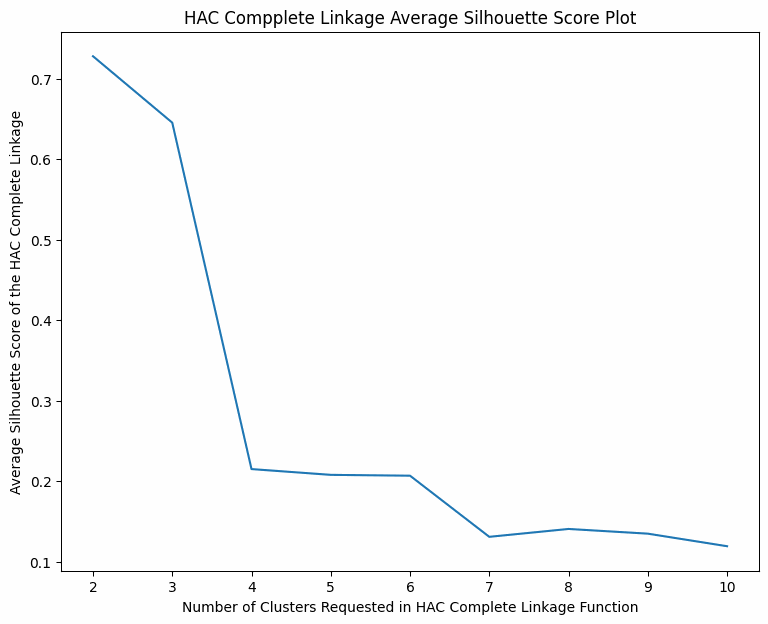

Max silhouette score: 0.7282514491395028
Max numbers of clusters: 2


In [187]:
cluster_num_list=range(2,11)

avg_sil_score_list=[]
for k in cluster_num_list:
    hac = AgglomerativeClustering(n_clusters=k, metric='euclidean', linkage="complete")
    cluster_labels = hac.fit_predict(X_scaled)
    avg_sil_score=silhouette_score(X_scaled, cluster_labels, metric='euclidean')
    avg_sil_score_list.append(avg_sil_score)

plt.figure(figsize=(9, 7))
plt.plot(cluster_num_list,avg_sil_score_list)
plt.xlabel('Number of Clusters Requested in HAC Complete Linkage Function')
plt.ylabel('Average Silhouette Score of the HAC Complete Linkage')
plt.title('HAC Compplete Linkage Average Silhouette Score Plot')
plt.show()

print("Max silhouette score:", max(avg_sil_score_list))
print("Max numbers of clusters:", cluster_num_list[avg_sil_score_list.index(max(avg_sil_score_list))])

평균 실루엣 점수는 k=2에서 0.728(약 0.73)으로 가장 높았습니다. 수치만 보면 군집 2개일 때 응집도와 분리도가 가장 좋았습니다.

하지만 t-SNE에서 보듯 데이터는 둥글거나 뚜렷하게 나뉜 그룹이 아니었고, 낮은 k에서는 소수의 이상치를 단독 군집으로 떼어 냈습니다. 따라서 이 실루엣 점수는 최적 군집 수를 고르는 근거로 쓰지 않았습니다.

### 8.5. 노이즈를 뺀 데이터의 덴드로그램

#### DBSCAN의 노이즈 결과를 HAC에 사용한 이유

원본 데이터의 덴드로그램(8.2)은 큰 군집 하나와 먼 거리에서 합쳐지는 소수의 점으로 이루어져 있었습니다. complete linkage는 single linkage보다 이상치에 강하지만, 병합 높이가 두 그룹에서 *가장 먼* 두 점으로 정해지므로 극단적인 맥주 몇 개가 덴드로그램을 늘어뜨려 주류 맥주의 구조를 가렸습니다. k=2의 높은 실루엣(0.73)도 같은 문제였습니다. 이 2분할은 실제 맛 프로필 세그먼트가 아니라 소수의 이상치를 나머지와 떼어 낸 결과였습니다.

그래서 HAC와 *독립적이고 상호 보완적인* 이상치 판별 단계가 필요하다고 판단했습니다. 군집화할 데이터를 같은 방법으로 정리하면 순환 논리가 되기 때문입니다. DBSCAN은 밀도 기반이라 군집 수나 모양을 가정하지 않고 밀집 영역 밖의 점을 표시하며, 이는 complete linkage가 혼자서는 할 수 없는 판단입니다. 또한 DBSCAN의 노이즈 513종(16%)은 앞서 오류가 아닌 틈새 스타일로 확인되었고, HAC(그룹 간 거리)와 다른 원리(국소 밀도)로 얻은 결과였습니다. 한 방법의 강점으로 다른 방법의 약점을 보완하려는 것이 두 방법을 연결한 이유였습니다.

이 선택이 타당한지 확인하기 위해 (1) 노이즈 맥주를 나중에 별도 그룹(-1)으로 다시 넣어 최종 해석에서 어떤 맥주도 버리지 않았고, (2) 9장에서 전체 데이터에 K-Means를 적용해 교차 확인했습니다.

DBSCAN(eps 1.8, min_samples 8)이 노이즈로 분류한 513종을 뺀 데이터로 덴드로그램을 다시 그렸습니다.

In [180]:
dbscan_best = DBSCAN(eps=1.8, min_samples=8)
dbscan_labels = dbscan_best.fit_predict(X_scaled)
X_scaled["dbscan_label"] = dbscan_labels

noise_beers = X_scaled[X_scaled["dbscan_label"] == -1]
no_noise_beers = X_scaled.drop(noise_beers.index)

no_noise_beers = no_noise_beers.loc[:, "ABV":"Malty"]

no_noise_beers.head()

,ABV,Min IBU,Max IBU,Astringency,Body,Alcohol,Bitter,Sweet,Sour,Salty,Fruits,Hoppy,Spices,Malty
0,-0.481696,0.28848,0.515791,-0.337764,-0.544620,-0.464895,0.412438,0.458897,-0.004066,-0.477041,-0.171238,0.528815,-0.435553,0.893892
1,0.264397,0.28848,0.515791,-0.433834,0.419002,0.054477,-0.130468,-0.095428,-0.479264,-0.477041,-0.449949,-0.194896,-0.267152,0.217253
2,-0.599501,0.28848,0.515791,-0.241694,-0.351895,-0.638019,0.218543,-0.445528,-0.619028,-0.477041,-0.883498,0.430127,-0.603954,-0.334083
3,0.774882,0.28848,0.515791,-0.337764,0.341912,0.804681,0.412438,1.246621,-0.423358,-0.008068,0.324247,-0.030416,-0.098752,1.094378
4,0.264397,0.28848,0.515791,0.815081,0.187733,0.516141,0.296101,-0.387178,-0.674933,-0.008068,-0.852530,0.331439,0.069649,0.492921


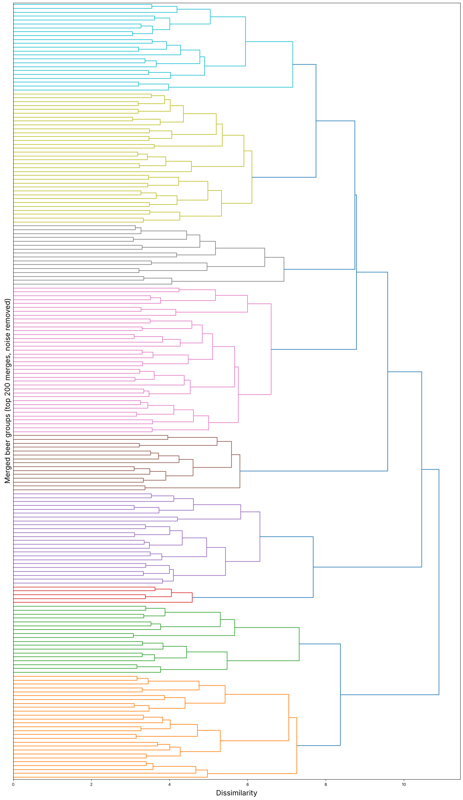

In [208]:
dm_complete_no_noise = pdist(no_noise_beers, metric='euclidean')

Z_complete_no_noise = linkage(dm_complete_no_noise, method='complete')

fig, ax = plt.subplots(figsize=(20, 35))
d = dendrogram(Z_complete_no_noise, orientation='right', truncate_mode='lastp', p=200, no_labels=True, ax=ax)
ax.set_xlabel('Dissimilarity', fontsize=18)
ax.set_ylabel('Merged beer groups (top 200 merges, noise removed)', fontsize=18)
plt.yticks(fontsize=12)
plt.show()

노이즈를 뺀 덴드로그램에서는 데이터가 6~7개 군집으로 나뉠 수 있는 것으로 나타났습니다. 가장 큰 거리 증가가 나타나기 전에 이 그룹들이 비슷한 높이에서 합쳐졌습니다. 몇몇 주요 군집 안에는 하위 군집 구조도 보여, 큰 그룹 안에 더 작은 맛 프로필 세그먼트가 있을 수 있다고 보았습니다. 예를 들어 흔한 맛 특성을 많이 가졌지만 질감이나 맛이 독특한 맥주들입니다.

다만 일부 하위 그룹은 이웃 병합보다 크게 높지 않은 높이에서 합쳐져, 모든 분할이 의미 있는지는 분명하지 않았습니다. t-SNE에서 중심 영역이 촘촘하게 모여 있던 것과도 맞는 결과였습니다.

각 가지가 합쳐지는 높이가 비교적 비슷하고, 일부 하위 군집을 빼면 그룹 크기도 비슷해 노이즈와 이상치는 더 이상 큰 문제가 아니라고 판단했습니다. 다음으로 평균 실루엣 점수로 군집 수를 평가했습니다.

### 8.6. 노이즈를 다시 더해 HAC 결과 그리기

노이즈를 뺀 데이터로 k=2~10 군집을 만들고, 노이즈 맥주(-1)를 다시 더해 t-SNE 그래프에 색칠했습니다.

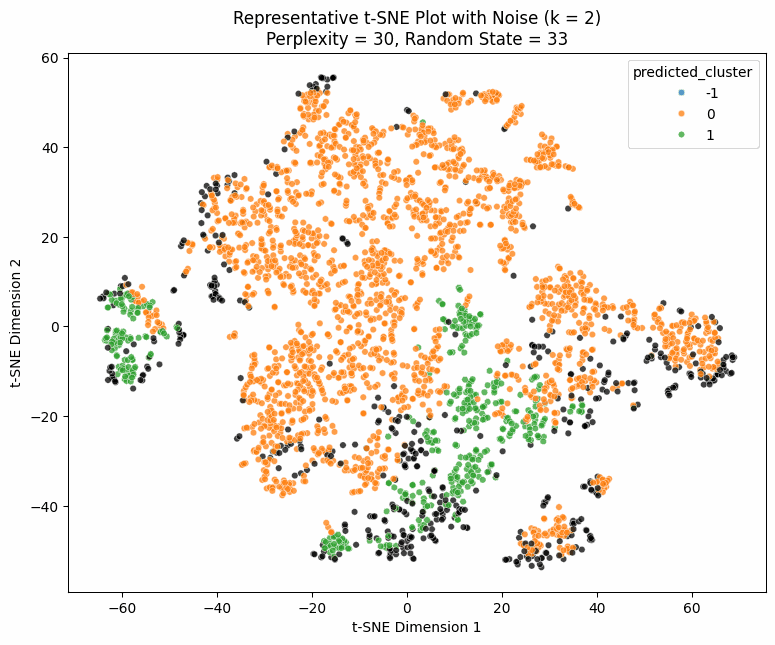

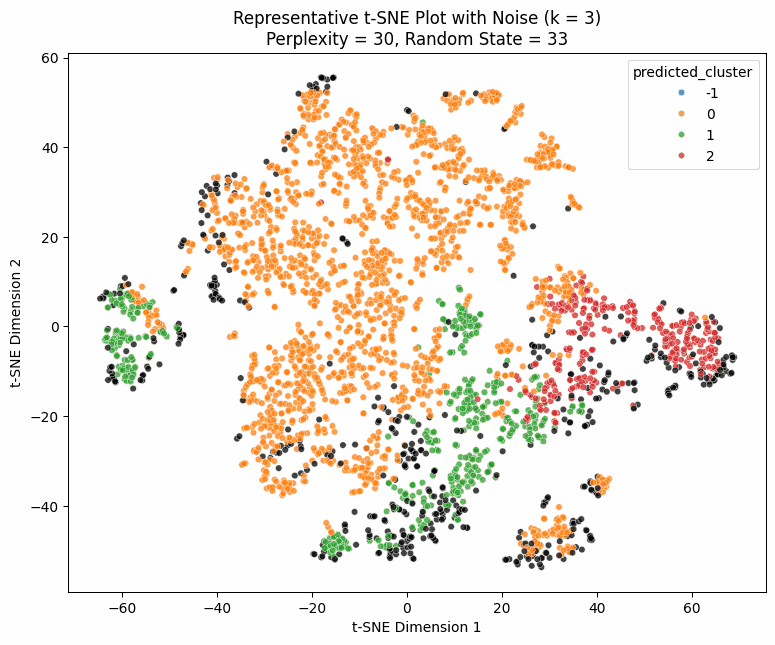

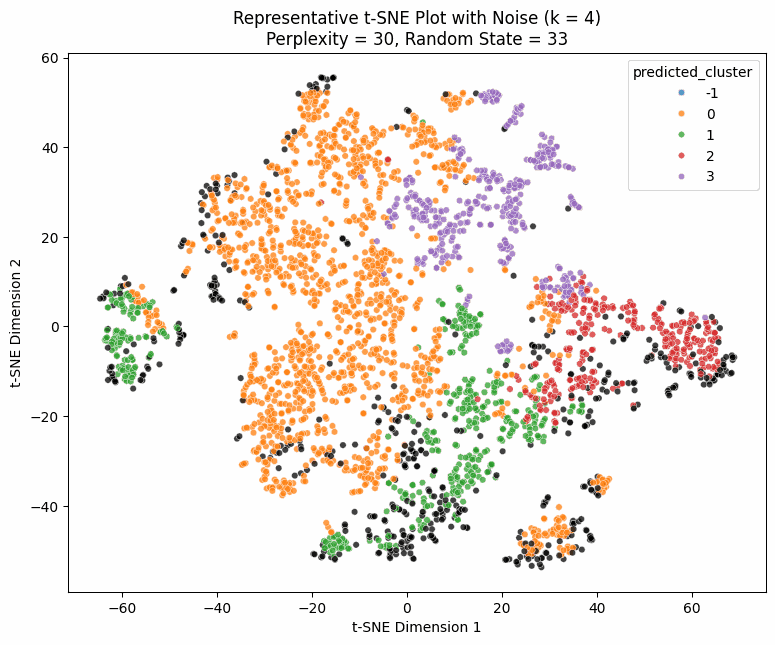

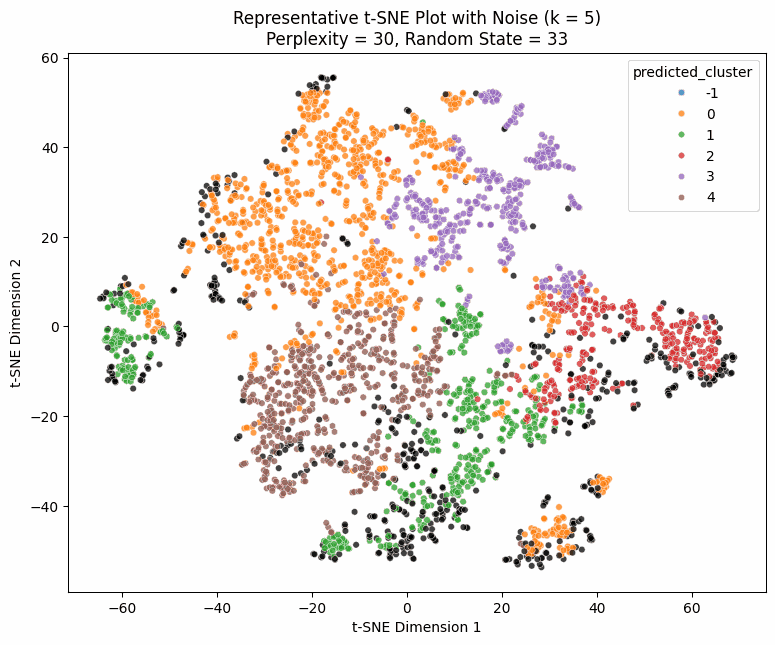

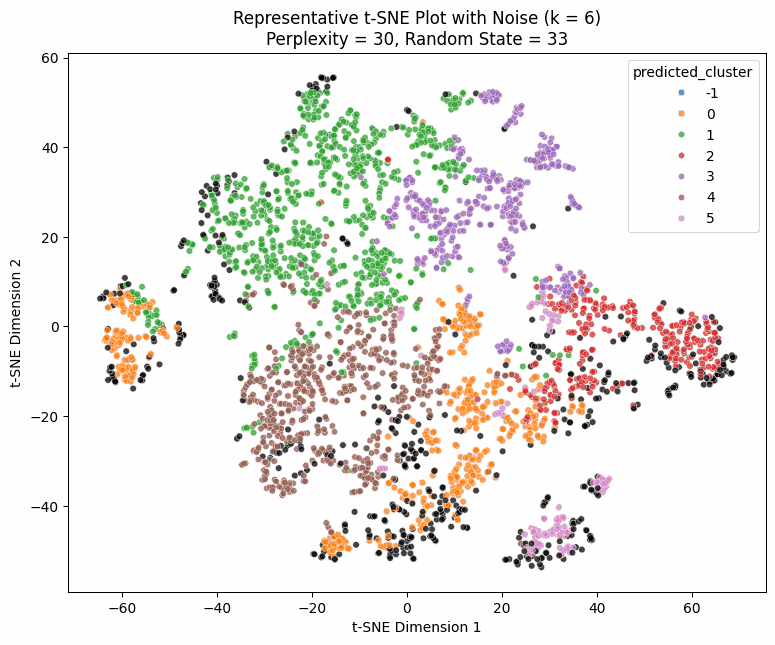

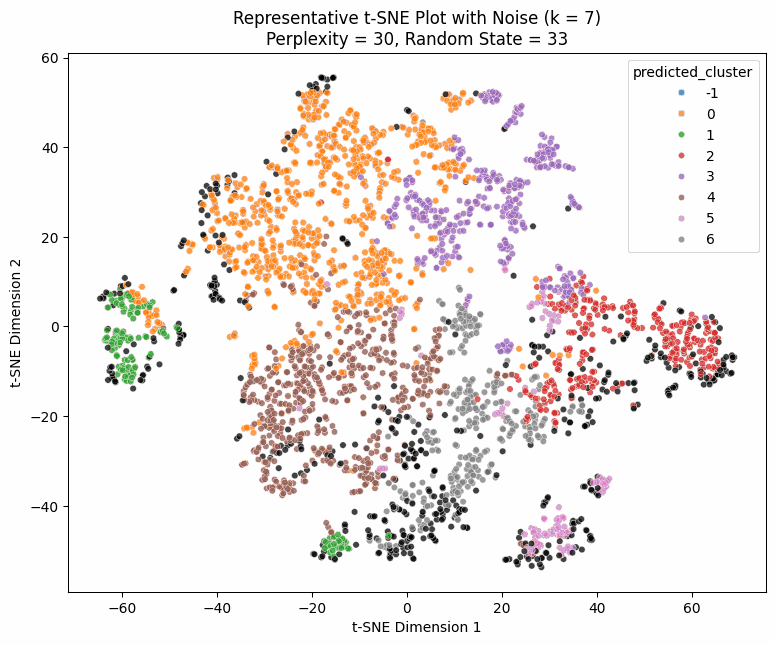

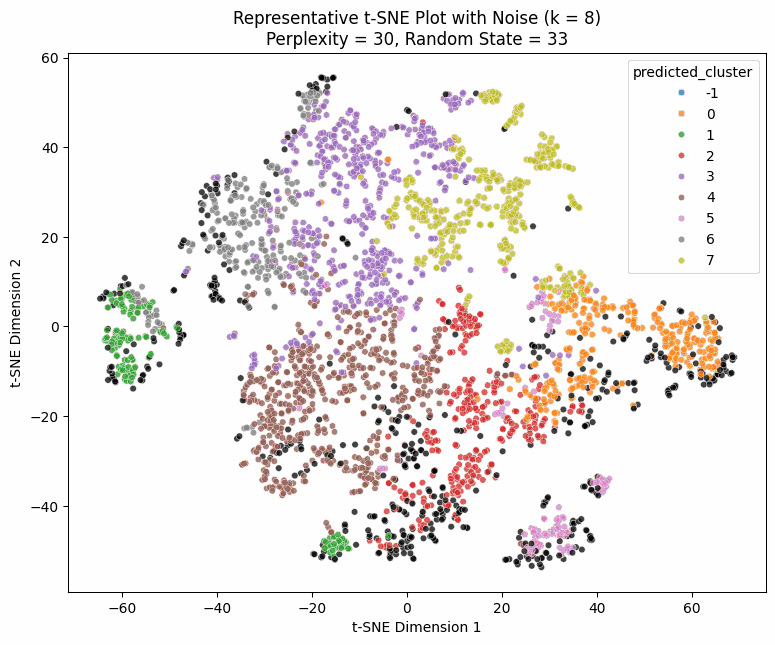

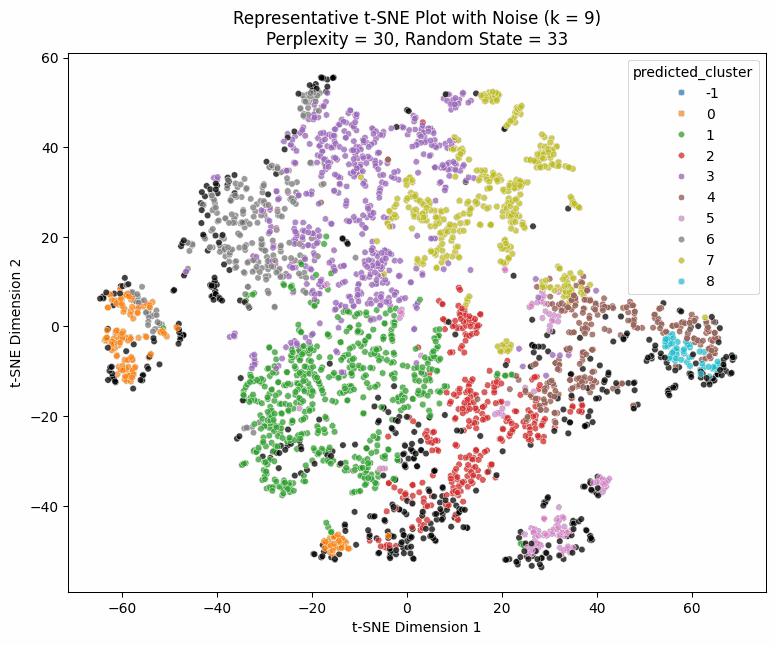

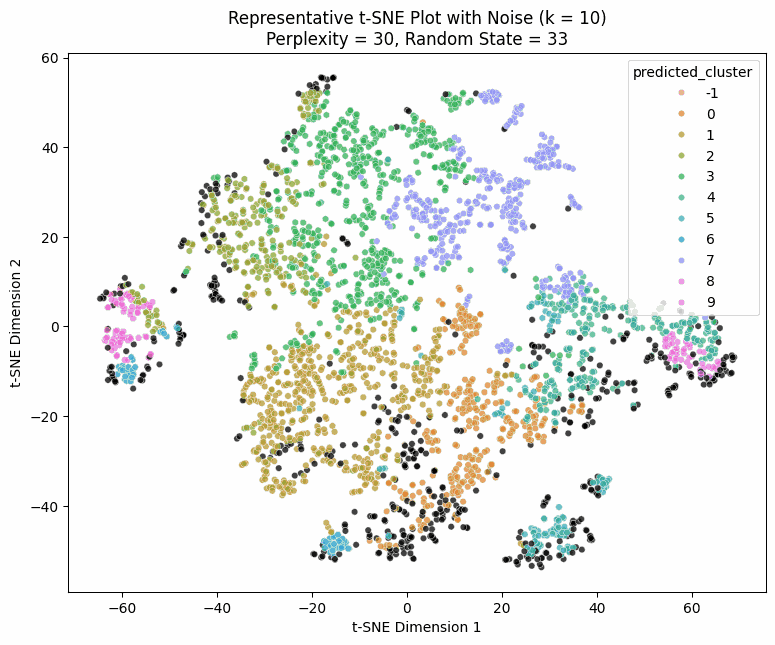

In [196]:
noise_beers = noise_beers.rename(columns={'dbscan_label': 'predicted_cluster'}) 
df_combo_combined = no_noise_beers.copy()

for k in range(2,11):
    hac = AgglomerativeClustering(n_clusters=k, metric='euclidean', linkage="complete")
    df_combo_combined['predicted_cluster'] = hac.fit_predict(no_noise_beers).astype(int).astype(str)
    combined_beers = pd.concat([df_combo_combined, noise_beers, df_tsne[['tsne_x', 'tsne_y']]], axis=0).sort_index()
    hue_order = ['-1'] + [str(i) for i in range(k)]

    plt.figure(figsize=(9, 7)) 
    sns.scatterplot(data=combined_beers, x="tsne_x", y="tsne_y", s=22, alpha=0.75, hue='predicted_cluster', hue_order = hue_order)
    plt.title( f"Representative t-SNE Plot with Noise (k = {k})\n" f"Perplexity = {30}, Random State = {33}") 
    plt.xlabel("t-SNE Dimension 1") 
    plt.ylabel("t-SNE Dimension 2") 
    plt.show()


노이즈를 뺀 데이터에서는 큰 주요 군집을 훨씬 잘 찾았습니다. 특히 k=2, 3에서 개선이 뚜렷했고, k가 커져도 멀리 떨어진 소수의 관측치에 끌려가지 않고 넓은 영역 패턴을 잡았습니다.

이웃 영역 사이에 여전히 겹침은 있었지만, 맛 특성이 서서히 이어지거나 서로 다른 맥주 유형이 실제로 비슷하다는 뜻으로 해석하는 것이 합리적이라고 보았습니다(t-SNE는 실제 거리를 그대로 보존하지 않습니다).

정리하면, 노이즈를 뺀 뒤 군집 구조가 더 균형 잡히고 해석하기 쉬워졌으며, 맥주 프로필의 유사성이 뚜렷이 나뉘기보다 점진적으로 변한다는 점도 드러났습니다.

그중 **k=7**이 t-SNE에서 보이는 군집과 가장 잘 맞고 해석하기 쉬웠습니다. 이 선택이 다른 지표와도 맞는지 실루엣 점수와 거리 행렬로 확인했습니다.

### 8.7. 노이즈를 뺀 뒤의 평균 실루엣 점수

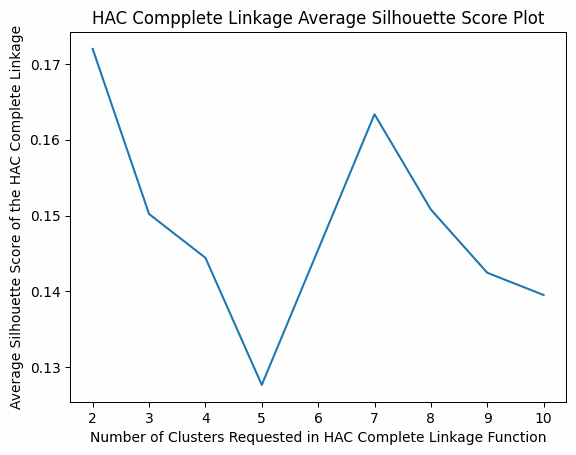

Max silhouette score: 0.1719730138467528
Max numbers of clusters: 2


In [184]:
cluster_num_list=range(2,11)

avg_sil_score_list=[]
for k in cluster_num_list:
    hac = AgglomerativeClustering(n_clusters=k, metric='euclidean', linkage="complete")
    cluster_labels = hac.fit_predict(no_noise_beers)
    avg_sil_score=silhouette_score(no_noise_beers, cluster_labels, metric='euclidean')
    avg_sil_score_list.append(avg_sil_score)

plt.plot(cluster_num_list,avg_sil_score_list)
plt.xlabel('Number of Clusters Requested in HAC Complete Linkage Function')
plt.ylabel('Average Silhouette Score of the HAC Complete Linkage')
plt.title('HAC Compplete Linkage Average Silhouette Score Plot')
plt.show()

print("Max silhouette score:", max(avg_sil_score_list))
print("Max numbers of clusters:", cluster_num_list[avg_sil_score_list.index(max(avg_sil_score_list))])

- 평균 실루엣 점수는 k=2에서 0.172로 가장 높았고, k=7이 두 번째였습니다.
- 최댓값은 k=2였지만, t-SNE와 더 잘 맞는 k=7이 군집 구조를 더 의미 있게 보여 준다고 판단했습니다.

노이즈를 뺀 데이터의 최고 실루엣(0.17)은 원본(0.73)보다 훨씬 낮았습니다. 원본의 높은 점수는 이상치가 군집 사이 거리를 부풀려 생긴 것이므로, 실루엣이 높다고 더 의미 있는 구조는 아니었습니다. 노이즈를 뺀 뒤 점수가 낮아진 것은 원래 서로 가까운 주 군집 내부를 나눴기 때문이며, 군집화가 나빠졌다기보다 맥주 프로필이 원래 점수가 보여 준 것보다 서로 비슷하다는 뜻으로 해석했습니다.

### 8.8. 군집 정렬 거리 행렬

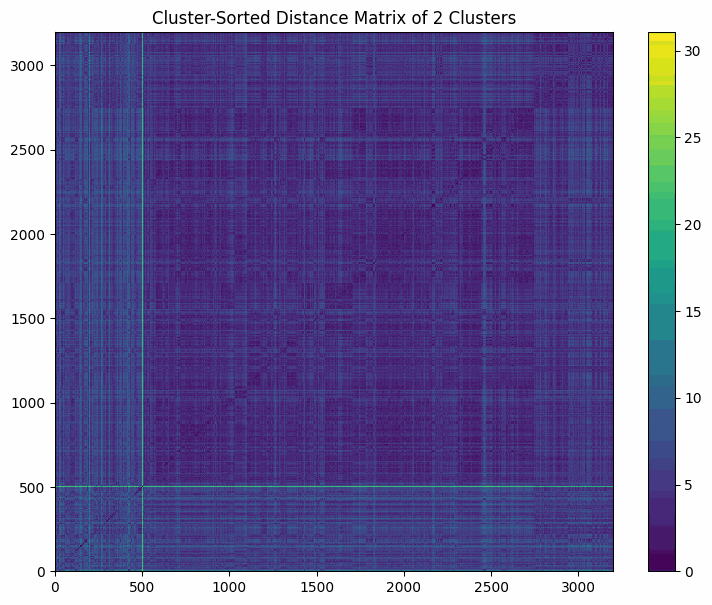

predicted_cluster
-1     513
 0    2745
 1    3197
Name: count, dtype: int64


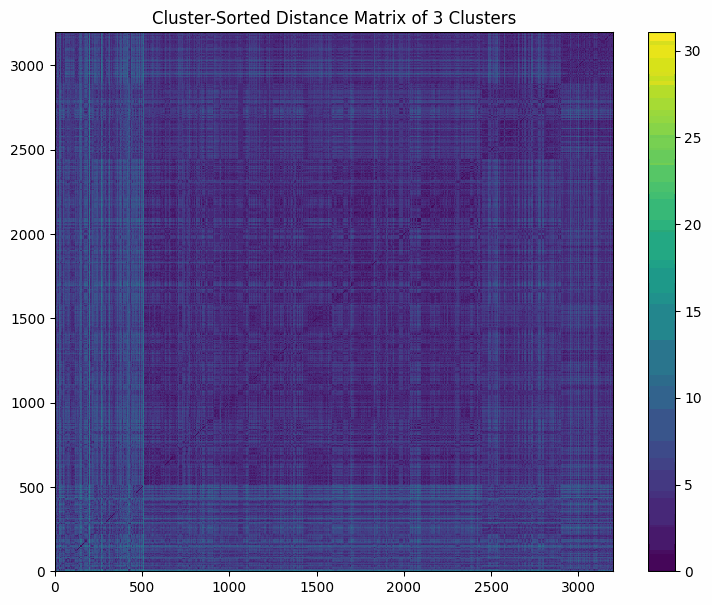

predicted_cluster
-1     513
 0    2447
 1    2899
 2    3197
Name: count, dtype: int64


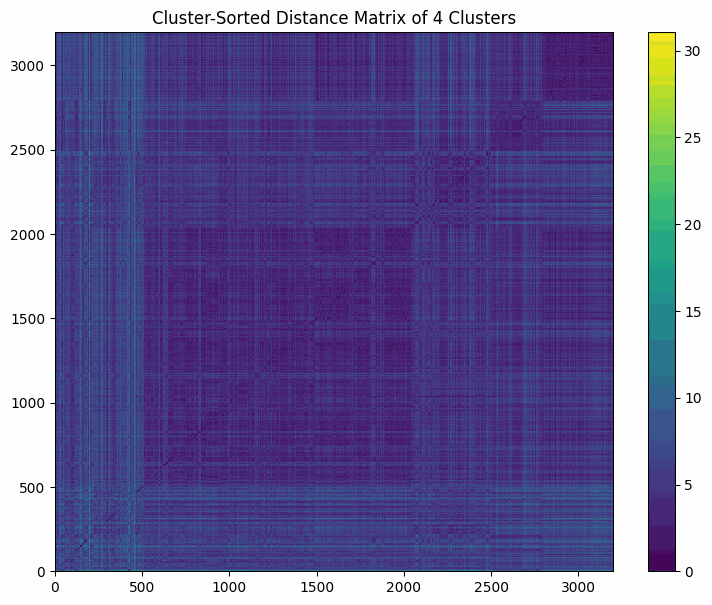

predicted_cluster
-1     513
 0    2039
 1    2491
 2    2789
 3    3197
Name: count, dtype: int64


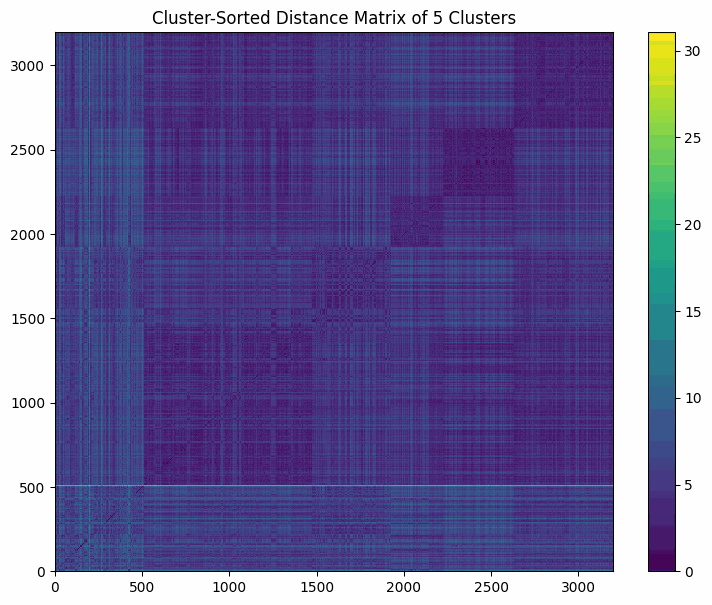

predicted_cluster
-1     513
 0    1473
 1    1925
 2    2223
 3    2631
 4    3197
Name: count, dtype: int64


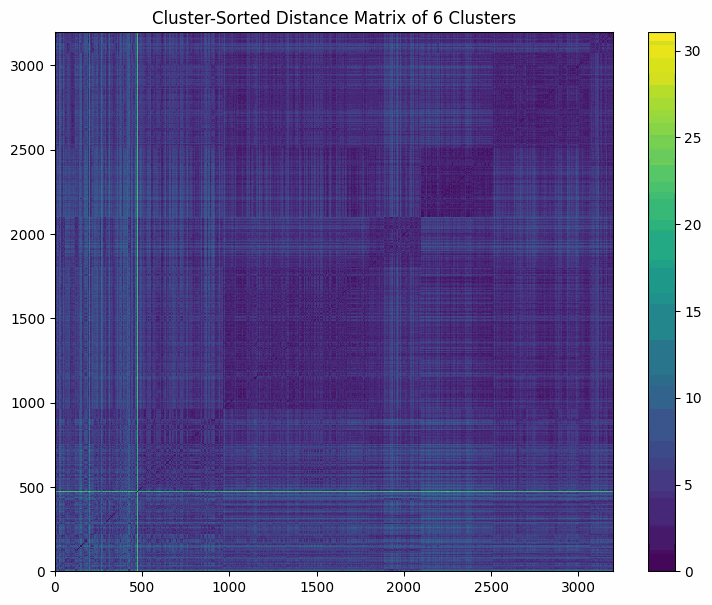

predicted_cluster
-1     513
 0     965
 1    1802
 2    2100
 3    2508
 4    3074
 5    3197
Name: count, dtype: int64


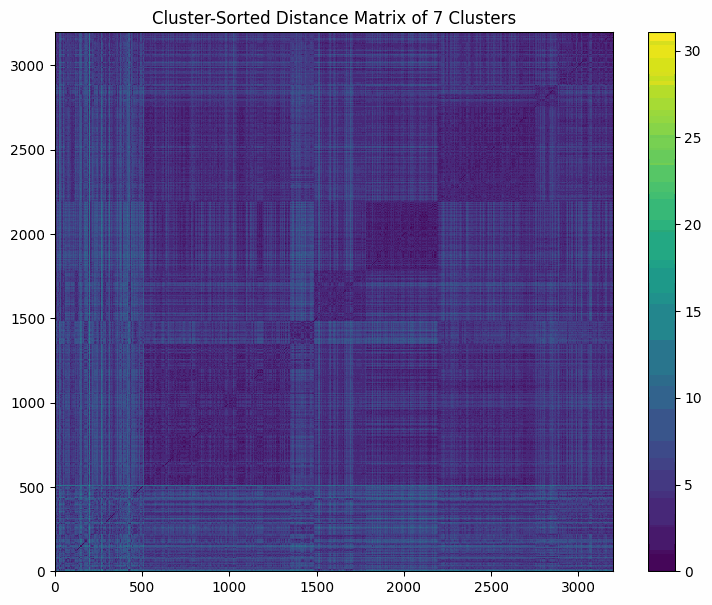

predicted_cluster
-1     513
 0    1350
 1    1487
 2    1785
 3    2193
 4    2759
 5    2882
 6    3197
Name: count, dtype: int64


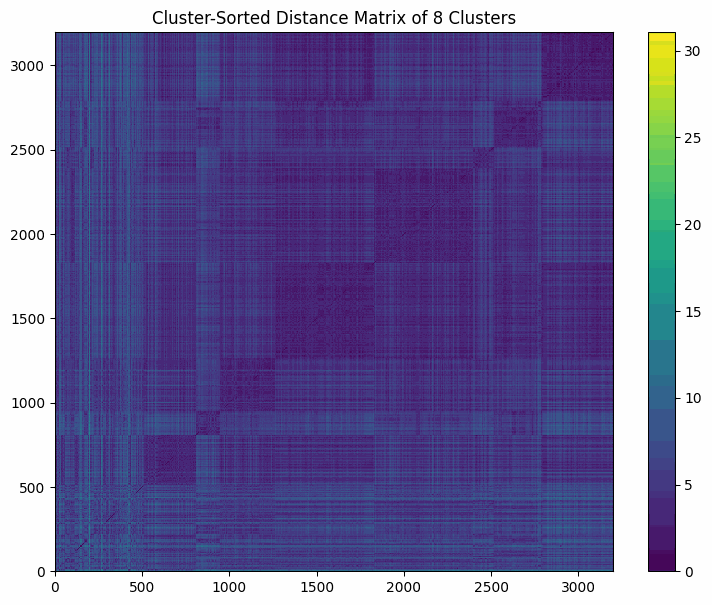

predicted_cluster
-1     513
 0     811
 1     948
 2    1263
 3    1827
 4    2393
 5    2516
 6    2789
 7    3197
Name: count, dtype: int64


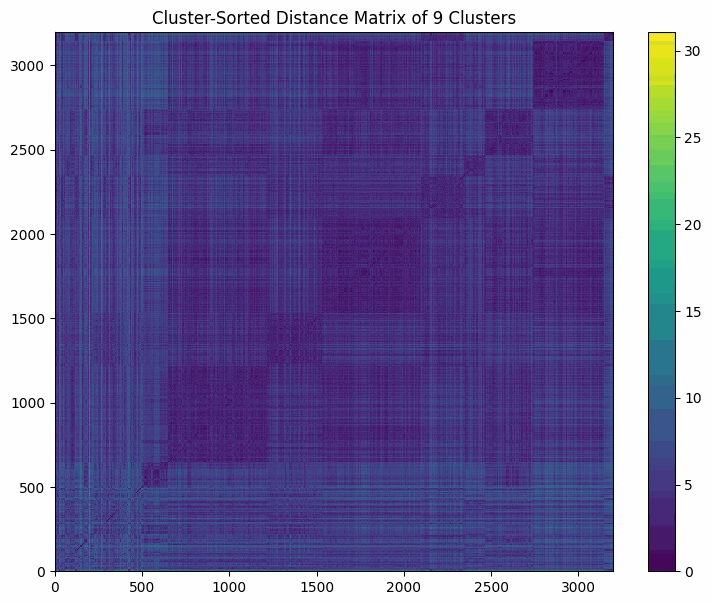

predicted_cluster
-1     513
 0     650
 1    1216
 2    1531
 3    2095
 4    2344
 5    2467
 6    2740
 7    3148
 8    3197
Name: count, dtype: int64


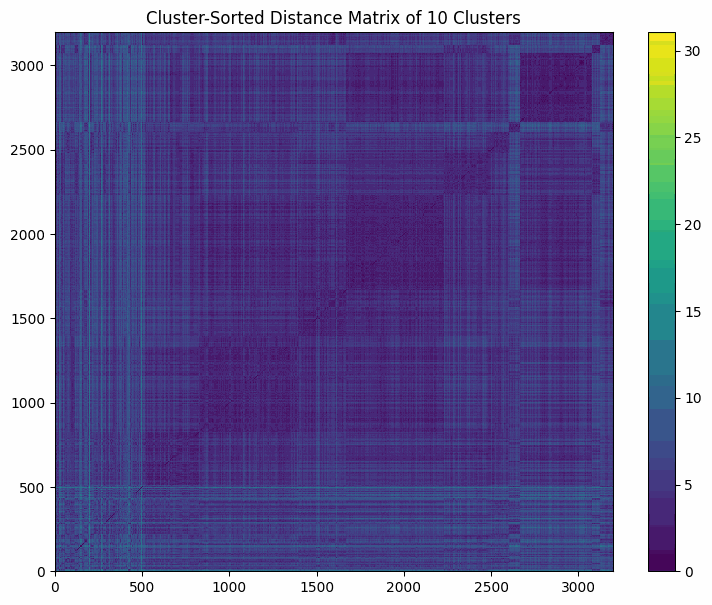

predicted_cluster
-1     513
 0     828
 1    1394
 2    1667
 3    2231
 4    2480
 5    2603
 6    2667
 7    3075
 8    3124
 9    3197
Name: count, dtype: int64


In [189]:
for k in range(2,11):
    hac = AgglomerativeClustering(n_clusters=k, metric='euclidean', linkage="complete")
    df_combo_combined['predicted_cluster'] = hac.fit_predict(no_noise_beers).astype(int)
    combined_beers = pd.concat([df_combo_combined, noise_beers], axis=0).sort_index()
    combined_beers_sort = combined_beers.sort_values(by=['predicted_cluster'])
    combined_beers_sort=combined_beers_sort.drop(['predicted_cluster'], axis=1)

    plt.figure(figsize=(9, 7))
    plt.title(f'Cluster-Sorted Distance Matrix of {k} Clusters')
    dist_mat = squareform(pdist(combined_beers_sort))
    plt.pcolormesh(dist_mat)
    plt.colorbar()
    N = len(combined_beers_sort)
    plt.xlim([0,N])
    plt.ylim([0,N])
    plt.show()

    end_points = combined_beers['predicted_cluster'].value_counts().sort_index().cumsum()
    print(end_points)

군집 정렬 행렬은 군집 내부의 응집도와 군집 간 분리를 보여 줍니다. 대각선 블록은 같은 군집 안의 거리, 나머지 영역은 다른 군집 사이의 거리이며, 구조가 뚜렷할수록 대각 블록은 어둡고(군집 내부 거리가 작음) 나머지는 밝게(군집 간 거리가 큼) 나타납니다.

- **k=2, 3, 4:** 블록이 보였지만 흐릿해, 서로 다른 맥주 그룹이 한 군집에 섞여 있을 수 있다고 보았습니다.
- **k=5~9:** 대각 블록의 경계가 뚜렷해, 낮은 k보다 군집이 잘 정의되고 분리되었습니다.
- **k=10:** 블록은 남아 있었지만 덜 뚜렷해 군집 간 분리가 약해졌습니다. 큰 군집을 서로 크게 다르지 않은 작은 그룹으로 과분할한 것으로 보았습니다.

종합하면 k=7과 k=9에서 응집도와 분리도의 근거가 가장 강했습니다. k=7은 주요 구조를, k=9는 주요 구조를 특정 맛·스타일의 하위 군집으로 더 나눈 결과로 판단했습니다.

### 8.9. 이상치·노이즈 처리 평가

- complete linkage는 이상치에 비교적 강하지만, 남아 있는 영향을 줄이기 위해 DBSCAN이 찾은 이상치를 빼고 군집화했습니다.
- 노이즈로 분류된 맥주를 곧바로 잘못된 데이터로 보지 않았습니다. 도수·쓴맛·단맛·바디감 등의 조합이 독특한 틈새 스타일일 수 있어, 개성이 다양한 틈새 맥주를 나타내는 별도 그룹으로 해석했습니다. 이렇게 해서 주요 구조와 구분하면서도 이 맥주들의 개성을 보존했습니다.

정제된 데이터로 모델을 학습한 뒤 이상치를 다시 더해, 연구 목표에 맞게 맥주 유형을 더 폭넓게 보여 주었습니다.

### 8.10. 최적 군집 선택

t-SNE 비교, 평균 실루엣 점수, 군집 정렬 행렬을 종합하면 노이즈를 뺀 데이터에서 k=7, 8, 9가 구조를 잘 설명했습니다.

- **t-SNE:** 세 경우 모두 잘 나뉜 그룹을 찾으면서 합리적인 하위 군집을 보여 주었습니다. 다만 k=9부터 기존 군집을 쪼개기 시작해 과분할 신호가 보였습니다.
- **실루엣:** 세 후보 중 k=7이 가장 높아, 응집도와 분리도가 가장 좋고 군집별 특성도 가장 뚜렷할 것으로 판단했습니다.
- **거리 행렬:** k=7이 세 후보 중 대각 블록 대비가 가장 뚜렷했습니다. k=7과 8은 k=9보다 군집 크기가 고르고, 그중 k=7의 경계가 더 분명했습니다. k=8은 경계가 약간 약했고, k=9는 과분할되기 쉬웠습니다.

데이터의 큰 내재 구조를 찾고 의미 있는 맛 프로필 세그먼트를 보여 주는 것이 목표였으므로 **k=7**을 최종 선택했습니다. 주요 구조를 뚜렷하게 잡고, 그룹 간 분리가 적당하며, 큰 k에서 나타나는 과분할을 피할 수 있었습니다.

### 8.11. 방법의 한계

#### 평균 실루엣 점수
실루엣이 가장 높다고 가장 좋은 군집 수는 아니었습니다. 실루엣은 멀리 떨어져 있으면서 자기 군집 안에서 촘촘한 점이 많을수록 높아집니다. 그런데 이 데이터는 맛이 서서히 이어지는 맥주가 많아 내재 군집 자체가 촘촘하고 덜 분리되어 있었습니다. 이럴 때 실루엣을 최대화하면 특성이 뚜렷한 작은 군집만 떼어 내는 단순한 구조가 선택되어, 세부 맛 프로필을 보여 주려는 연구 목표와 맞지 않았습니다.

#### 군집 정렬 거리 행렬
이 행렬도 완벽한 평가 도구는 아니었습니다. 5장에서 확인했듯 군집이 둥글지 않고 휘거나 길쭉하거나 서로 이어져 있어, t-SNE와 잘 맞는 군집이라도 경계가 깔끔하게 나오지 않을 수 있었습니다. 여러 세그먼트에 걸친 맥주가 있어 블록 경계도 흐려졌습니다. 좋은 구조가 항상 뚜렷한 블록으로 보이는 것도, 나쁜 군집 수가 항상 흐린 블록으로 보이는 것도 아니어서, 이 데이터에서는 블록 경계만으로 군집 수를 판단하기 어렵다고 보았습니다.

### 8.12. 최종 HAC 결과

노이즈를 뺀 데이터에 HAC complete linkage를 적용해 **k=7**을 최종 결과로 선택했습니다. 주요 구조를 뚜렷하게 잡고, 그룹 간 분리가 적당하며, 큰 k에서 나타나는 과분할을 피하는 가장 균형 잡힌 결과로 판단했습니다.

아래에 t-SNE 색칠 그래프, 이상치를 포함한 덴드로그램, 이상치를 뺀 덴드로그램(모두 200개 단위로 축약)을 표시했습니다.

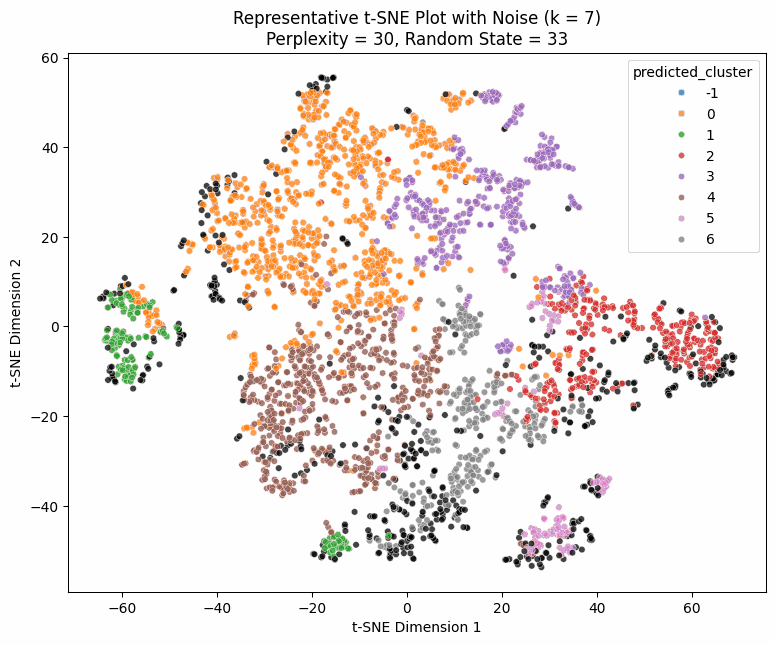

In [217]:
hac = AgglomerativeClustering(n_clusters=7, metric='euclidean', linkage="complete")
df_combo_combined['predicted_cluster'] = hac.fit_predict(no_noise_beers).astype(int).astype(str)
combined_beers = pd.concat([df_combo_combined, noise_beers, df_tsne[['tsne_x', 'tsne_y']]], axis=0).sort_index()
hue_order = ['-1', '0', '1', '2', '3', '4', '5', '6']

plt.figure(figsize=(9, 7)) 
sns.scatterplot(data=combined_beers, x="tsne_x", y="tsne_y", s=22, alpha=0.75, hue='predicted_cluster', hue_order=hue_order)
plt.title( f"Representative t-SNE Plot with Noise (k = 7)\n" f"Perplexity = {30}, Random State = {33}") 
plt.xlabel("t-SNE Dimension 1") 
plt.ylabel("t-SNE Dimension 2") 
plt.show()

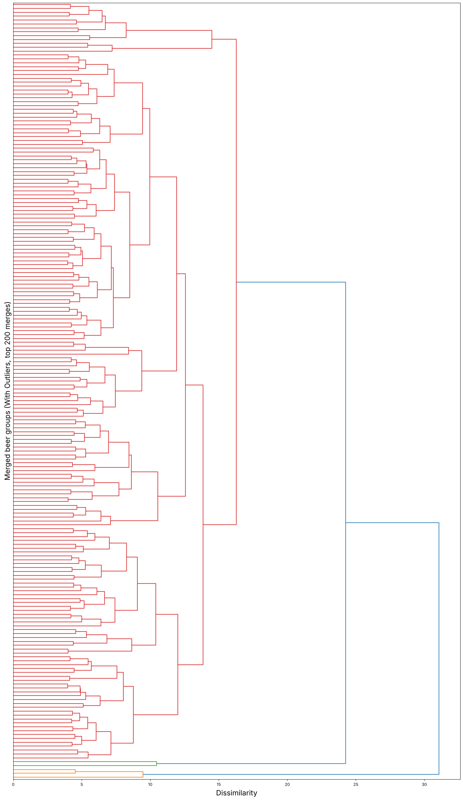

In [218]:
# t-SNE 좌표용으로 덧붙인 행을 제거 (아래 8.13에서 군집 라벨을 쓰기 위해 필요)
combined_beers = combined_beers.dropna(subset = ['Bitter', 'Sweet', 'Sour', 'Salty', 'Fruits', 'Hoppy', 'Spices', 'Malty'], how='all')

# 이상치를 포함한 전체 데이터(14개 변수)의 complete linkage 덴드로그램
fig, ax = plt.subplots(figsize=(20, 35))
d = dendrogram(Z_complete, orientation='right', truncate_mode='lastp', p=200, no_labels=True, ax=ax)
ax.set_xlabel('Dissimilarity', fontsize=18)
ax.set_ylabel('Merged beer groups (With Outliers, top 200 merges)', fontsize=18)
plt.yticks(fontsize=12)
plt.show()

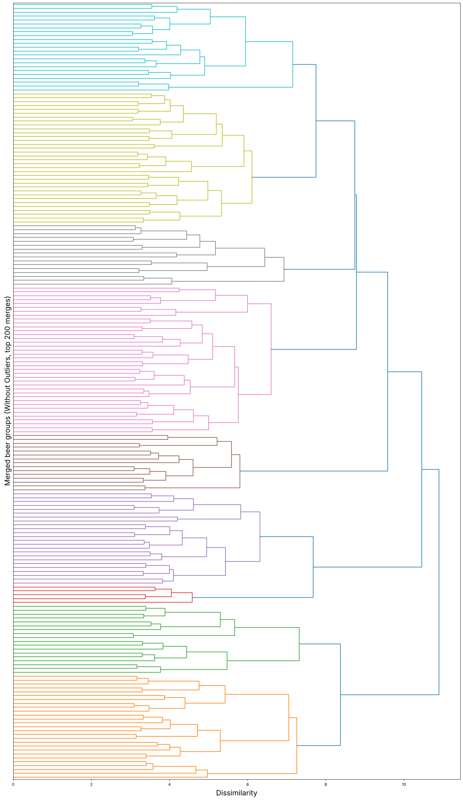

In [219]:
fig, ax = plt.subplots(figsize=(20, 35))
d = dendrogram(Z_complete_no_noise, orientation='right', truncate_mode='lastp', p=200, no_labels=True, ax=ax)
ax.set_xlabel('Dissimilarity', fontsize=18)
ax.set_ylabel('Merged beer groups (Without Outliers, top 200 merges)', fontsize=18)
plt.yticks(fontsize=12)
plt.show()

### 8.13. 군집별 특성 탐색

k=7 군집의 특성을 사양(도수·IBU), 맛 프로필, 리뷰 점수의 세 부분으로 나눠 해석했습니다.

데이터에 이상치가 있어 군집별 평균은 참고용으로만 표시했고, 주된 비교는 분포를 보여 주는 상자그림으로 했습니다. 먼저 사양을 살펴보았습니다.

In [231]:
specific_cols = ['ABV', 'Min IBU', 'Max IBU']

df_beer['predicted_cluster'] = combined_beers.loc[df_beer.index, 'predicted_cluster']
specific_summary = df_beer.groupby("predicted_cluster")[specific_cols].mean()
specific_summary

,ABV,Min IBU,Max IBU
predicted_cluster,,,
-1,8.380780,24.148148,49.959064
0,5.238196,21.045400,36.228196
1,9.178248,55.072993,88.248175
2,6.080000,12.087248,26.436242
3,4.967647,11.894608,21.365196
4,6.171820,22.729682,39.401060
5,6.126016,16.747967,36.585366
6,9.013651,21.542857,41.914286


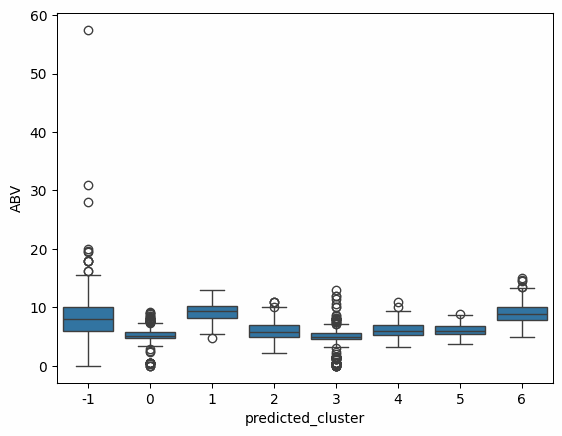

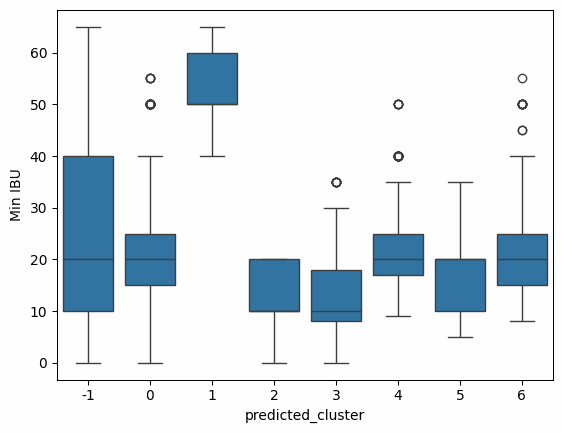

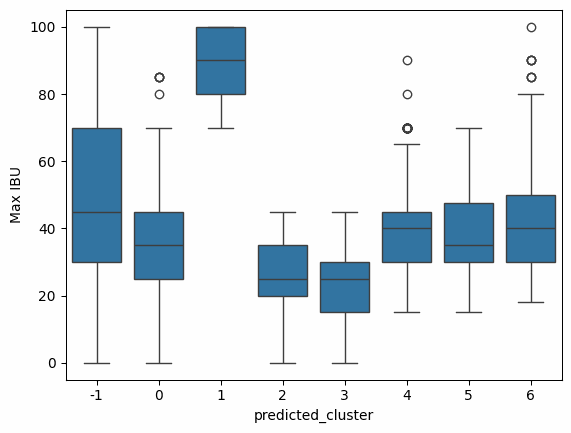

In [237]:
for cat in specific_cols:
    sns.boxplot(x="predicted_cluster", y=cat, data=df_beer, order=[-1, 0, 1, 2, 3, 4, 5, 6])
    plt.show()

#### 8.13.1. 사양 해석

- **ABV(도수):** 모든 군집의 중앙값이 비슷했고, 군집마다 극단값이 있었습니다. 노이즈 그룹(-1)은 수염이 길고 극단값이 많아 변동이 가장 컸습니다.
- **Min IBU:** 군집 0, 4, 6은 중앙값, 사분위 범위, 수염 길이가 비슷했고 위쪽 극단값이 있었습니다. 노이즈 그룹은 중앙값은 비슷했지만 더 넓게 퍼져 있었습니다. 군집 1은 중앙값이 훨씬 높았고, 군집 2, 3, 5는 낮았습니다.
- **Max IBU:** Min IBU와 비슷한 패턴이었습니다. 군집 0, 4, 6이 비슷했고, 노이즈 그룹은 양쪽으로 더 퍼져 있었으며, 군집 1은 훨씬 높고 나머지 세 군집은 낮았습니다.

정리하면 도수는 군집 간 차이가 크지 않았고(일부 극단값 제외), IBU는 군집에 따라 달랐습니다. 다음으로 맛 프로필을 살펴보았습니다.

In [230]:
profile_features = [
    'Astringency', 'Body', 'Alcohol',
    'Bitter', 'Sweet', 'Sour', 'Salty',
    'Fruits', 'Hoppy', 'Spices', 'Malty'
]

df_beer['predicted_cluster'] = combined_beers.loc[df_beer.index, 'predicted_cluster']
taste_summary = df_beer.groupby("predicted_cluster")[profile_features].mean()
taste_summary

,Astringency,Body,Alcohol,Bitter,Sweet,Sour,Salty,Fruits,Hoppy,Spices,Malty
predicted_cluster,,,,,,,,,,,
-1,19.290448,57.602339,31.943470,40.592593,82.175439,54.122807,1.859649,60.395712,45.598441,34.732943,88.146199
0,20.897252,38.244922,8.593787,45.144564,41.746714,23.921147,1.757467,25.763441,63.051374,7.814815,75.428913
1,14.109489,54.766423,24.131387,66.883212,63.065693,39.766423,0.408759,54.343066,71.759124,11.773723,75.948905
2,24.184564,33.265101,11.929530,15.778523,58.761745,85.677852,0.848993,78.479866,26.187919,19.919463,38.835570
3,8.002451,17.745098,5.583333,11.732843,20.477941,11.431373,0.284314,12.468137,15.098039,8.897059,32.161765
4,13.750883,72.181979,14.832155,51.846290,71.591873,16.397527,0.371025,21.401060,36.715548,12.597173,116.058304
5,12.341463,51.471545,13.000000,23.991870,48.577236,19.040650,0.528455,38.056911,21.016260,73.439024,77.260163
6,11.771429,44.676190,37.507937,21.266667,89.498413,34.641270,0.403175,56.885714,23.838095,22.063492,70.438095


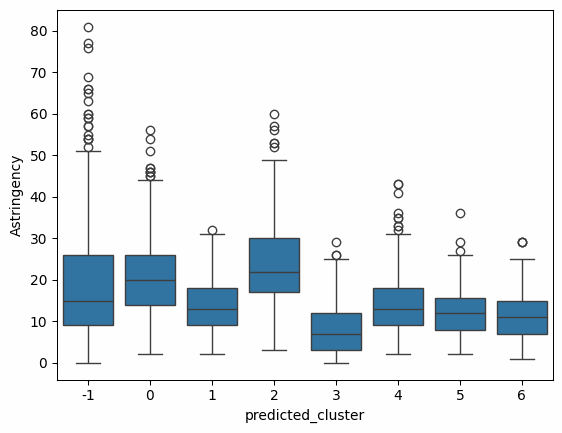

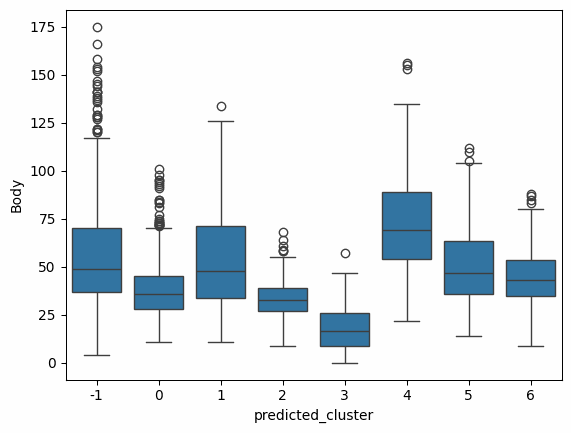

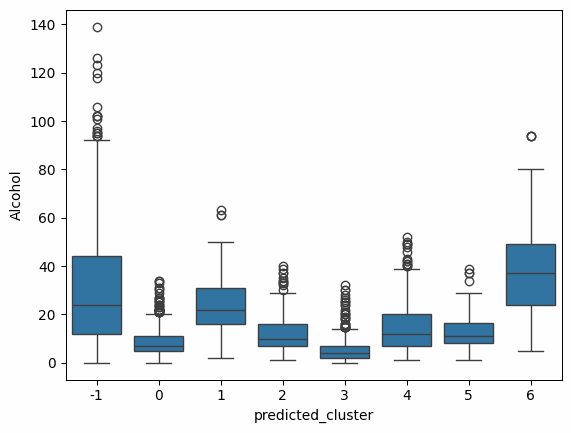

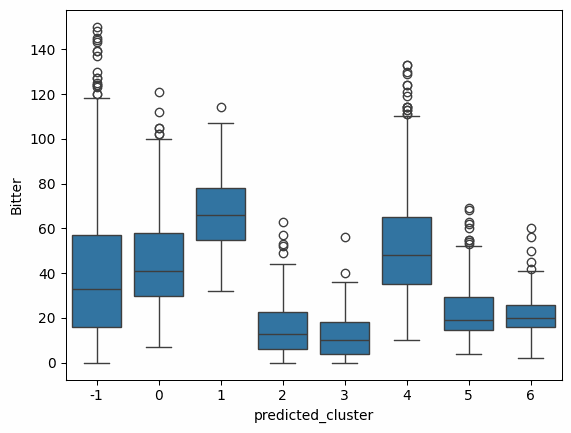

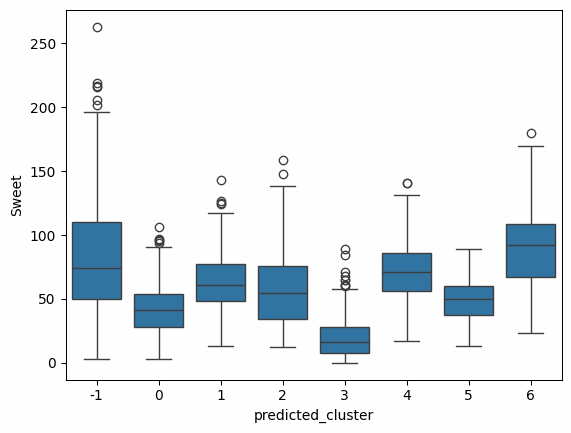

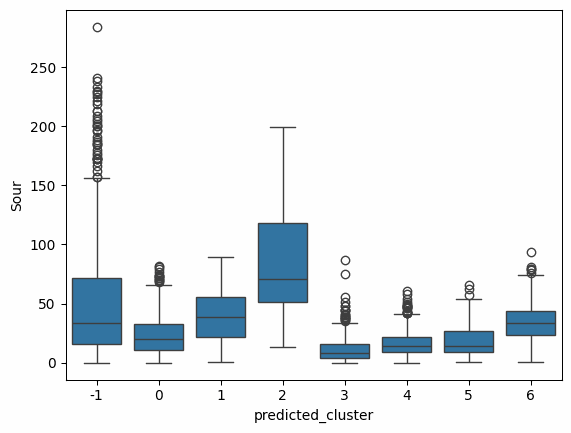

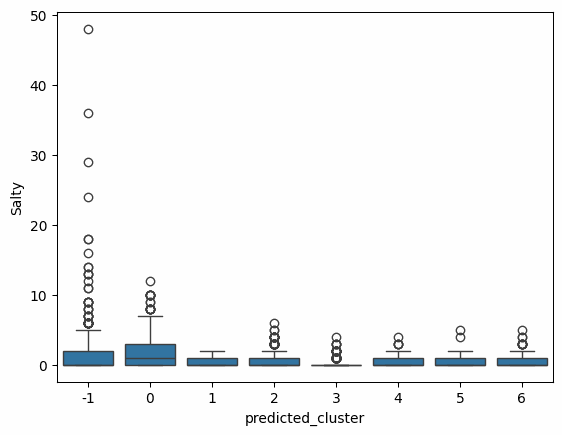

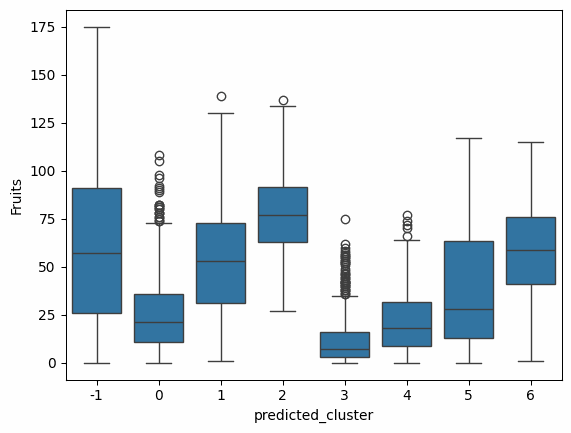

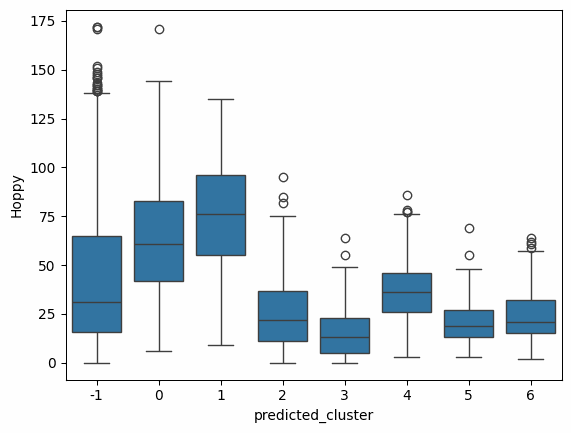

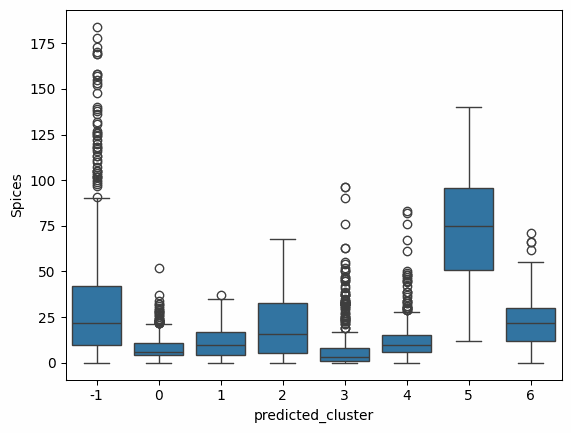

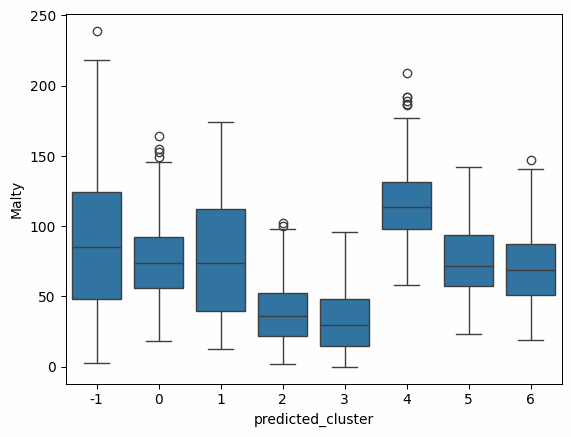

In [238]:
for cat in profile_features:
    sns.boxplot(x="predicted_cluster", y=cat, data=df_beer, order=[-1, 0, 1, 2, 3, 4, 5, 6])
    plt.show()

#### 8.13.2. 맛 프로필 해석

- **Body·Malty:** 두 변수의 군집별 패턴이 비슷했습니다. 군집 4가 가장 높고 군집 3이 가장 낮았으며, 군집 2가 두 번째로 낮았고, 군집 0, 1, 5, 6과 노이즈 그룹은 비슷했습니다. 바디감이 묵직할수록 몰트 향도 강한 경향과 맞는 결과였습니다.
- **Fruits·Sour:** 군집 간 패턴이 비슷했지만 과일 향의 변동이 더 컸습니다. 군집 2가 신맛·과일 향 모두 가장 높고 군집 3이 가장 낮았습니다. 군집 1, 6은 중간, 군집 0, 4, 5는 낮은 편이었습니다.
- **Spices:** 비슷한 패턴이었지만 군집 5가 가장 높고 군집 2는 중간이었습니다.
- **Sweet:** 군집 6이 가장 높고 군집 3이 가장 낮았습니다. 과일 향 맥주는 달거나 시거나 할 수 있고, 일부 제품은 향신료로 맛을 더 복합적으로 만드는 것으로 보았습니다. 양조장이 이런 특성을 조합해 차별화된 스페셜티 맥주를 만든다고 해석했습니다.
- **Salty:** 모든 군집이 비슷하게 낮았고 군집마다 극단값이 있었습니다. 대중적인 맥주는 짠맛을 강조하지 않지만, 일부 양조장은 짠맛을 의도적인 차별점으로 삼는다고 보았습니다.
- **Bitter·Hoppy:** 두 변수의 패턴이 매우 비슷해 함께 나타나는 경향이 강했습니다. 군집 1이 가장 높고 군집 3이 가장 낮았으며 군집 2가 그 바로 위였습니다. 군집 0, 4는 중간, 군집 5, 6과 노이즈 그룹은 낮은 편이었습니다. 홉이 강할수록 쓴맛도 강하게 느껴진다는 점과 맞는 결과였습니다.
- **Astringency(떫은맛):** 군집 2가 가장 높고 군집 0도 높은 편이었으며, 노이즈 그룹은 변동이 커 일부 독특한 맥주는 떫은맛이 강했습니다. 군집 3은 가장 낮고 분포도 가장 좁았습니다. 군집 1, 4, 5, 6은 중간이었습니다. 질감이 날카롭고 드라이한 그룹과 부드러운 그룹이 나뉘는 것으로 보았습니다.
- **Alcohol(알코올감):** 군집 6이 가장 높고 군집 3이 가장 낮았습니다. 다른 맛 변수와 달리 도수(사양)와 더 가까워, 가벼운 맥주와 강한 맥주를 가르는 큰 구조적 차이를 보여 준다고 판단했습니다.

다음으로 이런 제품 차이가 소비자 평가에 어떻게 나타나는지 리뷰 점수를 살펴보았습니다.

In [247]:
review_cols = [
    'review_aroma',
    'review_appearance',
    'review_palate',
    'review_taste',
    'review_overall',
]

df_beer['predicted_cluster'] = combined_beers.loc[df_beer.index, 'predicted_cluster']
review_summary = df_beer.groupby("predicted_cluster")[review_cols].mean()
review_summary['number_of_reviews'] = df_beer.groupby("predicted_cluster")['number_of_reviews'].sum()
review_summary

,review_aroma,review_appearance,review_palate,review_taste,review_overall,number_of_reviews
predicted_cluster,,,,,,
-1,3.918070,3.903864,3.860173,3.948596,3.883738,101494
0,3.424807,3.648114,3.544383,3.549061,3.695803,191565
1,4.061782,4.085108,4.012340,4.083146,4.007410,75848
2,3.795925,3.816790,3.757759,3.799026,3.840703,81430
3,3.249243,3.402935,3.312377,3.316370,3.446579,48250
4,3.721684,3.870759,3.728945,3.803682,3.833004,125547
5,3.803469,3.837962,3.707070,3.781474,3.786646,23597
6,3.711216,3.804008,3.707827,3.740000,3.682844,98081


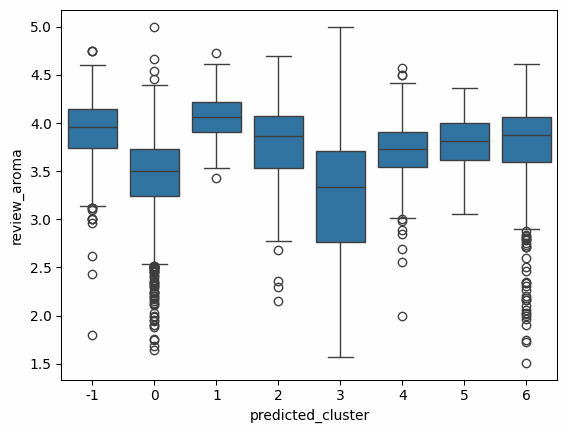

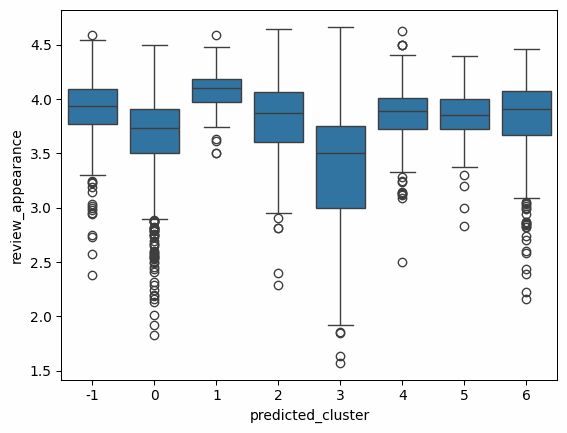

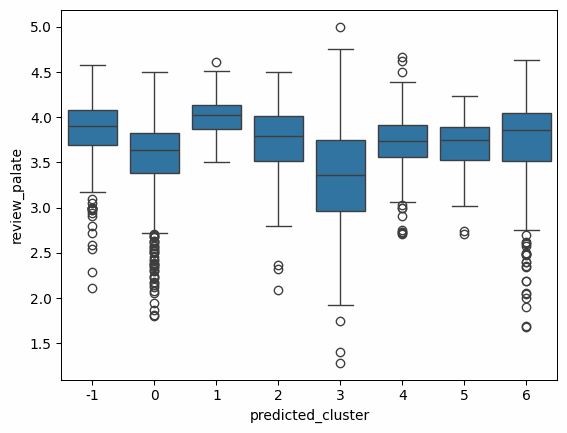

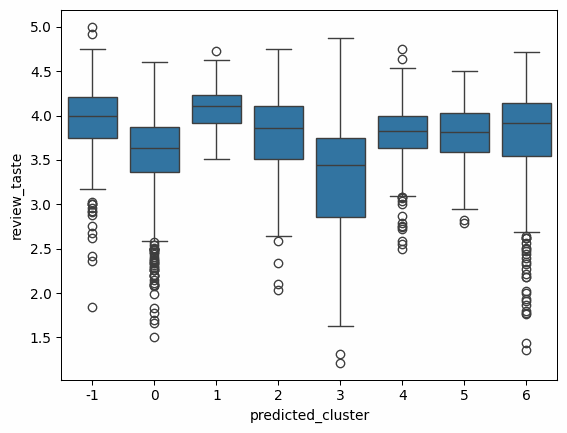

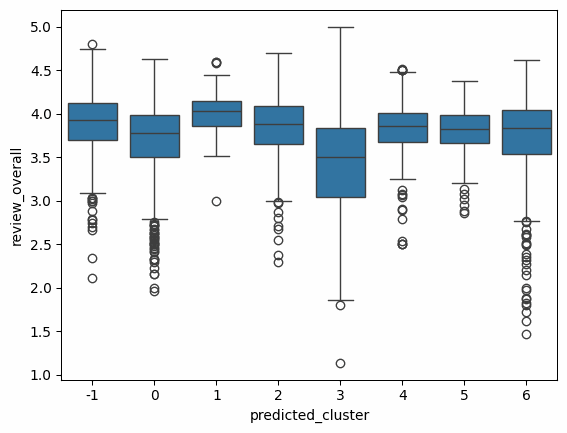

In [248]:
for cat in review_cols:
    sns.boxplot(x="predicted_cluster", y=cat, data=df_beer, order=[-1, 0, 1, 2, 3, 4, 5, 6])
    plt.show()

#### 8.13.3. 리뷰 점수 해석

- **향·외관·맛:** 군집 1이 가장 높았고, 군집 2, 4, 5, 6과 노이즈 그룹이 뒤를 이었습니다. 군집 3이 가장 낮았고 군집 0이 두 번째로 낮았습니다.
- **종합 점수:** 세부 점수와 같은 패턴이었지만 군집 간 차이는 더 작았습니다. 군집별 평균은 군집 1이 4.01로 가장 높고, 군집 3이 3.45로 가장 낮았습니다. 노이즈 그룹은 3.88이었습니다.

이어서 세 부분을 종합해 각 군집의 특징을 정리했습니다.

#### 8.13.4. 군집별 특징 종합

| 군집 | 특징 | 종합 평점 평균 | 해석 |
|---|---|---|---|
| 1 | IBU·쓴맛·홉·도수가 가장 높고 다른 풍미는 중간 | 4.01 (가장 높음) | 강하고 홉이 두드러지지만 다른 맛이 쓴맛을 받쳐 주는 인기 세그먼트 |
| 노이즈(-1) | 모든 변수의 분포가 가장 넓음 | 3.88 (두 번째) | 다양하고 독특하지만 소비자에게 인정받는 틈새 세그먼트 |
| 2, 4, 5, 6 | 도수는 비슷하고 각각 과일 향(2), 바디감·몰트(4), 향신료(5), 단맛(6)이 특히 높음 | 3.68~3.84 | 특정 맛에 특화되어 그 맛을 좋아하는 소비자에게 지지를 받는 그룹 |
| 0 | 쓴맛·홉은 높지만 과일·향신료·신맛·단맛·도수는 낮음 | 3.70 | 쓴맛은 군집 1과 비슷하지만 다른 풍미가 적어 평점이 군집 1보다 크게 낮았음 |
| 3 | 사양·맛 프로필 대부분이 가장 낮음 | 3.45 (가장 낮음) | 가볍고 순한 맥주. 평균은 낮지만 평점 분포가 넓어 선호가 갈렸음 |

- **군집 1과 군집 0의 비교:** 쓴맛과 홉은 둘 다 높았지만 평점은 군집 1이 훨씬 높았습니다. 쓴맛과 홉만으로는 소비자의 선호를 얻기 어렵고, 다른 풍미가 함께 있어야 좋은 평가로 이어진다고 해석했습니다.
- **군집 3:** 리뷰 점수의 분포가 넓어, 가벼운 맛을 좋아하는 소비자는 높게, 진한 맛을 좋아하는 소비자는 낮게 평가한 것으로 보았습니다. 평균은 낮아도 특정 취향의 소비자층이 있다고 판단했습니다.
- **군집 2, 4, 5, 6:** 평점 분포의 양 끝에 극단값이 있어, 특정 맛을 좋아하는 소비자가 높게 평가하는 "취향을 타는" 세그먼트로 보았습니다. 해당 양조장이나 브랜드에 대한 충성도가 높을 가능성도 있었습니다.

전반적으로 HAC complete linkage는 의미 있는 구조를 찾았고, 소비자 선호를 이해하는 데 필요한 정보를 제공했다고 판단했습니다.

## 9. 군집 알고리즘 3: K-Means

### 9.1. 엘보 그래프

In [287]:
kmeans_cols = [
    'ABV', 'Min IBU', 'Max IBU',
    'Astringency', 'Body', 'Alcohol', 'Bitter', 'Sweet',
    'Sour', 'Salty', 'Fruits', 'Hoppy', 'Spices', 'Malty',
]

X = df[kmeans_cols]

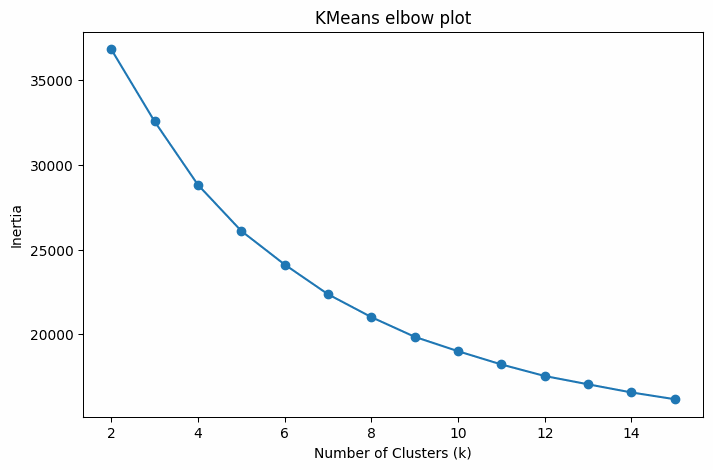

In [288]:
inertias = []

k_values = range(2, 16)

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=437, n_init=10)
    kmeans.fit(X)
    inertias.append(kmeans.inertia_)

plt.figure(figsize = (8,5))
plt.plot(k_values, inertias, marker = "o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("KMeans elbow plot")
plt.show()

### 9.2. 평균 실루엣 점수 그래프

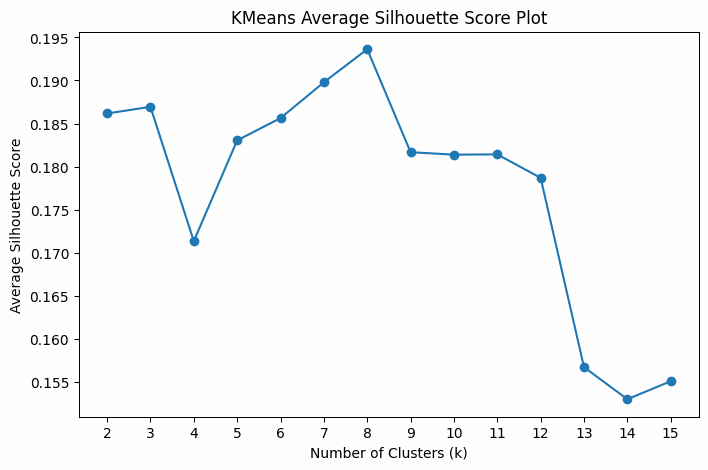

In [289]:
from sklearn.metrics import silhouette_score
silhouette_scores = []
k_values = range(2,16)

for k in k_values:
    kmeans = KMeans(n_clusters = k, random_state=437, n_init=10)
    cluster_labels = kmeans.fit_predict(X)
    score = silhouette_score(X, cluster_labels)
    silhouette_scores.append(score)

plt.figure(figsize=(8, 5))
plt.plot(k_values, silhouette_scores, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Average Silhouette Score")
plt.title("KMeans Average Silhouette Score Plot")
plt.xticks(k_values)
plt.show()

- **엘보 그래프:** 군집 수가 늘수록 inertia(각 점과 소속 군집 중심 사이 거리의 제곱합)가 꾸준히 줄어, 데이터에 의미 있는 구조가 있다고 보았습니다. 가장 크게 줄어드는 구간은 k=2~8 정도였고 그 뒤로는 완만해져, 군집을 더 늘려도 얻는 것이 적었습니다. 엘보 그래프로는 k=6~8을 후보로 정했습니다.
- **실루엣:** 전반적으로 점수는 크지 않았지만 k=8에서 가장 높아, 테스트한 K-Means 중 응집도와 분리도의 균형이 가장 좋았습니다. k=7과 더 작은 k도 비슷한 수준이어서, 큰 맥주 범주와 작은 하위 그룹이 함께 있을 수 있다고 보았습니다. 두 근거를 합쳐 k=8을 유력 후보로, k=7을 대안으로 판단했습니다.

### 9.3. t-SNE로 확인

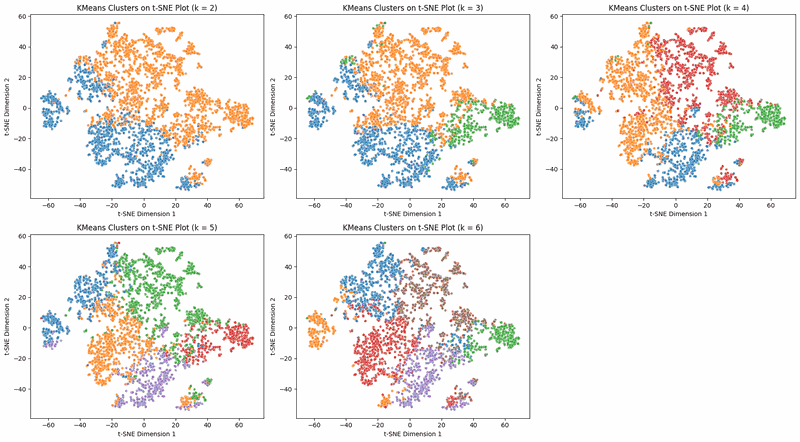

In [290]:
representative_perplexity = 30
representative_random_state = 33

df_tsne_kmeans = tsne_results[
    (representative_perplexity, representative_random_state)
].copy()

k_candidates = [2,3,4,5,6]
for k in k_candidates:
    kmeans = KMeans(n_clusters= k, random_state = 437, n_init=10)
    df_tsne_kmeans[f"kmeans_k{k}"] = kmeans.fit_predict(X)

fig, axes = plt.subplots(2,3, figsize = (18,10))
axes = axes.flatten()

for i,k in enumerate(k_candidates):
    sns.scatterplot(data = df_tsne_kmeans, x="tsne_x",
        y="tsne_y",
        hue=f"kmeans_k{k}",
        palette="tab10",
        s=18,
        alpha=0.75,
        ax=axes[i],
        legend=False
    )

    axes[i].set_title(f"KMeans Clusters on t-SNE Plot (k = {k})")
    axes[i].set_xlabel("t-SNE Dimension 1")
    axes[i].set_ylabel("t-SNE Dimension 2")
axes[-1].axis("off")
plt.tight_layout()
plt.show()

    



- t-SNE는 리뷰 변수를 빼고 맥주 자체의 프로필로만 그렸으므로, 여기서 보이는 군집은 평점이 아니라 도수·쓴맛·단맛·과일 향·홉·몰트 같은 맛 특성의 실제 차이를 반영할 가능성이 크다고 보았습니다.
- 그래서 t-SNE와 맞는다는 것을 K-Means 군집이 인기나 평점이 아닌 맥주 스타일 세그먼트를 잡는다는 근거로 삼았습니다. k=2, 3은 눈에 띄게 다른 맛 영역 여러 개를 합쳐 과소분할로 판단했습니다. 반면 k=5, 6은 t-SNE의 여러 분리된 영역과 더 잘 맞으면서 해석하기 쉬운 구조를 유지했습니다.

### 9.4. 군집 정렬 유사도 행렬

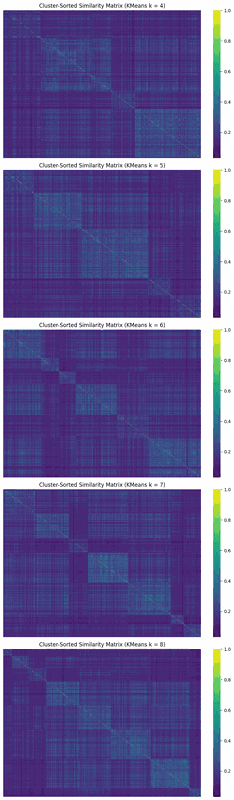

In [291]:
from sklearn.metrics.pairwise import euclidean_distances
from scipy.spatial.distance import squareform

dist_matrix = euclidean_distances(X)

sim_matrix = 1 / (1 + dist_matrix)

k_candidates = [4,5,6,7,8]

fig, axes = plt.subplots(len(k_candidates), 1, figsize=(8, 5 * len(k_candidates)))

for i, k in enumerate(k_candidates):
    
    kmeans = KMeans(n_clusters=k, random_state=437, n_init=10)
    labels = kmeans.fit_predict(X)
    
    sorted_index = np.argsort(labels)
    
    sorted_sim = sim_matrix[sorted_index, :][:, sorted_index]
    
    sns.heatmap(
        sorted_sim,
        cmap="viridis",
        xticklabels=False,
        yticklabels=False,
        cbar=True,
        ax=axes[i]
    )
    
    axes[i].set_title(f"Cluster-Sorted Similarity Matrix (KMeans k = {k})")

plt.tight_layout()
plt.show()

- 좋은 군집화일수록 대각선 블록이 밝고(군집 내부 유사도가 높음) 나머지 영역이 어둡게(군집 간 유사도가 낮음) 나타납니다.
- k=4는 블록이 보였지만 넓어, 서로 다른 맥주 그룹이 합쳐져 있을 수 있다고 보았습니다. k=5, 6은 블록이 더 뚜렷하고 분리가 강했으며, 특히 k=6이 응집도와 분리의 균형이 좋았습니다.
- k=7, 8도 구조가 뚜렷했지만 작은 군집이 생기기 시작했습니다. k=8은 시각적으로도 좋았고 실루엣도 가장 높았습니다. 종합하면 k=6과 k=8의 근거가 가장 강하다고 판단했습니다.

### 9.5. 이상치·노이즈 처리 평가

- 도수·쓴맛이 극단적이거나 맛 프로필이 특이한 맥주처럼 이상치가 있을 가능성이 컸고, t-SNE에서도 작은 고립 영역이 여러 개 보였습니다.
- K-Means는 모든 관측치를 어떤 군집에든 배정해야 해서 노이즈를 따로 찾지 못합니다. 이상치가 가장 가까운 군집에 억지로 들어가 응집도를 낮추거나 군집 중심을 왜곡할 수 있다는 점을 DBSCAN과 비교한 큰 한계로 보았습니다.
- 다만 이 프로젝트에서는 고립된 관측치가 무의미한 노이즈가 아니라 틈새 스타일일 수 있었습니다. K-Means는 이들을 버리지 않고 작은 세그먼트로 묶으므로 시장 세분화 용도로는 쓸 만하지만, 이상치 탐지에는 적합하지 않다고 판단했습니다.

### 9.6. 최적 군집 선택

- 엘보, 실루엣, t-SNE 비교, 유사도 행렬 모두에서 k=6과 k=8의 근거가 가장 강했습니다.
- **k=6:** 해석 가능성과 군집 품질의 균형이 가장 좋았습니다. t-SNE의 자연스럽게 분리된 영역과 잘 맞으면서 지나치게 쪼개지지 않았고, 유사도 행렬에서도 응집도와 분리가 뚜렷했습니다.
- **k=8:** 더 세분화된 결과로 실루엣이 가장 높았습니다. 큰 그룹 안의 하위 구조까지 잡아 세밀한 시장 세분화에 유용하다고 보았습니다.

큰 내재 군집을 해석하기 쉽게 찾는 것이 목표라면 k=6, 작은 틈새 그룹까지 세분화하는 것이 목표라면 k=8이 맞다고 판단했습니다.

### 9.7. 방법의 한계

- 맥주 스타일과 맛 프로필은 딱 나뉘기보다 연속선 위에 있어, 일반적인 군집 진단 도구의 쓸모가 제한적이었습니다. 쓴맛·단맛·홉·몰트·도수가 겹치는 맥주가 많아 군집 사이 경계가 점진적이었습니다.
- **엘보:** 정답인 군집 수가 하나로 나오지 않았습니다. 큰 범주와 그 안의 하위 그룹이 함께 있으면 엘보는 큰 구분만 잡고 하위 구조를 놓칠 수 있어, 여러 k가 모두 그럴듯해 보였습니다.
- **실루엣:** 실루엣은 촘촘하고 잘 분리된 그룹을 선호하므로, 군집 수가 적은 단순한 결과가 작은 틈새 세그먼트를 큰 그룹에 합치면서 더 높은 점수를 받을 수 있었습니다.
- **유사도 행렬:** 여러 세그먼트에 걸친 맥주 때문에 의미 있는 군집화에서도 블록이 흐려질 수 있어, 블록이 완벽하지 않은 것을 군집화 실패로 보지 않았습니다.

### 9.8. 최종 K-Means 결과

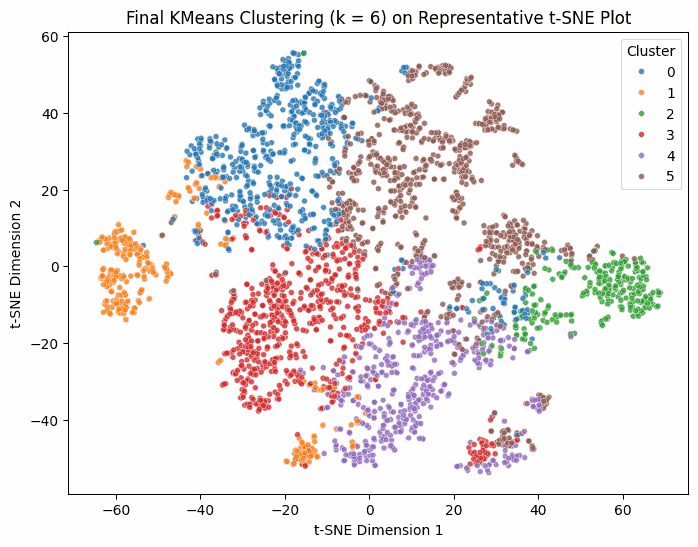

In [292]:
kmeans_final = KMeans(n_clusters=6, random_state=437, n_init=10)
final_labels = kmeans_final.fit_predict(X)
df["kmeans_final"] = final_labels

df_tsne_final = tsne_results[(30, 33)].copy()

df_tsne_final["cluster"] = final_labels

plt.figure(figsize=(8,6))

sns.scatterplot(
    data=df_tsne_final,
    x="tsne_x",
    y="tsne_y",
    hue="cluster",
    palette="tab10",
    s=18,
    alpha=0.8
)

plt.title("Final KMeans Clustering (k = 6) on Representative t-SNE Plot")
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.legend(title="Cluster")
plt.show()

- 여러 기준을 종합해 **k=6**을 K-Means의 최종 결과로 정했습니다.
- t-SNE에서 6개 군집이 자연스럽게 분리된 영역과 잘 맞았고, 지나치게 작은 군집으로 쪼개지지 않으면서 주요 그룹과 의미 있는 하위 구조를 함께 보여 주었습니다.
- 군집 크기를 보면 큰 주류 그룹과 작은 틈새 그룹이 섞여 있어, 다양한 맥주 데이터에서 기대할 수 있는 모습이었습니다.

### 9.9. 군집별 리뷰 점수 확인

In [293]:
review_cols = [
    'review_aroma',
    'review_appearance',
    'review_palate',
    'review_taste',
    'review_overall',
    'number_of_reviews'
]

review_summary = df.groupby("kmeans_final")[review_cols].mean()
review_summary.head()

,review_aroma,review_appearance,review_palate,review_taste,review_overall,number_of_reviews
kmeans_final,,,,,,
0,3.526538,3.710041,3.642668,3.644227,3.780792,187.807131
1,3.978772,4.037088,3.946110,4.012932,3.963906,483.142857
2,3.922400,3.886720,3.853094,3.932114,3.916055,211.563433
3,3.737517,3.884437,3.735083,3.813605,3.848004,211.543155
4,3.880180,3.896628,3.847255,3.913760,3.821007,282.031250


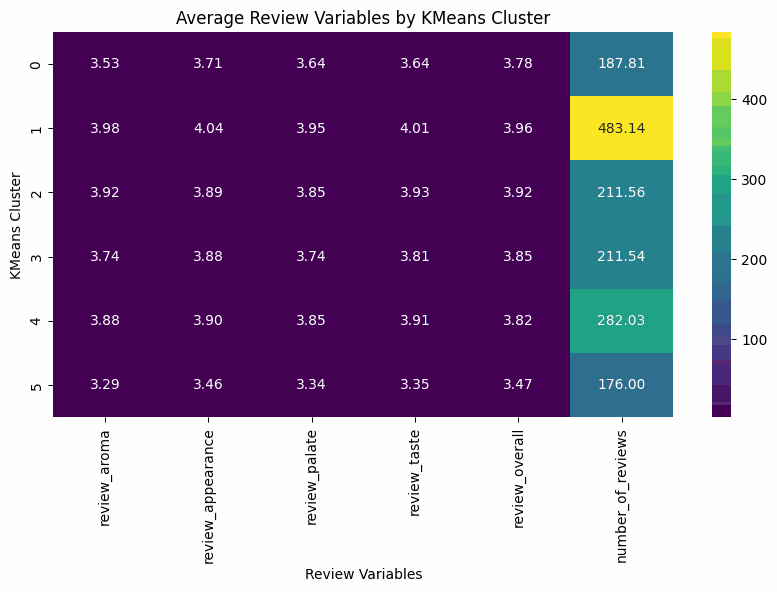

In [294]:
plt.figure(figsize=(10, 5))

sns.heatmap(
    review_summary,
    annot=True,
    cmap="viridis",
    fmt=".2f"
)

plt.title("Average Review Variables by KMeans Cluster")
plt.xlabel("Review Variables")
plt.ylabel("KMeans Cluster")
plt.show()

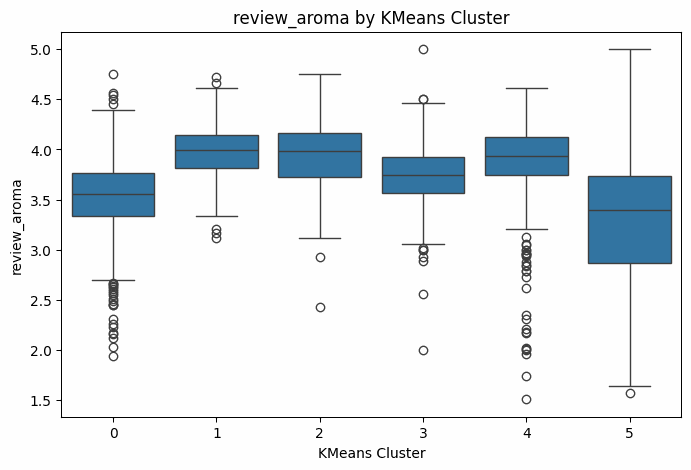

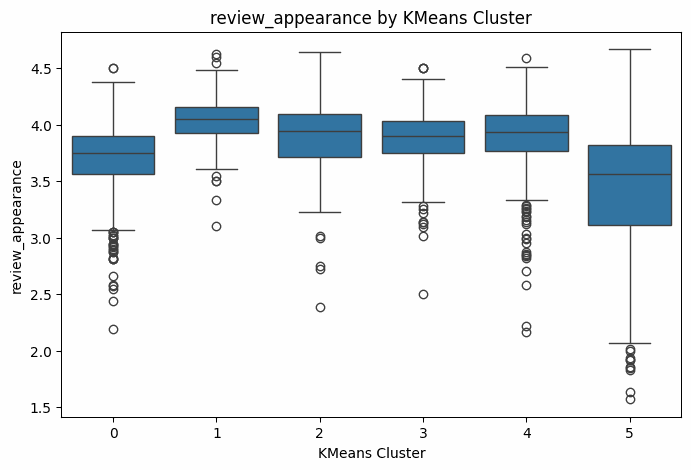

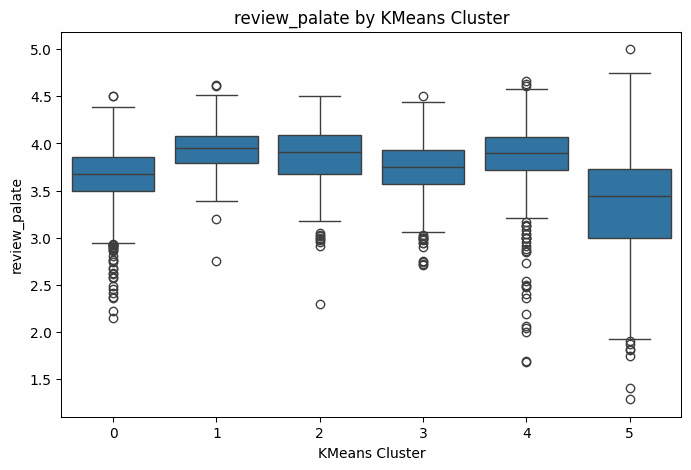

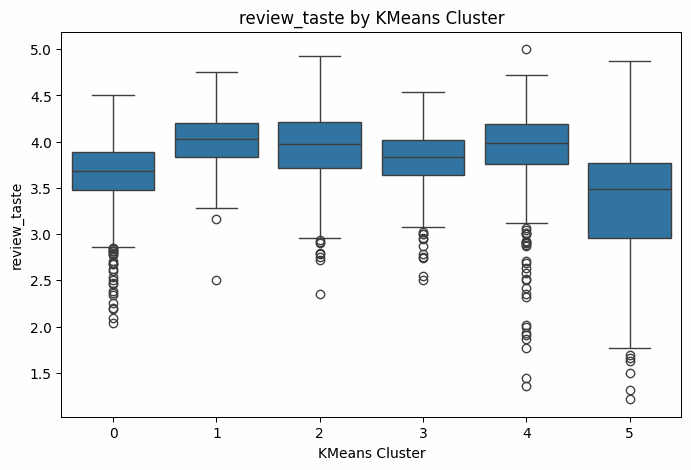

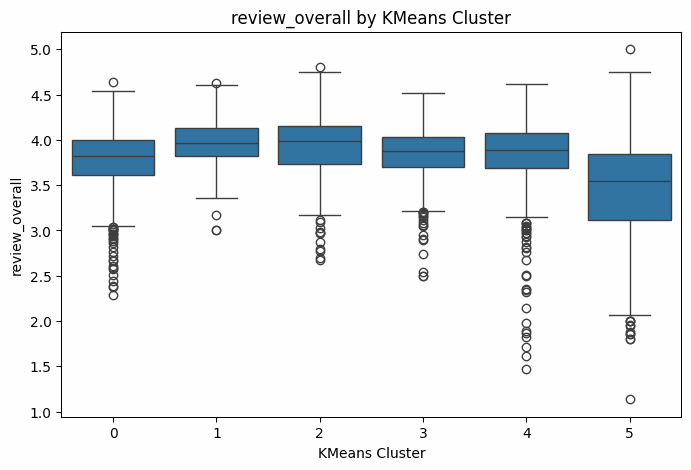

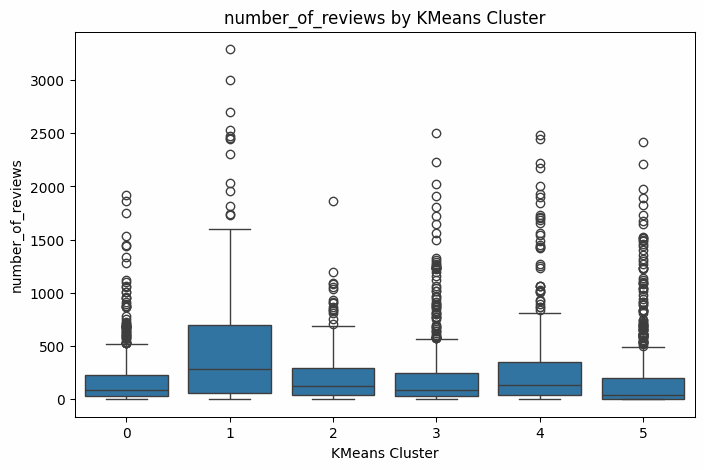

In [295]:
for col in review_cols:
    plt.figure(figsize=(8, 5))
    
    sns.boxplot(
        data=df,
        x="kmeans_final",
        y=col
    )
    
    plt.xlabel("KMeans Cluster")
    plt.ylabel(col)
    plt.title(f"{col} by KMeans Cluster")
    plt.show()

#### 9.9.1. 군집별 리뷰 해석

K-Means 군집은 리뷰 점수가 아니라 제품 특성으로 만들었지만, 군집별로 소비자 평점에 의미 있는 차이가 있었습니다.

- 군집 1, 2, 4는 향·외관·입안 느낌·맛·종합 점수의 중앙값이 모두 높아, 소비자가 대체로 더 선호하는 스타일로 보았습니다.
- 특히 군집 1은 종합 평점이 높고(평균 3.96) 리뷰 수도 가장 많아(평균 483개), 인기가 많고 널리 알려진 프리미엄 세그먼트로 판단했습니다.
- 군집 5는 거의 모든 항목에서 점수가 가장 낮고 변동도 커, 만족도가 일정하지 않거나 틈새 시장일 수 있다고 보았습니다.
- 군집 0, 3은 중간 점수로 평균적인 주류 맥주 그룹이었습니다.
- 정리하면 맥주 특성만으로 만든 군집이 소비자 평가에서도 의미 있는 차이를 보인 것으로 확인되었습니다.

## 10. 군집 방법 비교와 선택

In [ ]:
# 기법별 최종 결과 요약: 군집 크기, 평균 실루엣, 군집별 종합 평점 평균(원래 점수 기준)
labels_by_method = {
    "DBSCAN (eps=1.8, min_samples=8)": df["dbscan_final"].astype(int),
    "HAC complete linkage (k=7)": df_beer["predicted_cluster"].astype(int),
    "K-Means (k=6)": df["kmeans_final"].astype(int),
}
X_eval = df[kmeans_cols]
for method, lab in labels_by_method.items():
    mask = (lab != -1).values
    sil = silhouette_score(X_eval[mask], lab[mask])
    table = df_beer.groupby(lab.values).agg(맥주_수=("review_overall", "size"),
                                            종합평점_평균=("review_overall", "mean")).round(2)
    print(f"[{method}]  평균 실루엣(노이즈 제외) = {sil:.3f}")
    print(table.to_string())
    print()

[DBSCAN (eps=1.8, min_samples=8)]  평균 실루엣(노이즈 제외) = 0.146
    맥주_수  종합평점_평균
-1   513     3.88
 0  2649     3.72
 1    18     3.54
 2     7     4.21
 3    10     3.69

[HAC complete linkage (k=7)]  평균 실루엣(노이즈 제외) = 0.163
    맥주_수  종합평점_평균
-1   513     3.88
 0   837     3.70
 1   137     4.01
 2   298     3.84
 3   408     3.45
 4   566     3.83
 5   123     3.79
 6   315     3.68

[K-Means (k=6)]  평균 실루엣(노이즈 제외) = 0.186
   맥주_수  종합평점_평균
0   617     3.78
1   287     3.96
2   268     3.92
3   672     3.85
4   512     3.82
5   841     3.47



세 알고리즘은 서로 다른 원리를 대표합니다: DBSCAN(밀도 기반), HAC complete linkage(계층·연결 기반), K-Means(중심 기반). 연구 목표에서 정한 세 기준으로 비교했습니다. (a) t-SNE가 보여 준 내재 구조를 찾는가, (b) 이상치와 틈새 맥주를 적절히 다루는가, (c) 해석하기 쉽고 잘 분리된 세그먼트를 만드는가.

### 10.1. 알고리즘별 결과 요약

| 알고리즘 | 최종 설정 | 군집 수 | 노이즈 | 주요 근거 |
| :--- | :--- | :--- | :--- | :--- |
| DBSCAN | eps 1.8, min_samples 8 | 4 | 513 (16.0%) | 틈새 스타일을 노이즈로 명시적으로 분리. 넓게 이어진 중심과 작은 밀집 그룹 몇 개 |
| HAC complete linkage | k=7 (DBSCAN 노이즈 제외 데이터) | 7 | 사전 제외로 처리 | 대각 블록이 가장 뚜렷하고 크기가 균형 잡힘. 하위 구조 해석이 가장 풍부 |
| K-Means | k=6 | 6 | 없음 (모두 배정) | 가장 깔끔하게 나뉘고 t-SNE와 잘 맞지만 모든 맥주를 군집에 배정 |

#### 기법별 수치 정리

위 코드 출력을 바탕으로 세 방법의 결과를 정리했습니다.

| 항목 | DBSCAN (7장) | HAC complete linkage (8장) | K-Means (9장) |
|---|---|---|---|
| 사용한 데이터 | 표준화한 14개 변수, 3,197종 | DBSCAN 노이즈 513종을 뺀 2,684종 (해석 때 노이즈를 -1로 다시 포함) | 표준화한 14개 변수, 3,197종 |
| 파라미터 탐색 | eps 9개 × min_samples 4개 = 36개 조합 (7.2) | k = 2~10 (8.4, 8.7) | k = 2~15 (9.1, 9.2) |
| 최종 설정 | eps 1.8, min_samples 8 | k = 7 | k = 6 |
| 평균 실루엣 | 0.15 (노이즈 제외) | 0.16 (최고는 k=2의 0.17. 이상치 포함 시 k=2에서 0.73) | 0.19 (최고는 k=8의 0.19) |
| 군집 크기 | 2,649 / 18 / 10 / 7 + 노이즈 513 | 837 / 566 / 408 / 315 / 298 / 137 / 123 + 노이즈 513 | 841 / 672 / 617 / 512 / 287 / 268 |
| 군집별 종합 평점 평균 범위 | 3.54 ~ 4.21 (노이즈 3.88) | 3.45 ~ 4.01 (노이즈 3.88) | 3.47 ~ 3.96 |
| 평점 최고 군집 | 군집 2: 4.21, 7종 | 군집 1: 4.01, 137종 (IBU·쓴맛·홉·도수 최고) | 군집 1: 3.96, 287종 (IBU 최고) |
| 평점 최저 군집 | 군집 1: 3.54, 18종 | 군집 3: 3.45, 408종 (도수·맛 강도 최저) | 군집 5: 3.47, 841종 (IBU 최저) |
| 수치 위치 | 7.2 표, 7.11 히트맵, 10.1 출력 | 8.7 출력, 8.13 표, 10.1 출력 | 9.2 그래프, 9.9 표, 10.1 출력 |

- 실루엣 점수는 세 방법 모두 0.15~0.19로 낮았습니다. 맥주 맛이 뚜렷이 나뉘지 않고 연속적으로 이어져 있다는 5장의 관찰과 일치했습니다.
- 세 방법 모두에서 IBU·쓴맛이 높은 군집의 평점이 가장 높고, 도수·맛 강도가 낮은 군집이 가장 낮았습니다. 서로 다른 방법에서 같은 방향이 나온 것을 결과의 근거로 보았습니다.
- 평점 비교의 기준으로는 HAC를 사용했습니다. DBSCAN은 주 군집을 뺀 군집이 7~18종이어서 평점 차이가 소수의 맥주에 좌우되기 때문입니다.

### 10.2. 세 기준으로 본 비교

**내재 구조 찾기.** 세 방법 모두 큰 그림은 같았습니다. 데이터는 무작위로 흩어진 형태가 아니라 넓게 이어진 중심과 몇 개의 특화 그룹으로 이루어져 있었고, 주된 축은 IBU·쓴맛·홉, 신맛·과일 향, 바디감·몰트·단맛이었습니다. DBSCAN은 대부분을 큰 군집 하나에 넣고 가장 밀집된 부분만 떼어 냈기 때문에, K-Means(k=6)와 HAC(k=7)가 t-SNE의 분리된 영역과 조금 더 잘 맞았습니다.

**이상치와 틈새 스타일.** 방법 간 차이가 가장 큰 부분이었습니다. 틈새 맥주(예: 아메리칸 발리와인 같은 극단적 프로필)를 주류와 구분한 방법은 DBSCAN뿐이었고, 약 16%를 노이즈로 따로 표시했습니다. K-Means는 모든 맥주를 배정해야 해 이상치가 군집 중심을 왜곡했고, HAC는 더 강했지만 DBSCAN 노이즈를 미리 빼야 결과가 좋아졌습니다. 연구 목표에 "이상치·노이즈 찾기"가 명시되어 있었으므로 DBSCAN의 방식이 목표에 부합한다고 판단했습니다.

**해석 가능성과 분리.** K-Means는 가장 깔끔하고 균형 잡힌 분할을 만들어 시장 세분화에 쓰기 편했습니다. HAC k=7은 노이즈를 뺀 뒤 가장 풍부한 하위 구조(IBU가 높고 홉이 강한 인기 세그먼트, 가볍고 순한 세그먼트, 신맛·과일 향 세그먼트 등)를 보여 주었습니다. DBSCAN은 주류 중심부를 가장 덜 세분화했습니다.

### 10.3. 세 방법의 결과가 다른 이유

결과가 다르다는 것 자체가 데이터에 대한 정보라고 보았습니다. 작은 k의 높은 실루엣(예: HAC k=2의 0.73)은 이상치가 군집 간 거리를 부풀린 결과였고, 노이즈를 빼자 실루엣은 떨어졌지만 더 의미 있는 k=7이 드러났습니다. t-SNE에서 보듯 맥주 프로필은 쓴맛·단맛·몰트·도수가 *연속적으로* 변하며, 뚜렷이 떨어진 섬을 이루지 않았습니다. 그래서 중심 기반·연결 기반 방법은 이 연속체를 편리한 조각으로 자르고, DBSCAN은 정말 밀집된 부분만 떼어 내고 그 사이를 잇는 영역은 노이즈로 보았습니다. 어느 방법이 틀린 것이 아니라, 조금씩 다른 질문에 답한 것으로 해석했습니다.

### 10.4. 방법 선택

연구 목표가 (i) 내재 구조를 찾는 것**과** (ii) 모든 맥주를 억지로 세그먼트에 넣지 않고 이상치·틈새 제품을 명시적으로 찾는 것이었으므로, **DBSCAN(eps 1.8, min_samples 8)을 주 방법**으로, **HAC complete linkage(k=7)를 주류 중심부를 더 세밀하게 설명하는 보완 방법**으로 선택했습니다.

두 방법은 경쟁이 아니라 함께 사용했습니다. DBSCAN이 먼저 틈새·이상치 맥주를 분리하고, HAC가 나머지 주류 맥주를 해석 가능한 7개 세그먼트로 나눴습니다. K-Means(k=6)는 견고성 확인용으로 남겼습니다. 가정이 전혀 다른 알고리즘에서도 HAC의 주요 그룹과 비슷한 결과가 나와, 이 세그먼트가 특정 방법에서만 나타나는 결과가 아니라 실제 구조라고 판단했습니다.

## 11. 결론

### 11.1. 주요 발견

도수 사양과 맛 프로필로 설명되는 맥주 3,197종에 DBSCAN, HAC complete linkage, K-Means 세 방법을 적용했습니다. 군집이 인기가 아닌 제품 자체의 특성을 반영하도록 리뷰 변수는 군집화에서 의도적으로 제외했습니다.

1. **군집은 있었지만 연속선 위에 있었습니다.** t-SNE(perplexity 6가지 × 시드 2가지)에서 큰 중심 덩어리와 몇 개의 작은 특화 그룹(대략 4~6개 영역)이 일관되게 나타났고, 모양은 불규칙하고 길쭉하며 영역 사이가 점진적으로 이어졌습니다.
2. **구조는 해석 가능한 맛의 축으로 나뉘었습니다.** 쓴맛·홉·IBU, 신맛·과일 향, 바디감·몰트·단맛이 맥주를 가르는 주요 축이었고, 짠맛은 전체 구조에 거의 영향이 없었습니다.
3. **틈새·이상치 층이 분명히 있었습니다.** DBSCAN은 맥주의 약 16%(513종)를 노이즈로 분류했습니다. 데이터 오류가 아니라 도수·쓴맛·바디감 조합이 극단적인 개성 있는 스타일(예: 아메리칸 발리와인)이었고, 평점도 낮지 않았습니다(평균 3.88).
4. **맛 프로필 군집은 소비자 선호와 연결되었습니다.** 군집을 만들 때 평점을 전혀 쓰지 않았는데도 세그먼트별 평점이 체계적으로 달랐습니다. 홉이 두드러지면서 다른 맛이 받쳐 주는 균형 잡힌 맥주(HAC 군집 1, 평균 4.01)가 평점과 리뷰 수 모두 높았고, 밋밋하고 강도가 낮은 프로필(HAC 군집 3, 평균 3.45)이 가장 낮았습니다. 쓴맛·홉은 강하지만 다른 풍미가 부족한 맥주는 비슷하게 쓰면서 균형 잡힌 맥주보다 평점이 눈에 띄게 낮았습니다.

### 11.2. 연구 목표에 대한 답

- *주요 내재 군집 찾기* → 달성: 넓게 이어진 중심과 몇 개의 특화 그룹을 세 방법 모두에서 일관되게 확인했습니다.
- *하위 군집 구조 찾기* → 달성: HAC k=7이 주류 중심부를 더 세밀하고 해석 가능한 스타일 세그먼트로 나눴습니다.
- *이상치·노이즈 찾기* → 달성: DBSCAN이 약 16%의 틈새 맥주를 별도 층으로 분리했습니다.
- *군집 특징과 높은 평점의 이유 설명* → 달성: 단순한 강도가 아니라 균형과 풍미의 복합성이 평점이 높은 세그먼트를 구분했습니다.
- *유사성과 추천* → 일부 달성: 맛 프로필 거리 구조가 유사도 기반 추천의 근거가 될 수 있음을 확인했지만, 추천 시스템 구현은 후속 과제로 남겼습니다.

### 11.3. 비즈니스 시사점

양조장이나 제품팀 입장에서 가장 좋은 평가를 받은 영역은 쓴맛이나 도수를 극단으로 끌어올린 맥주가 아니라 **균형 잡히고 풍미가 복합적인 맥주**였습니다. 평점이 낮은 밋밋한 프로필 세그먼트는 포화되었거나 차별화가 부족한 영역으로, 틈새·이상치 층은 작지만 충성도 높은 소비자를 노리는 스페셜티 포지셔닝으로 해석했습니다. 회사는 이 세그먼트를 바탕으로 만족도는 높지만 덜 공략된 프로필을 노리거나, 경쟁이 치열한 영역에 대항 제품을 개발할 수 있다고 보았습니다. 다만 이 연결은 관찰된 연관이며, 특정 맛을 바꾸면 평점이 오른다는 인과관계는 아닙니다.

### 11.4. 한계와 후속 과제

- **거리와 변수:** 표준화한 수치형 변수의 유클리드 거리만 사용했고, 과도한 세분화를 피하려고 스타일·양조장 같은 범주형 정보는 제외했습니다. 그래서 스타일 수준의 미묘한 차이는 직접 반영하지 못했습니다.
- **변수의 편향:** 맛 프로필 변수는 리뷰 글에서 단어를 센 값이라, 리뷰 작성자의 표현 습관에 따른 편향을 그대로 가지고 있었습니다.
- **정답 k가 없음:** 영역이 이어져 있는 구조라 유일하게 "맞는" 군집 수는 없었습니다.

후속 과제로는 (a) 계획했지만 구현하지 못한 맛 프로필 유사도 기반 추천 시스템 구축, (b) 밀도가 다른 군집을 더 자연스럽게 다루는 가우시안 혼합 모델(GMM)이나 HDBSCAN 시도, (c) 스타일 라벨을 검증 기준으로 삼아 찾은 군집이 기존 맥주 스타일과 얼마나 맞는지 확인하는 작업을 정리했습니다.

## 참고문헌 (APA)

Brewers Association. (2026). *2026 Brewers Association beer style guidelines*. https://www.brewersassociation.org/edu/brewers-association-beer-style-guidelines/

Eddy, N. (2025, May 28). What are the benefits of unsupervised machine learning and clustering? *BizTech Magazine*. https://biztechmagazine.com/article/2025/05/what-are-benefits-unsupervised-machine-learning-and-clustering-perfcon

IBM. (n.d.). *What is unsupervised learning?* Retrieved May 1, 2026, from https://www.ibm.com/think/topics/unsupervised-learning

Ivanova, N., Yang, Q., Bastian, S. E. P., Wilkinson, K. L., Johnson, T. E., & Ford, R. (2023). The impact of varying key sensory attributes on consumer perception of beer body. *Food Quality and Preference, 112*, Article 105004. https://doi.org/10.1016/j.foodqual.2023.105004

Mirza, S. B. (2025, January 31). Understanding unsupervised learning through a customer segmentation analysis. *Medium*. https://medium.com/%40srayoshimirza/understanding-unsupervised-learning-through-a-customer-segmentation-analysis-0da52076c03c

National Institute of Standards and Technology. (2017). *Cluster analysis*. Dataplot reference manual. https://www.itl.nist.gov/div898/software/dataplot/refman1/auxillar/cluster.htm

Ruthgn. (n.d.). *Beer profile and ratings data set* [Data set]. Kaggle. Retrieved May 1, 2026, from https://www.kaggle.com/datasets/ruthgn/beer-profile-and-ratings-data-set

Sánchez Vinces, B. V., Schubert, E., Zimek, A., & Cordeiro, R. L. F. (2025). A comparative evaluation of clustering-based outlier detection. *Data Mining and Knowledge Discovery, 39*(2), Article 13. https://doi.org/10.1007/s10618-024-01086-z